<a href="https://colab.research.google.com/github/nuttawut7967-stack/pandas-review/blob/main/sc663402_pandas_review_673020251-6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SC 663 402 Data Warehouse and Big Data Analytics
## แบบฝึกทบทวน pandas

**ผู้สอน:** อ.ดร.พิชญา วิรัชโชติเสถียร (Pitchaya Wiratchotisatian)
**ภาควิชาสถิติ คณะวิทยาศาสตร์ มหาวิทยาลัยขอนแก่น**

---

### วัตถุประสงค์

การบ้านชุดนี้มีวัตถุประสงค์เพื่อทบทวนความรู้ pandas ที่นักศึกษาเคยศึกษามาแล้ว ให้อยู่ในระดับที่พร้อมสำหรับการวิเคราะห์ข้อมูลขนาดใหญ่ในรายวิชานี้
เนื้อหาครอบคลุมตั้งแต่โครงสร้างข้อมูลพื้นฐาน การเลือกและกรองข้อมูล การสรุปข้อมูลด้วย `groupby` การรวมตารางหลายตาราง จนถึงการสร้างกราฟจาก DataFrame

### รูปแบบ

แต่ละหัวข้อประกอบด้วยสองส่วน

1. **ตัวอย่าง** เป็นเซลล์โค้ดที่รันได้ทันที มีไว้เพื่อทบทวนรูปแบบการเรียกใช้คำสั่ง นักศึกษาควรรันและสังเกตผลลัพธ์ก่อนทำโจทย์
2. **โจทย์** เป็นแบบฝึกหัดที่มีระดับความยากสูงกว่าตัวอย่าง ไม่มีเฉลย นักศึกษาต้องเขียนคำตอบเองในเซลล์ที่เตรียมไว้

### ข้อกำหนดในการทำและการส่ง

1. เขียนคำตอบในเซลล์ที่เตรียมไว้ใต้โจทย์แต่ละข้อ
2. โจทย์ที่ระบุคำว่า **อธิบาย** ต้องตอบเป็นข้อความ การส่งเฉพาะโค้ดจะไม่ได้คะแนนในส่วนนั้น
3. ห้ามกำหนดคำตอบเป็นค่าคงที่ ทุกตัวเลขที่รายงานต้องคำนวณจากข้อมูล
4. ให้เขียนโปรแกรมในรูปแบบ vectorized เป็นหลัก หากจำเป็นต้องใช้การวนซ้ำทีละแถว ให้ระบุเหตุผลกำกับ
5. ก่อนส่งให้เลือกคำสั่ง Restart & Run All และตรวจสอบว่าไฟล์ทำงานได้ตลอดทั้งไฟล์
6. ส่งไฟล์ในรูปแบบ `.ipynb` ด้วยลิ้งก์ใน GitHub ของตนเอง

### เกณฑ์การประเมิน

* ความเรียบร้อย ครบถ้วน และความสามารถในการรันซ้ำได้

---
## ส่วนที่ 0 import libraries และ เตรียมข้อมูล

ชุดข้อมูลที่ใช้ประกอบด้วย 3 ตาราง ได้แก่ ข้อมูลสภาพอากาศรายวัน ข้อมูลเมือง และข้อมูลภูมิภาค
ให้รันเซลล์ต่อไปนี้เพื่อโหลดข้อมูลก่อนเริ่มทำการบ้าน

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
fonts-thai-tlwg is already the newest version (1:0.7.3-1).
0 upgraded, 0 newly installed, 0 to remove and 2 not upgraded.
ตั้งค่าระบบฟอนต์ภาษาไทยสำเร็จ!


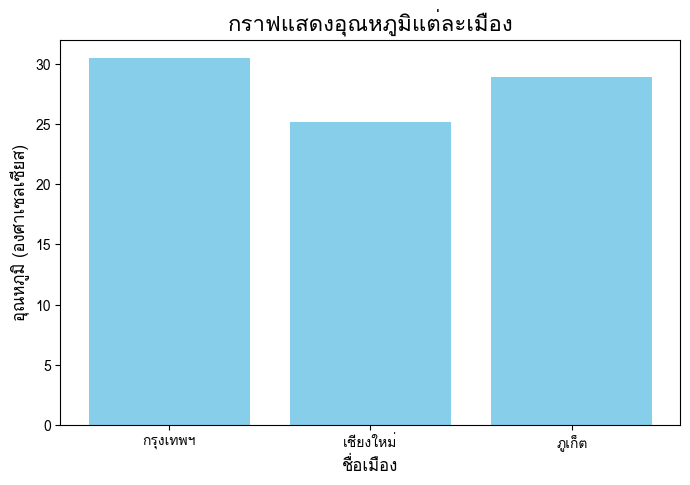

In [43]:
import pandas as pd
import numpy as np
import os, shutil
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns

# 1. ติดตั้งฟอนต์ภาษาไทย
!apt-get -y install fonts-thai-tlwg

# 2. ล้าง cache ของ matplotlib เพื่ออัปเดตฟอนต์ใหม่
cache_dir = matplotlib.get_cachedir()
if os.path.exists(cache_dir):
    shutil.rmtree(cache_dir)

# 3. ลงทะเบียนฟอนต์ใหม่เข้ากับ FontManager
font_path = '/usr/share/fonts/truetype/tlwg/Loma.ttf'
if os.path.exists(font_path):
    fm.fontManager.addfont(font_path)

# 4. ตั้งค่าฟอนต์หลัก
plt.rcParams['font.family'] = 'Loma'
plt.rcParams['axes.unicode_minus'] = False

# 5. สร้างข้อมูลจำลองและแสดงผล
data = {
    'เมือง': ['กรุงเทพฯ', 'เชียงใหม่', 'ภูเก็ต'],
    'อุณหภูมิ': [30.5, 25.2, 28.9]
}
df_thai = pd.DataFrame(data)

print("ตั้งค่าระบบฟอนต์ภาษาไทยสำเร็จ!")

plt.figure(figsize=(8, 5))
plt.bar(df_thai['เมือง'], df_thai['อุณหภูมิ'], color='skyblue')
plt.title('กราฟแสดงอุณหภูมิแต่ละเมือง', fontsize=16)
plt.xlabel('ชื่อเมือง', fontsize=12)
plt.ylabel('อุณหภูมิ (องศาเซลเซียส)', fontsize=12)
plt.show()

In [44]:
import pandas as pd
import numpy as np

BASE = ("https://raw.githubusercontent.com/PitchayaW/"
        "SC-612-104-Essential-Data-Science/refs/heads/main/Module-A-Notebooks/Dataset/")

df = pd.read_csv(BASE + "world_weather_sample.csv")
city_info = pd.read_csv(BASE + "city_info.csv")
region_info = pd.read_csv(BASE + "region_info.csv")

print("weather:", df.shape, " city_info:", city_info.shape, " region_info:", region_info.shape)
df.head()

weather: (2075, 10)  city_info: (23, 5)  region_info: (6, 3)


,record_id,date,city,country,region,temperature_c,humidity_pct,rainfall_mm,wind_speed_kmh,pressure_hpa
0,983,2025-03-24,New York,USA,North America,15.7,72.6,6.3,15.9,1005.4
1,220,2025-02-09,Tokyo,Japan,Asia,18.3,60.6,0.0,20.5,1015.1
2,1022,2025-02-01,Los Angeles,USA,North America,20.6,46.8,1.2,8.6,1013.5
3,469,2025-01-19,Mumbai,India,Asia,31.0,73.4,8.0,11.8,1000.1
4,1834,2025-02-03,Cape Town,South Africa,Africa,19.1,55.0,0.0,16.6,1015.1


---
## ข้อ 1 การเปรียบเทียบคำสั่งที่มีลักษณะใกล้เคียงกัน

**คำสั่ง:** ให้นักศึกษารันเซลล์โค้ดทั้ง 6 เซลล์ต่อไปนี้ สังเกตผลลัพธ์ที่ได้ แล้วอธิบายกับตนเองให้เข้าใจความแตกต่างของคำสั่งในแต่ละเซลล์ พร้อมระบุว่าในทางปฏิบัติควรเลือกใช้คำสั่งใดในสถานการณ์ใด

การอธิบายควรครอบคลุมทั้ง **ชนิดของผลลัพธ์** **รูปร่างของผลลัพธ์** และ **ความหมายของค่าที่ได้**

In [45]:
# เซลล์ 1.1
s = pd.Series([10, 20, 30], index=["a", "b", "c"])
print(s["a"])
print(s.iloc[0])
print(s[["a", "c"]])

10
10
a    10
c    30
dtype: int64


In [46]:
# เซลล์ 1.2
print(type(df["city"]), df["city"].shape)
print(type(df[["city"]]), df[["city"]].shape)

<class 'pandas.core.series.Series'> (2075,)
<class 'pandas.core.frame.DataFrame'> (2075, 1)


In [47]:
# เซลล์ 1.3
print(df.loc[0:3].shape)
print(df.iloc[0:3].shape)

(4, 10)
(3, 10)


In [48]:
# เซลล์ 1.4
print(df.groupby("city")["temperature_c"].count().head(3))
print(df.groupby("city").size().head(3))

city
Auckland    90
Bangkok     91
Beijing     89
Name: temperature_c, dtype: int64
city
Auckland    90
Bangkok     91
Beijing     90
dtype: int64


In [49]:
# เซลล์ 1.5
print(df.groupby("city")["temperature_c"].mean().head(3))
print(df.groupby("city")[["temperature_c"]].mean().head(3))

city
Auckland    17.804444
Bangkok     32.453846
Beijing     15.598876
Name: temperature_c, dtype: float64
          temperature_c
city                   
Auckland      17.804444
Bangkok       32.453846
Beijing       15.598876


In [50]:
# เซลล์ 1.6
a = pd.Series([1, 2, 3], index=["x", "y", "z"])
b = pd.Series([10, 20, 30], index=["z", "y", "x"])
print(a + b)
print(a.to_numpy() + b.to_numpy())

x    31
y    22
z    13
dtype: int64
[11 22 33]


---
## ข้อ 2 Series และ DataFrame

### ตัวอย่าง

In [51]:
# การสร้าง DataFrame จากโครงสร้างข้อมูลสองรูปแบบ
d1 = pd.DataFrame({"city": ["Bangkok", "Tokyo"], "temp": [30.5, 16.2]})
d2 = pd.DataFrame([{"city": "Bangkok", "temp": 30.5}, {"city": "Tokyo", "temp": 16.2}])
print(d1.equals(d2))

# การเข้าถึงองค์ประกอบของ DataFrame
print(df.columns.tolist())
print(df.index[:5].tolist())
print(df["temperature_c"].nlargest(3).tolist())

True
['record_id', 'date', 'city', 'country', 'region', 'temperature_c', 'humidity_pct', 'rainfall_mm', 'wind_speed_kmh', 'pressure_hpa']
[0, 1, 2, 3, 4]
[999.0, 999.0, 999.0]


### โจทย์ 2.1
สร้าง Series ชื่อ `rain_by_city` ซึ่งเก็บปริมาณฝนรวมของแต่ละเมือง โดยกำหนดให้ index เป็นชื่อเมือง จากนั้นตอบคำถามต่อไปนี้ด้วยโปรแกรม

1. เมืองที่มีปริมาณฝนรวมสูงสุด 3 อันดับแรก
2. สัดส่วนปริมาณฝนของแต่ละเมืองเทียบกับปริมาณฝนรวมทั้งหมด แสดงเป็นร้อยละทศนิยม 2 ตำแหน่ง
3. จำนวนเมืองที่มีปริมาณฝนรวมสูงกว่าค่าเฉลี่ยของทุกเมือง

In [52]:
# คำตอบข้อ 2.1
# หมายเหตุ: sum() ข้ามค่าว่างโดยอัตโนมัติ
rain_by_city = df.groupby("city")["rainfall_mm"].sum()

# 1) เมืองที่มีปริมาณฝนรวมสูงสุด 3 อันดับแรก
print("ปริมาณฝนรวมสูงสุด 3 อันดับแรก")
print(rain_by_city.nlargest(3).round(2))

# 2) สัดส่วนของแต่ละเมืองเทียบกับฝนรวมทั้งหมด (ร้อยละ ทศนิยม 2 ตำแหน่ง)
rain_pct = (rain_by_city / rain_by_city.sum() * 100).round(2)
print("\nสัดส่วนปริมาณฝนของแต่ละเมือง (%)")
print(rain_pct.sort_values(ascending=False))
print("ผลรวมร้อยละ (ควรเป็น 100 โดยประมาณ):", rain_pct.sum().round(2))

# 3) จำนวนเมืองที่ฝนรวมสูงกว่าค่าเฉลี่ยของทุกเมือง
n_above = (rain_by_city > rain_by_city.mean()).sum()
print(f"\nเมืองที่ฝนรวมสูงกว่าค่าเฉลี่ย: {n_above} จาก {len(rain_by_city)} เมือง")

ปริมาณฝนรวมสูงสุด 3 อันดับแรก
city
Singapore    870.4
Bangkok      685.6
Lagos        652.8
Name: rainfall_mm, dtype: float64

สัดส่วนปริมาณฝนของแต่ละเมือง (%)
city
Singapore       10.43
Bangkok          8.21
Lagos            7.82
Mumbai           5.84
Chiang Mai       5.22
Sao Paulo        5.07
Nairobi          4.74
Tokyo            4.61
Auckland         4.22
Paris            3.99
Sydney           3.97
Toronto          3.81
New York         3.78
Mexico City      3.66
Buenos Aires     3.65
London           3.27
Berlin           3.21
Beijing          3.00
Moscow           2.96
Cape Town        2.87
Lima             2.16
Los Angeles      2.03
Cairo            1.47
Name: rainfall_mm, dtype: float64
ผลรวมร้อยละ (ควรเป็น 100 โดยประมาณ): 99.99

เมืองที่ฝนรวมสูงกว่าค่าเฉลี่ย: 8 จาก 23 เมือง


### โจทย์ 2.2
สร้าง DataFrame ชื่อ `city_profile` ที่มีหนึ่งแถวต่อหนึ่งเมือง ประกอบด้วยคอลัมน์
`city`, `country`, `region`, `n_records`, `avg_temp`, `total_rain`
โดยกำหนดให้ใช้ `groupby`

In [53]:
# คำตอบข้อ 2.2
# country/region ของเมืองเดียวกันควรเหมือนกัน แต่ country มีการพิมพ์ไม่สม่ำเสมอ (ดูข้อ 4.3)
# จึงเลือกค่าที่พบบ่อยที่สุดของเมืองนั้นแทน "first" เพื่อไม่ให้ขึ้นกับลำดับแถว
def most_common(s):
    return s.mode().iat[0]

city_profile = (
    df.groupby("city")
      .agg(country=("country", most_common),
           region=("region", most_common),
           n_records=("city", "size"),
           avg_temp=("temperature_c", "mean"),
           total_rain=("rainfall_mm", "sum"))
      .reset_index()
      .round({"avg_temp": 2, "total_rain": 2})
)
print(city_profile.shape, "| จำนวนเมืองใน df:", df["city"].nunique())
city_profile.head()

(23, 6) | จำนวนเมืองใน df: 23


,city,country,region,n_records,avg_temp,total_rain
0,Auckland,New Zealand,Oceania,90,17.80,351.9
1,Bangkok,Thailand,Asia,91,32.45,685.6
2,Beijing,China,Asia,90,15.60,250.1
3,Berlin,Germany,Europe,90,12.38,268.4
4,Buenos Aires,Argentina,South America,90,19.17,305.1


---
## ข้อ 3 การนำเข้าข้อมูลด้วย `read_csv()`

### ตัวอย่าง

In [54]:
# พารามิเตอร์ที่ใช้บ่อย ได้แก่ usecols, nrows, parse_dates, dtype, na_values
preview = pd.read_csv(
    BASE + "world_weather_sample.csv",
    usecols=["city", "date", "temperature_c"],
    parse_dates=["date"],
    nrows=5,
)
print(preview.dtypes)
preview

date             datetime64[ns]
city                     object
temperature_c           float64
dtype: object


,date,city,temperature_c
0,2025-03-24,New York,15.7
1,2025-02-09,Tokyo,18.3
2,2025-02-01,Los Angeles,20.6
3,2025-01-19,Mumbai,31.0
4,2025-02-03,Cape Town,19.1


In [55]:
# การอ่านข้อมูลทีละก้อนด้วย chunksize ซึ่งคืนค่าเป็น iterator
total_rows = 0
for chunk in pd.read_csv(BASE + "world_weather_sample.csv", chunksize=500):
    total_rows += len(chunk)
print("จำนวนแถวรวม:", total_rows)

จำนวนแถวรวม: 2075


### โจทย์ 3.1
เขียนคำสั่ง `pd.read_csv()` เพียงคำสั่งเดียวที่ดำเนินการทุกข้อต่อไปนี้ให้เสร็จสิ้นตั้งแต่ขั้นตอนการนำเข้า

1. อ่านเฉพาะคอลัมน์ `date`, `city`, `region`, `temperature_c`, `humidity_pct`, `rainfall_mm`
2. แปลงคอลัมน์ `date` เป็นชนิด datetime
3. กำหนดให้ค่า `999` และ `-999` ถูกอ่านเป็นค่าว่าง
4. กำหนดชนิดข้อมูลของ `city` และ `region` เป็น `category`
5. กำหนดให้ `city` เป็น index

ให้ตรวจสอบผลด้วย `.dtypes` และ `.info()`

In [56]:
# คำตอบข้อ 3.1
FILE = BASE + "world_weather_sample.csv"

df_opt = pd.read_csv(
    FILE,
    usecols=["date", "city", "region", "temperature_c", "humidity_pct", "rainfall_mm"],  # 1
    parse_dates=["date"],                                                                # 2
    na_values=[999, -999],                                                               # 3
    dtype={"city": "category", "region": "category"},                                    # 4
    index_col="city",                                                                    # 5
)

print(df_opt.dtypes)
print()
df_opt.info(memory_usage="deep")

date             datetime64[ns]
region                 category
temperature_c           float64
humidity_pct            float64
rainfall_mm             float64
dtype: object

<class 'pandas.core.frame.DataFrame'>
CategoricalIndex: 2075 entries, New York to Paris
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   date           2075 non-null   datetime64[ns]
 1   region         2075 non-null   category      
 2   temperature_c  2052 non-null   float64       
 3   humidity_pct   1993 non-null   float64       
 4   rainfall_mm    2013 non-null   float64       
dtypes: category(1), datetime64[ns](1), float64(3)
memory usage: 71.2 KB


### โจทย์ 3.2
เปรียบเทียบปริมาณหน่วยความจำที่ใช้ระหว่างตารางที่นำเข้าตามปกติกับตารางจากโจทย์ 3.1 ด้วย `.memory_usage(deep=True)`
รายงานผลเป็นร้อยละที่ลดลง และ **อธิบาย** ว่าคอลัมน์ใดมีผลต่อการลดลงมากที่สุด เพราะเหตุใด

In [57]:
# คำตอบข้อ 3.2
df_raw = pd.read_csv(FILE)                      # นำเข้าตามปกติ ไม่กำหนดพารามิเตอร์ใด ๆ

mem_raw = df_raw.memory_usage(deep=True)        # หน่วยเป็นไบต์ (รวม Index)
mem_opt = df_opt.memory_usage(deep=True)        # city อยู่ในแถว "Index"

total_raw, total_opt = mem_raw.sum(), mem_opt.sum()
print(f"ตารางปกติ      : {total_raw/1024:,.1f} KB")
print(f"ตารางจากข้อ 3.1: {total_opt/1024:,.1f} KB")
print(f"ลดลง           : {(1 - total_opt/total_raw)*100:.1f}%")

# แยกที่มาของการลดลงเป็น 2 ส่วน
cols = ["date", "city", "region", "temperature_c", "humidity_pct", "rainfall_mm"]
opt_by_col = mem_opt.drop("Index")
opt_by_col["city"] = mem_opt["Index"]           # city ถูกย้ายไปเป็น index

cmp = pd.DataFrame({"dtype_raw": df_raw[cols].dtypes.astype(str),
                    "raw_bytes": mem_raw[cols],
                    "opt_bytes": opt_by_col[cols]})
cmp["saved_bytes"] = cmp["raw_bytes"] - cmp["opt_bytes"]
cmp["pct_saved"] = (cmp["saved_bytes"] / cmp["raw_bytes"] * 100).round(1)
print("\nส่วนที่ 1: การแปลงชนิดข้อมูลของ 6 คอลัมน์ที่ยังอ่านเข้ามา")
print(cmp.sort_values("saved_bytes", ascending=False))

dropped = mem_raw.drop(index=cols + ["Index"])
print("\nส่วนที่ 2: คอลัมน์ที่ไม่ได้อ่านเข้ามาเลย (usecols)")
print(dropped)
print("\nคอลัมน์ที่ประหยัดได้มากที่สุดในกลุ่มที่ยังอ่านเข้ามา:", cmp["saved_bytes"].idxmax())

ตารางปกติ      : 558.2 KB
ตารางจากข้อ 3.1: 71.2 KB
ลดลง           : 87.2%

ส่วนที่ 1: การแปลงชนิดข้อมูลของ 6 คอลัมน์ที่ยังอ่านเข้ามา
              dtype_raw  raw_bytes  opt_bytes  saved_bytes  pct_saved
region           object     117631       2590       115041       97.8
city             object     116920       3927       112993       96.6
date             object     122425      16600       105825       86.4
temperature_c   float64      16600      16600            0        0.0
humidity_pct    float64      16600      16600            0        0.0
rainfall_mm     float64      16600      16600            0        0.0

ส่วนที่ 2: คอลัมน์ที่ไม่ได้อ่านเข้ามาเลย (usecols)
record_id          16600
country           114937
wind_speed_kmh     16600
pressure_hpa       16600
dtype: int64

คอลัมน์ที่ประหยัดได้มากที่สุดในกลุ่มที่ยังอ่านเข้ามา: region


### โจทย์ 3.3
ใช้การอ่านข้อมูลแบบ `chunksize` เพื่อคำนวณค่าต่อไปนี้ โดยห้ามโหลดข้อมูลทั้งไฟล์เข้าหน่วยความจำพร้อมกัน และห้ามใช้ `pd.concat`

1. อุณหภูมิสูงสุดและต่ำสุดของทั้งไฟล์
2. อุณหภูมิเฉลี่ยรายเมือง

**อธิบาย:** เหตุใดการนำค่าเฉลี่ยของแต่ละก้อนมาเฉลี่ยกันอีกครั้งจึงให้ผลไม่ถูกต้อง และควรสะสมค่าใดแทนจึงจะได้ผลที่ถูกต้อง

In [58]:
# คำตอบข้อ 3.3
t_min, t_max = np.inf, -np.inf
acc = None                 # สะสม sum และ count ของอุณหภูมิรายเมือง
chunk_means = []           # เก็บไว้เพื่อสาธิตวิธีที่ผิดเท่านั้น
n_chunks = 0

for chunk in pd.read_csv(FILE, usecols=["city", "temperature_c"],
                         na_values=[999, -999], chunksize=500):
    n_chunks += 1
    t = chunk["temperature_c"]
    if t.notna().any():
        t_min, t_max = min(t_min, t.min()), max(t_max, t.max())

    g = chunk.groupby("city")["temperature_c"]
    part = g.agg(["sum", "count"])                     # count นับเฉพาะค่าที่ไม่ว่าง
    acc = part if acc is None else acc.add(part, fill_value=0)
    chunk_means.append(g.mean())

print(f"อ่านทั้งหมด {n_chunks} ก้อน")
print(f"1) อุณหภูมิสูงสุด = {t_max}, ต่ำสุด = {t_min}  (ค่า 999/-999 ถือเป็นค่าว่างตามข้อ 3.1)")

avg_by_city = (acc["sum"] / acc["count"]).rename("avg_temp")
print("\n2) อุณหภูมิเฉลี่ยรายเมือง (สะสม sum และ count)")
print(avg_by_city.round(2).sort_values(ascending=False))

# ตรวจสอบกับการคำนวณจากตารางเต็ม (ใช้ตรวจเท่านั้น ไม่ได้ใช้คำนวณคำตอบ)
full = df_opt.groupby(level="city", observed=True)["temperature_c"].mean()
print("\nตรงกับตารางเต็ม:", np.allclose(avg_by_city, full.reindex(avg_by_city.index)),
      "| max/min ตรงกัน:", (t_max == df_opt["temperature_c"].max()) and (t_min == df_opt["temperature_c"].min()))

# สาธิตวิธีที่ผิด: เฉลี่ยของค่าเฉลี่ยรายก้อน
naive = pd.DataFrame(chunk_means).mean()
diff = (naive - avg_by_city.reindex(naive.index)).abs()
print(f"\nเฉลี่ยของค่าเฉลี่ยรายก้อน คลาดเคลื่อนสูงสุด {diff.max():.4f} องศา "
      f"(เมือง {diff.idxmax()})")

อ่านทั้งหมด 5 ก้อน
1) อุณหภูมิสูงสุด = 39.2, ต่ำสุด = -88.0  (ค่า 999/-999 ถือเป็นค่าว่างตามข้อ 3.1)

2) อุณหภูมิเฉลี่ยรายเมือง (สะสม sum และ count)
city
Bangkok         32.45
Mumbai          30.87
Chiang Mai      29.68
Lagos           29.49
Singapore       29.31
Cairo           26.09
Sao Paulo       22.84
Lima            21.49
Nairobi         21.44
Los Angeles     20.66
Sydney          20.35
Mexico City     19.19
Buenos Aires    19.17
Cape Town       19.15
Tokyo           18.41
Auckland        17.80
Beijing         15.60
New York        15.48
Paris           14.75
London          13.49
Berlin          12.38
Toronto         11.61
Moscow           7.23
Name: avg_temp, dtype: float64

ตรงกับตารางเต็ม: True | max/min ตรงกัน: True

เฉลี่ยของค่าเฉลี่ยรายก้อน คลาดเคลื่อนสูงสุด 0.8910 องศา (เมือง Singapore)


---
## ข้อ 4 การสำรวจข้อมูลและการตรวจสอบคุณภาพข้อมูล

### ตัวอย่าง

In [59]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2075 entries, 0 to 2074
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   record_id       2075 non-null   int64  
 1   date            2075 non-null   object 
 2   city            2075 non-null   object 
 3   country         2075 non-null   object 
 4   region          2075 non-null   object 
 5   temperature_c   2055 non-null   float64
 6   humidity_pct    1993 non-null   float64
 7   rainfall_mm     2013 non-null   float64
 8   wind_speed_kmh  2034 non-null   float64
 9   pressure_hpa    2043 non-null   float64
dtypes: float64(5), int64(1), object(4)
memory usage: 162.2+ KB


In [60]:
print(df.describe().round(2))
print(df.describe(include="all").iloc[:4])

       record_id  temperature_c  humidity_pct  rainfall_mm  wind_speed_kmh  \
count    2075.00        2055.00       1993.00      2013.00         2034.00   
mean     1035.15          21.84         66.82         4.15           14.78   
std       598.02          38.22         13.09         3.85            5.88   
min         1.00         -88.00         21.50         0.00           -5.00   
25%       517.50          15.40         58.60         0.30           10.80   
50%      1035.00          20.00         67.10         3.50           15.00   
75%      1553.50          25.70         75.50         6.60           18.70   
max      2070.00         999.00        150.00        17.60           33.70   

       pressure_hpa  
count       2043.00  
mean        1013.13  
std            5.86  
min          993.90  
25%         1009.30  
50%         1013.10  
75%         1017.20  
max         1030.60  
        record_id        date        city   country region  temperature_c  \
count      2075.0     

In [61]:
print(df.isna().sum())
print("จำนวนแถวที่มีค่าว่างอย่างน้อยหนึ่งคอลัมน์:", df.isna().any(axis=1).sum())
print("จำนวนแถวที่ซ้ำกันทุกคอลัมน์:", df.duplicated().sum())

record_id          0
date               0
city               0
country            0
region             0
temperature_c     20
humidity_pct      82
rainfall_mm       62
wind_speed_kmh    41
pressure_hpa      32
dtype: int64
จำนวนแถวที่มีค่าว่างอย่างน้อยหนึ่งคอลัมน์: 229
จำนวนแถวที่ซ้ำกันทุกคอลัมน์: 5


### โจทย์ 4.1
สร้าง DataFrame ชื่อ `summary` ที่มีหนึ่งแถวต่อหนึ่งคอลัมน์ของ `df` ประกอบด้วย
`dtype`, `n_missing`, `pct_missing`, `n_unique`, `example_value`
โดยห้ามใช้การวนซ้ำทีละคอลัมน์ และให้เรียงลำดับจากคอลัมน์ที่มีค่าว่างมากที่สุด

In [62]:
# คำตอบข้อ 4.1
summary = (
    pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "n_missing": df.isna().sum(),
        "pct_missing": (df.isna().mean() * 100).round(2),
        "n_unique": df.nunique(),
        "example_value": df.bfill().iloc[0],
    })
    .sort_values("n_missing", ascending=False, kind="stable")
)
summary

,dtype,n_missing,pct_missing,n_unique,example_value
humidity_pct,float64,82,3.95,544,72.6
rainfall_mm,float64,62,2.99,164,6.3
wind_speed_kmh,float64,41,1.98,278,15.9
pressure_hpa,float64,32,1.54,294,1005.4
temperature_c,float64,20,0.96,331,15.7
record_id,int64,0,0.00,2070,983
date,object,0,0.00,90,2025-03-24
city,object,0,0.00,23,New York
country,object,0,0.00,28,USA
region,object,0,0.00,6,North America


### โจทย์ 4.2
ผลลัพธ์ของ `.describe()` แสดงค่าสูงสุดของ `temperature_c` และ `humidity_pct` ที่เป็นไปไม่ได้ในทางกายภาพ ให้เขียนโปรแกรมหาค่าต่อไปนี้

1. จำนวนแถวที่ `temperature_c` อยู่นอกช่วง -60 ถึง 60
2. จำนวนแถวที่ `humidity_pct` อยู่นอกช่วง 0 ถึง 100
3. จำนวนแถวที่มีความผิดปกติอย่างน้อยหนึ่งคอลัมน์ โดยระวังการนับซ้ำ

In [63]:
# คำตอบข้อ 4.2
temp_bad = (df["temperature_c"] < -60) | (df["temperature_c"] > 60)
hum_bad = (df["humidity_pct"] < 0) | (df["humidity_pct"] > 100)

print("1) temperature_c อยู่นอกช่วง -60 ถึง 60 :", temp_bad.sum(), "แถว")
print("2) humidity_pct อยู่นอกช่วง 0 ถึง 100    :", hum_bad.sum(), "แถว")

any_bad = (temp_bad | hum_bad).sum()
both_bad = (temp_bad & hum_bad).sum()
print("3) ผิดปกติอย่างน้อยหนึ่งคอลัมน์ (ใช้ OR ไม่นับซ้ำ):", any_bad, "แถว")
print("   แถวที่ผิดปกติทั้งสองคอลัมน์พร้อมกัน        :", both_bad, "แถว")
print("   ตรวจด้วยหลักการรวมและตัดออก:", temp_bad.sum() + hum_bad.sum() - both_bad == any_bad)

# ค่าที่ผิดปกติคือค่าอะไรบ้าง
print("\nค่าที่พบ (อุณหภูมิ):", sorted(df.loc[temp_bad, "temperature_c"].unique()))
print("ค่าที่พบ (ความชื้น):", sorted(df.loc[hum_bad, "humidity_pct"].unique()))

1) temperature_c อยู่นอกช่วง -60 ถึง 60 : 5 แถว
2) humidity_pct อยู่นอกช่วง 0 ถึง 100    : 3 แถว
3) ผิดปกติอย่างน้อยหนึ่งคอลัมน์ (ใช้ OR ไม่นับซ้ำ): 8 แถว
   แถวที่ผิดปกติทั้งสองคอลัมน์พร้อมกัน        : 0 แถว
   ตรวจด้วยหลักการรวมและตัดออก: True

ค่าที่พบ (อุณหภูมิ): [np.float64(-88.0), np.float64(999.0)]
ค่าที่พบ (ความชื้น): [np.float64(150.0)]


### โจทย์ 4.3
คอลัมน์ `country` มีจำนวนค่าไม่ซ้ำมากกว่าจำนวนประเทศที่มีอยู่จริง เนื่องจากการใช้ตัวพิมพ์ไม่สม่ำเสมอ

1. แสดงว่าค่าใดบ้างที่หมายถึงประเทศเดียวกันแต่ถูกนับแยกจากกัน
2. ทดลองใช้ `df["country"].str.title()` แล้ว **อธิบาย** ว่าวิธีนี้ทำให้ข้อมูลของประเทศใดเสียหาย และเพราะเหตุใด
3. เสนอและเขียนวิธี normalize ที่ถูกต้อง โดยต้องรองรับกรณีที่มีช่องว่างหัวท้ายด้วย

> **การตรวจสอบคำตอบ:** จำนวนประเทศที่ถูกต้องคือ 21 ประเทศ จากทั้งหมด 23 เมือง

In [64]:
# คำตอบข้อ 4.3
# ---- 1) ค่าที่หมายถึงประเทศเดียวกันแต่ถูกนับแยก ----
c = df["country"].value_counts().rename_axis("country_raw").reset_index(name="n_rows")
c["clean"] = c["country_raw"].str.strip().str.replace(r"\s+", " ", regex=True)   # ตัดช่องว่างหัวท้ายและช่องว่างซ้อน
c["key"] = c["clean"].str.casefold()                                              # คีย์เทียบแบบไม่สนตัวพิมพ์

print("จำนวนค่า country ที่ไม่ซ้ำ (ข้อมูลดิบ):", df["country"].nunique())
print("\nกลุ่มที่เป็นประเทศเดียวกันแต่ถูกนับแยก")
print(c[c.duplicated("key", keep=False)].sort_values(["key", "n_rows"], ascending=[True, False])
        [["country_raw", "n_rows", "key"]].to_string(index=False))

# ---- 2) ทดลอง str.title() ----
canonical = (c.groupby(["key", "clean"])["n_rows"].sum().reset_index()
              .sort_values("n_rows", ascending=False)
              .drop_duplicates("key")                    # เก็บการสะกดที่พบบ่อยที่สุดของแต่ละคีย์
              .set_index("key")["clean"])

print("\nnunique หลัง str.title():", df["country"].str.title().nunique())
broken = pd.DataFrame({"correct": canonical, "after_title": canonical.str.title()})
print("ประเทศที่ถูก title() ทำให้ชื่อเพี้ยน:")
print(broken[broken["correct"] != broken["after_title"]].to_string(index=False))

# ---- 3) normalize ที่ถูกต้อง ----
key_all = (df["country"].str.strip().str.replace(r"\s+", " ", regex=True).str.casefold())
country_clean = key_all.map(canonical)

print("\nหลัง normalize")
print("จำนวนประเทศ:", country_clean.nunique(), "| จำนวนเมือง:", df["city"].nunique())
print("แต่ละเมืองมีประเทศเดียวหรือไม่:", (df.assign(cc=country_clean).groupby("city")["cc"].nunique() == 1).all())

จำนวนค่า country ที่ไม่ซ้ำ (ข้อมูลดิบ): 28

กลุ่มที่เป็นประเทศเดียวกันแต่ถูกนับแยก
country_raw  n_rows         key
  Argentina      89   argentina
  ARGENTINA       1   argentina
     Canada      88      canada
     CANADA       2      canada
    Germany      89     germany
    GERMANY       1     germany
      Japan      89       japan
      JAPAN       1       japan
      Kenya      90       kenya
      KENYA       1       kenya
New Zealand      89 new zealand
NEW ZEALAND       1 new zealand
  Singapore      89   singapore
  SINGAPORE       1   singapore

nunique หลัง str.title(): 21
ประเทศที่ถูก title() ทำให้ชื่อเพี้ยน:
correct after_title
    USA         Usa
     UK          Uk

หลัง normalize
จำนวนประเทศ: 21 | จำนวนเมือง: 23
แต่ละเมืองมีประเทศเดียวหรือไม่: True


---
## ข้อ 5 การเลือกข้อมูลด้วย `loc` และ `iloc`

### ตัวอย่าง

In [65]:
# iloc อ้างอิงตามตำแหน่ง ส่วน loc อ้างอิงตาม label และรวมค่าปลายช่วง
print(df.iloc[0:3, 0:3].shape, df.loc[0:3, ["city", "region"]].shape)

# loc ใช้ร่วมกับเงื่อนไขและเลือกคอลัมน์ได้ในคำสั่งเดียว
print(df.loc[df["temperature_c"] > 35, ["city", "date", "temperature_c"]].head(3))

(3, 3) (4, 2)
          city        date  temperature_c
78   Cape Town  2025-02-10          999.0
161    Bangkok  2025-02-14           38.6
325     Mumbai  2025-03-31           35.6


In [66]:
# การกำหนด index หลายระดับ และการเลือกข้อมูลจาก index หลายระดับ
multi = df.set_index(["region", "city"]).sort_index()
print(multi.loc["Asia"].shape)
print(multi.loc[("Asia", "Tokyo"), ["date", "temperature_c"]].head(3))

(542, 8)
                    date  temperature_c
region city                            
Asia   Tokyo  2025-02-09           18.3
       Tokyo  2025-03-21           19.7
       Tokyo  2025-03-23           17.7


### โจทย์ 5.1
ใช้ `.iloc[]` เท่านั้น โดยห้ามอ้างอิงชื่อคอลัมน์ เพื่อดึงข้อมูลต่อไปนี้

1. แถวที่อยู่ในตำแหน่งเลขคู่ 10 แถวแรก เฉพาะสามคอลัมน์สุดท้าย
2. ห้าแถวสุดท้าย โดยเรียงลำดับจากแถวล่างสุดขึ้นไป
3. ค่าเดี่ยวที่อยู่ในแถวกึ่งกลางตารางและคอลัมน์สุดท้าย โดยต้องคำนวณตำแหน่งกึ่งกลางจากจำนวนแถว

In [67]:
# คำตอบข้อ 5.1
# 1) แถวตำแหน่งเลขคู่ 10 แถวแรก (ตำแหน่ง 0,2,...,18) เฉพาะสามคอลัมน์สุดท้าย
a1 = df.iloc[0:20:2, -3:]
print(a1)

# 2) ห้าแถวสุดท้าย เรียงจากแถวล่างสุดขึ้นไป
a2 = df.iloc[:-6:-1]
print(a2)

# 3) ค่าเดี่ยวในแถวกึ่งกลางและคอลัมน์สุดท้าย (คำนวณตำแหน่งกึ่งกลางจากจำนวนแถว)
mid = len(df) // 2
a3 = df.iloc[mid, -1]
print(f"\nแถวกึ่งกลาง = ตำแหน่ง {mid} จาก {len(df)} แถว, ค่า = {a3}")

    rainfall_mm  wind_speed_kmh  pressure_hpa
0           6.3            15.9        1005.4
2           1.2             8.6        1013.5
4           0.0            16.6        1015.1
6           2.7            14.6        1018.0
8           1.6             9.8        1007.7
10          0.0            15.6        1010.1
12          0.0            13.6        1015.8
14          2.2            24.6        1000.5
16          8.3             9.3        1019.4
18          8.9            23.3        1020.6
      record_id        date         city country         region  \
2074        642  2025-01-12        Paris  France         Europe   
2073       1210  2025-02-09      Toronto  Canada  North America   
2072       1738  2025-01-28      Nairobi   Kenya         Africa   
2071       1769  2025-02-28      Nairobi   Kenya         Africa   
2070       1093  2025-01-13  Mexico City  Mexico  North America   

      temperature_c  humidity_pct  rainfall_mm  wind_speed_kmh  pressure_hpa  
2074        

### โจทย์ 5.2
จาก DataFrame ที่กำหนด index เป็นคู่ `(region, city)` ให้ดึงข้อมูลต่อไปนี้ด้วย `.loc[]`

1. ข้อมูลทั้งหมดของภูมิภาค Asia เฉพาะคอลัมน์ `date` และ `temperature_c`
2. ข้อมูลของเมือง Tokyo และ Bangkok พร้อมกันในคำสั่งเดียว
3. ข้อมูลของทุกภูมิภาค แต่เฉพาะเมืองที่ชื่อขึ้นต้นด้วยตัวอักษร B

**อธิบาย:** เหตุใดจึงควรเรียงลำดับ index ด้วย `.sort_index()` ก่อนใช้งาน index หลายระดับ

In [68]:
# คำตอบข้อ 5.2
multi = df.set_index(["region", "city"]).sort_index()      # เรียงก่อนใช้ MultiIndex เสมอ
idx = pd.IndexSlice

# 1) ทุกแถวของ Asia เฉพาะ date และ temperature_c
q1 = multi.loc["Asia", ["date", "temperature_c"]]
print(q1.shape)

# 2) Tokyo และ Bangkok พร้อมกันในคำสั่งเดียว
q2 = multi.loc[idx[:, ["Tokyo", "Bangkok"]], :]
print(q2.index.get_level_values("city").unique().tolist())

# 3) ทุกภูมิภาค เฉพาะเมืองที่ชื่อขึ้นต้นด้วย B (slice ตามช่วงตัวอักษร ต้องอาศัย index ที่เรียงแล้ว)
q3 = multi.loc[idx[:, "B":"B\uffff"], :]
print(q3.index.get_level_values("city").unique().tolist())

# ตรวจกับวิธี boolean mask ว่าได้จำนวนแถวเท่ากัน
mask = multi.index.get_level_values("city").str.startswith("B")
print("ตรงกับ boolean mask:", len(q3) == mask.sum())

# สาธิตว่าถ้าไม่ sort_index จะเกิดอะไรขึ้น
unsorted = df.set_index(["region", "city"])
try:
    unsorted.loc[idx[:, "B":"B\uffff"], :]
except Exception as e:
    print("\nindex ไม่เรียง ->", type(e).__name__ + ":", e)

(542, 2)
['Tokyo', 'Bangkok']
['Bangkok', 'Beijing', 'Berlin', 'Buenos Aires']
ตรงกับ boolean mask: True

index ไม่เรียง -> UnsortedIndexError: 'MultiIndex slicing requires the index to be lexsorted: slicing on levels [1], lexsort depth 0'


### โจทย์ 5.3
ให้รันโปรแกรมต่อไปนี้ แล้วสังเกตผลที่เกิดขึ้นกับ `df`

```python
subset = df[df["city"] == "Bangkok"]
subset["temperature_c"] = 0
```

จากนั้นเขียนโปรแกรมที่ถูกต้องสองรูปแบบ ได้แก่ รูปแบบที่ต้องการแก้ไข `df` จริง และรูปแบบที่ต้องการทำงานกับสำเนาแยกต่างหาก
พร้อมสรุปเป็นแนวปฏิบัติของตนเองความยาว 2 ถึง 3 บรรทัด

In [69]:
# คำตอบข้อ 5.3
import warnings

# ---- ส่วนที่ 1: รันโปรแกรมตามโจทย์และสังเกตผล (แบบที่ไม่ควรทำ) ----
before = df.loc[df["city"] == "Bangkok", "temperature_c"].sum()
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")
    subset = df[df["city"] == "Bangkok"]
    subset["temperature_c"] = 0                   # chained assignment
print("คำเตือนที่เกิดขึ้น:", [x.category.__name__ for x in w] or "ไม่มี (pandas รุ่นใหม่ใช้ Copy-on-Write)")
print("subset เปลี่ยนเป็น 0 แล้ว:", (subset["temperature_c"] == 0).all())
print("df ของ Bangkok ยังเหมือนเดิมหรือไม่:", df.loc[df["city"] == "Bangkok", "temperature_c"].sum() == before)

# ---- ส่วนที่ 2a: ต้องการแก้ df จริง -> ใช้ .loc ในคำสั่งเดียว ----
# (ทำบน df_demo เพื่อไม่ให้ข้อมูลหลักที่ใช้ในข้อถัดไปถูกเปลี่ยน ในงานจริงให้แก้ที่ df ได้เลย)
df_demo = df.copy()
df_demo.loc[df_demo["city"] == "Bangkok", "temperature_c"] = 0
print("\n[2a] แก้ df จริงด้วย .loc: Bangkok ทุกแถวเป็น 0:",
      (df_demo.loc[df_demo["city"] == "Bangkok", "temperature_c"] == 0).all())

# ---- ส่วนที่ 2b: ต้องการสำเนาแยกต่างหาก -> .copy() ก่อนแก้ ----
bkk_copy = df[df["city"] == "Bangkok"].copy()
bkk_copy["temperature_c"] = 0
print("[2b] แก้สำเนา bkk_copy แล้ว df ต้นฉบับไม่เปลี่ยน:",
      df.loc[df["city"] == "Bangkok", "temperature_c"].sum() == before)

คำเตือนที่เกิดขึ้น: ['SettingWithCopyWarning']
subset เปลี่ยนเป็น 0 แล้ว: True
df ของ Bangkok ยังเหมือนเดิมหรือไม่: True

[2a] แก้ df จริงด้วย .loc: Bangkok ทุกแถวเป็น 0: True
[2b] แก้สำเนา bkk_copy แล้ว df ต้นฉบับไม่เปลี่ยน: True


---
## ข้อ 6 การกรองข้อมูลด้วยเงื่อนไข

### ตัวอย่าง

In [70]:
# การใช้ตัวดำเนินการ & | ~ ต้องครอบวงเล็บทุกเงื่อนไข
print(len(df[(df["temperature_c"] > 28) & (df["humidity_pct"] > 70)]))
print(len(df[~df["city"].isin(["Bangkok", "Tokyo"])]))
print(len(df[df["temperature_c"].between(20, 30)]))
print(len(df.query("region == 'Asia' and rainfall_mm > 5")))

237
1894
757
295


In [71]:
# where และ mask ไม่ลดจำนวนแถว แต่แทนค่าที่ไม่ตรงเงื่อนไขด้วยค่าที่กำหนด
temp_valid = df["temperature_c"].where(df["temperature_c"].between(-60, 60))
rain_capped = df["rainfall_mm"].mask(df["rainfall_mm"] > 15, 15)
print(temp_valid.isna().sum(), df["temperature_c"].isna().sum())
print(rain_capped.max(), df["rainfall_mm"].max())

25 20
15.0 17.6


In [72]:
# pipe ใช้ต่อขั้นตอนการประมวลผลหลายขั้นให้เป็นลำดับเดียว
def add_flag(data, threshold):
    return data.assign(is_hot=data["temperature_c"] > threshold)

result = (df
          .query("region == 'Asia'")
          .pipe(add_flag, threshold=30)
          .loc[:, ["city", "temperature_c", "is_hot"]])
print(result.head(3))

       city  temperature_c  is_hot
1     Tokyo           18.3   False
3    Mumbai           31.0    True
12  Beijing           14.3   False


### โจทย์ 6.1
เขียนเงื่อนไขสำหรับกรองข้อมูลต่อไปนี้

1. ข้อมูลในภูมิภาคเอเชียที่ปริมาณฝนมากกว่า 5 มิลลิเมตร และความเร็วลมมากกว่า 20 กิโลเมตรต่อชั่วโมง
2. ข้อมูลที่ไม่ใช่เมือง Bangkok, Tokyo และ London และมีความชื้นระหว่าง 40 ถึง 60
3. แถวที่มีค่าว่างตั้งแต่ 2 คอลัมน์ขึ้นไป
4. แถวที่ชื่อเมืองมีคำว่า New หรือ San ประกอบอยู่ โดยใช้ `.str.contains` ร่วมกับ regular expression

In [73]:
# คำตอบข้อ 6.1
# 1) เอเชีย ฝน > 5 มม. และลม > 20 กม./ชม.
f1 = df[(df["region"] == "Asia") & (df["rainfall_mm"] > 5) & (df["wind_speed_kmh"] > 20)]

# 2) ไม่ใช่ Bangkok, Tokyo, London และความชื้นระหว่าง 40 ถึง 60 (between รวมปลายช่วง)
f2 = df[~df["city"].isin(["Bangkok", "Tokyo", "London"]) & df["humidity_pct"].between(40, 60)]

# 3) แถวที่มีค่าว่างตั้งแต่ 2 คอลัมน์ขึ้นไป
f3 = df[df.isna().sum(axis=1) >= 2]

# 4) ชื่อเมืองมีคำว่า New หรือ San  (\b คือขอบเขตของคำ จึงไม่ติดชื่ออย่าง Santiago หรือ Newcastle)
f4 = df[df["city"].str.contains(r"\b(?:New|San)\b", regex=True, na=False)]

for name, f in [("1", f1), ("2", f2), ("3", f3), ("4", f4)]:
    print(f"ข้อ {name}: {len(f)} แถว")
print("\nเมืองที่เข้าเงื่อนไขข้อ 4:", sorted(f4["city"].unique()))
print("ถ้าไม่ใช้ \\b จะได้เมือง:", sorted(df.loc[df["city"].str.contains(r"New|San", na=False), "city"].unique()))

ข้อ 1: 54 แถว
ข้อ 2: 470 แถว
ข้อ 3: 8 แถว
ข้อ 4: 90 แถว

เมืองที่เข้าเงื่อนไขข้อ 4: ['New York']
ถ้าไม่ใช้ \b จะได้เมือง: ['New York']


### โจทย์ 6.2
ใช้ `.where()` และ `.mask()` สร้างคอลัมน์ใหม่สองคอลัมน์ ได้แก่ คอลัมน์อุณหภูมิที่แทนค่าผิดปกติด้วยค่าว่าง และคอลัมน์ปริมาณฝนที่จำกัดค่าสูงสุดไว้ที่ค่าเปอร์เซ็นไทล์ที่ 99
**อธิบาย:** แนวทางนี้แตกต่างจากการลบแถวทิ้งอย่างไรในแง่ของการวิเคราะห์ในขั้นถัดไป

In [74]:
# คำตอบข้อ 6.2
p99 = df["rainfall_mm"].quantile(0.99)

df_q62 = df.assign(
    # where: คงค่าไว้เมื่อเงื่อนไขเป็นจริง นอกนั้นแทนด้วยค่าว่าง
    temp_valid=df["temperature_c"].where(df["temperature_c"].between(-60, 60)),
    # mask: แทนค่าเมื่อเงื่อนไขเป็นจริง (ฝนเกิน p99 ให้เท่ากับ p99)
    rain_capped=df["rainfall_mm"].mask(df["rainfall_mm"] > p99, p99),
)

print("จำนวนแถว:", len(df), "->", len(df_q62))
print("temperature_c ค่าว่าง:", df["temperature_c"].isna().sum(), "->", df_q62["temp_valid"].isna().sum())
print(f"rainfall_mm สูงสุด: {df['rainfall_mm'].max()} -> {df_q62['rain_capped'].max()} (p99 = {p99:.2f})")
df_q62[["city", "temperature_c", "temp_valid", "rainfall_mm", "rain_capped"]].head()


จำนวนแถว: 2075 -> 2075
temperature_c ค่าว่าง: 20 -> 25
rainfall_mm สูงสุด: 17.6 -> 14.687999999999988 (p99 = 14.69)


,city,temperature_c,temp_valid,rainfall_mm,rain_capped
0,New York,15.7,15.7,6.3,6.3
1,Tokyo,18.3,18.3,0.0,0.0
2,Los Angeles,20.6,20.6,1.2,1.2
3,Mumbai,31.0,31.0,8.0,8.0
4,Cape Town,19.1,19.1,0.0,0.0


### โจทย์ 6.3
หาวันที่มีอุณหภูมิห่างจากค่าเฉลี่ยของเมืองตนเองมากที่สุดของแต่ละเมือง
ผลลัพธ์ต้องมีหนึ่งแถวต่อหนึ่งเมือง ประกอบด้วยคอลัมน์ `city`, `date`, `temperature_c`, `deviation`

In [75]:
# คำตอบข้อ 6.3
# ค่า 999/-999 ไม่ใช่อุณหภูมิจริง จึงตัดออก (เป็นค่าว่าง) ก่อนหาค่าเฉลี่ยและส่วนเบี่ยงเบน
temp_ok = df["temperature_c"].where(df["temperature_c"].between(-60, 60))
deviation = temp_ok - temp_ok.groupby(df["city"]).transform("mean")

tmp = df.assign(deviation=deviation, abs_dev=deviation.abs())
idx = tmp.groupby("city")["abs_dev"].idxmax()          # ตำแหน่งแถวที่ห่างมากที่สุดของแต่ละเมือง

extreme_day = (tmp.loc[idx, ["city", "date", "temperature_c", "deviation"]]
                  .reset_index(drop=True)
                  .round({"deviation": 2}))
print(extreme_day.shape)
extreme_day


(23, 4)


,city,date,temperature_c,deviation
0,Auckland,2025-02-27,25.6,7.80
1,Bangkok,2025-03-26,39.1,6.65
2,Beijing,2025-03-06,22.6,7.00
3,Berlin,2025-03-26,19.4,7.02
4,Buenos Aires,2025-01-02,12.2,-8.19
5,Cairo,2025-03-31,33.6,7.51
6,Cape Town,2025-03-23,25.5,6.35
7,Chiang Mai,2025-03-28,37.3,7.62
8,Lagos,2025-01-01,21.1,-8.39
9,Lima,2025-01-22,12.9,-8.59


---
## ข้อ 7 การจัดการข้อมูลวันที่และเวลา

### ตัวอย่าง

In [76]:
df["date"] = pd.to_datetime(df["date"])
print(df["date"].dt.month.head(3).tolist())
print(df["date"].dt.day_name().head(3).tolist())
print(df["date"].min(), df["date"].max())

# assign ใช้สร้างหลายคอลัมน์ในคำสั่งเดียวและคืนค่าเป็น DataFrame ใหม่
tmp = df.assign(
    year_month=df["date"].dt.to_period("M").astype(str),
    is_weekend=df["date"].dt.dayofweek >= 5,
)
print(tmp[["date", "year_month", "is_weekend"]].head(3))

[3, 2, 2]
['Monday', 'Sunday', 'Saturday']
2025-01-01 00:00:00 2025-03-31 00:00:00
        date year_month  is_weekend
0 2025-03-24    2025-03       False
1 2025-02-09    2025-02        True
2 2025-02-01    2025-02        True


In [77]:
# resample สรุปข้อมูลตามช่วงเวลา โดยต้องกำหนด index เป็น datetime ก่อน
bkk = df[df["city"] == "Bangkok"].set_index("date").sort_index()
print(bkk["temperature_c"].resample("7D").mean().head(4).round(2))

date
2025-01-01    30.36
2025-01-08    31.09
2025-01-15    30.39
2025-01-22    32.29
Freq: 7D, Name: temperature_c, dtype: float64


### โจทย์ 7.1
ใช้ `.assign()` เพียงคำสั่งเดียวสร้างคอลัมน์ `year_month`, `week_of_year`, `day_name` และ `is_weekend`

In [78]:
# คำตอบข้อ 7.1
# ใน assign() ตัวแปรที่อยู่ก่อนหน้าถูกใช้ต่อได้ จึงแปลง date ให้เป็น datetime ในคำสั่งเดียวกัน
df_time = df.assign(
    date=lambda x: pd.to_datetime(x["date"]),
    year_month=lambda x: x["date"].dt.to_period("M").astype(str),
    week_of_year=lambda x: x["date"].dt.isocalendar().week.astype(int),
    day_name=lambda x: x["date"].dt.day_name(),
    is_weekend=lambda x: x["date"].dt.dayofweek >= 5,
)
df_time[["date", "year_month", "week_of_year", "day_name", "is_weekend"]].head()

,date,year_month,week_of_year,day_name,is_weekend
0,2025-03-24,2025-03,13,Monday,False
1,2025-02-09,2025-02,6,Sunday,True
2,2025-02-01,2025-02,5,Saturday,True
3,2025-01-19,2025-01,3,Sunday,True
4,2025-02-03,2025-02,6,Monday,False


### โจทย์ 7.2
ตอบคำถามต่อไปนี้ด้วยโปรแกรม

1. ข้อมูลครอบคลุมทั้งหมดกี่วัน และมีวันใดในช่วงดังกล่าวที่ไม่มีข้อมูลเลยหรือไม่ โดยใช้ `pd.date_range` ประกอบการตรวจสอบ
2. อุณหภูมิเฉลี่ยของวันหยุดสุดสัปดาห์เปรียบเทียบกับวันธรรมดา จำแนกตามภูมิภาค
3. เดือนที่มีปริมาณฝนรวมสูงสุดของแต่ละเมือง

In [79]:
# คำตอบข้อ 7.2
# ---- 1) ช่วงเวลาที่ข้อมูลครอบคลุม และวันที่ไม่มีข้อมูลเลย ----
d_min, d_max = df_time["date"].min(), df_time["date"].max()
n_span = (d_max - d_min).days + 1
full_range = pd.date_range(d_min, d_max, freq="D")
missing_days = full_range.difference(pd.DatetimeIndex(df_time["date"].unique()))

print(f"1) ตั้งแต่ {d_min.date()} ถึง {d_max.date()} รวม {n_span} วัน")
print(f"   วันที่มีข้อมูลอย่างน้อยหนึ่งแถว: {df_time['date'].nunique()} วัน")
print("   วันที่ไม่มีข้อมูลเลย:", list(missing_days.date) if len(missing_days) else "ไม่มี")

# ---- 2) อุณหภูมิเฉลี่ยวันหยุดสุดสัปดาห์เทียบกับวันธรรมดา แยกตามภูมิภาค ----
temp_ok = df_time["temperature_c"].where(df_time["temperature_c"].between(-60, 60))  # ตัด 999/-999 ออก
wk = (df_time.assign(temp_ok=temp_ok)
             .groupby(["region", "is_weekend"])["temp_ok"].mean()
             .unstack()
             .rename(columns={False: "weekday", True: "weekend"}))
wk["weekend_minus_weekday"] = wk["weekend"] - wk["weekday"]
print("\n2) อุณหภูมิเฉลี่ย (องศาเซลเซียส)")
print(wk.round(2))

# ---- 3) เดือนที่ฝนรวมสูงสุดของแต่ละเมือง ----
monthly_rain = df_time.groupby(["city", "year_month"], as_index=False)["rainfall_mm"].sum()
top_month = (monthly_rain.loc[monthly_rain.groupby("city")["rainfall_mm"].idxmax()]
                         .reset_index(drop=True)
                         .round({"rainfall_mm": 1}))
print("\n3) เดือนที่ฝนรวมสูงสุดของแต่ละเมือง")
print(top_month)


1) ตั้งแต่ 2025-01-01 ถึง 2025-03-31 รวม 90 วัน
   วันที่มีข้อมูลอย่างน้อยหนึ่งแถว: 90 วัน
   วันที่ไม่มีข้อมูลเลย: ไม่มี

2) อุณหภูมิเฉลี่ย (องศาเซลเซียส)
is_weekend     weekday  weekend  weekend_minus_weekday
region                                                
Africa           24.08    23.88                  -0.19
Asia             26.25    26.53                   0.28
Europe           11.93    11.95                   0.02
North America    16.72    16.84                   0.13
Oceania          18.94    19.40                   0.46
South America    21.70    21.26                  -0.44

3) เดือนที่ฝนรวมสูงสุดของแต่ละเมือง
            city year_month  rainfall_mm
0       Auckland    2025-03        150.0
1        Bangkok    2025-02        243.9
2        Beijing    2025-02         87.4
3         Berlin    2025-03        100.1
4   Buenos Aires    2025-02        121.2
5          Cairo    2025-02         48.0
6      Cape Town    2025-01         98.3
7     Chiang Mai    2025-03        188.

### โจทย์ 7.3
ใช้ `.resample()` สรุปข้อมูลของเมือง Bangkok เป็นราย 7 วัน โดยแสดงอุณหภูมิเฉลี่ยและปริมาณฝนรวมในตารางเดียวกัน
**อธิบาย:** `.resample()` แตกต่างจาก `groupby(df["date"].dt.month)` อย่างไร และกรณีใดที่จำเป็นต้องใช้ `.resample()` เท่านั้น

In [80]:
# คำตอบข้อ 7.3
bkk7 = (df_time[df_time["city"] == "Bangkok"]
        .assign(temp_ok=lambda x: x["temperature_c"].where(x["temperature_c"].between(-60, 60)))
        .set_index("date")
        .sort_index())

weekly = (bkk7.resample("7D")
              .agg(avg_temp=("temp_ok", "mean"), total_rain=("rainfall_mm", "sum"))
              .round(2))
print(weekly.shape)
weekly

(13, 2)


,avg_temp,total_rain
date,,
2025-01-01,30.36,65.7
2025-01-08,31.09,47.6
2025-01-15,30.39,58.7
2025-01-22,32.29,50.0
2025-01-29,31.76,55.4
2025-02-05,33.03,65.1
2025-02-12,34.21,60.2
2025-02-19,32.30,42.5
2025-02-26,32.34,61.7


---
## ข้อ 8 การจัดการค่าว่างและข้อมูลซ้ำ

### ตัวอย่าง

In [81]:
# การเติมค่าว่างด้วยค่าสถิติของกลุ่มตนเอง โดยใช้ transform
filled_by_city = df["temperature_c"].fillna(
    df.groupby("city")["temperature_c"].transform("mean")
)
print(df["temperature_c"].isna().sum(), "->", filled_by_city.isna().sum())

# การเติมค่าด้วยค่าของวันก่อนหน้าภายในเมืองเดียวกัน
sorted_df = df.sort_values(["city", "date"])
ffilled = sorted_df.groupby("city")["temperature_c"].ffill()
print("หลังเติมแบบ ffill เหลือค่าว่าง:", ffilled.isna().sum())

20 -> 0
หลังเติมแบบ ffill เหลือค่าว่าง: 0


In [82]:
# การตรวจสอบข้อมูลซ้ำตามคีย์ที่กำหนด
print("ซ้ำทุกคอลัมน์:", df.duplicated().sum())
print("ซ้ำตามคีย์ (city, date):", df.duplicated(subset=["city", "date"]).sum())
print("จำนวนแถวหลังขจัดข้อมูลซ้ำ:", df.drop_duplicates().shape[0])

ซ้ำทุกคอลัมน์: 5
ซ้ำตามคีย์ (city, date): 5
จำนวนแถวหลังขจัดข้อมูลซ้ำ: 2070


### โจทย์ 8.1
ตอบคำถามต่อไปนี้ด้วยโปรแกรม

1. คอลัมน์ใดมีค่าว่างมากที่สุด และคิดเป็นร้อยละเท่าใด
2. ค่าว่างกระจายตัวเท่ากันทุกเมืองหรือไม่ ให้สร้างตารางแสดงสัดส่วนค่าว่างของ `temperature_c` จำแนกตามเมือง
3. หากลบทุกแถวที่มีค่าว่างด้วย `dropna()` จะเหลือข้อมูลคิดเป็นร้อยละเท่าใดของข้อมูลเดิม และเมืองใดสูญเสียข้อมูลมากที่สุด

In [83]:
# คำตอบข้อ 8.1
# ---- 1) คอลัมน์ที่มีค่าว่างมากที่สุด ----
miss_pct = df.isna().mean() * 100
col_max = miss_pct.idxmax()
print(f"1) {col_max}: {df[col_max].isna().sum()} แถว คิดเป็น {miss_pct[col_max]:.2f}%")

# ---- 2) สัดส่วนค่าว่างของ temperature_c จำแนกตามเมือง ----
temp_miss_by_city = (df["temperature_c"].isna().groupby(df["city"]).mean()
                       .mul(100).round(2)
                       .sort_values(ascending=False)
                       .rename("pct_missing_temp").to_frame())
print("\n2) สัดส่วนค่าว่างของ temperature_c รายเมือง (%)")
print(temp_miss_by_city)
rate = temp_miss_by_city["pct_missing_temp"]
print(f"   ต่ำสุด {rate.min()}% | สูงสุด {rate.max()}% | ส่วนเบี่ยงเบนมาตรฐาน {rate.std():.2f}")
print("   สรุป:", "เท่ากันทุกเมือง" if rate.nunique() == 1 else "ไม่เท่ากันทุกเมือง")

# ---- 3) ผลของการ dropna() ----
pct_kept = len(df.dropna()) / len(df) * 100
print(f"\n3) dropna() แล้วเหลือ {len(df.dropna())} จาก {len(df)} แถว = {pct_kept:.2f}% ของข้อมูลเดิม")

lost = (df.isna().any(axis=1).groupby(df["city"])
          .agg(rows_lost="sum", pct_lost="mean"))
lost["pct_lost"] = (lost["pct_lost"] * 100).round(2)
print(lost.sort_values("rows_lost", ascending=False).head(5))
print(f"   เสียข้อมูลมากที่สุดโดยจำนวนแถว: {lost['rows_lost'].idxmax()} ({lost['rows_lost'].max()} แถว)")
print(f"   เสียข้อมูลมากที่สุดโดยร้อยละ  : {lost['pct_lost'].idxmax()} ({lost['pct_lost'].max()}%)")


1) humidity_pct: 82 แถว คิดเป็น 3.95%

2) สัดส่วนค่าว่างของ temperature_c รายเมือง (%)
              pct_missing_temp
city                          
Lagos                     3.33
London                    2.22
Toronto                   2.22
Tokyo                     2.22
Cairo                     2.20
Berlin                    1.11
Beijing                   1.11
Paris                     1.11
Sao Paulo                 1.11
Cape Town                 1.11
Buenos Aires              1.11
Los Angeles               1.11
Moscow                    1.10
Nairobi                   1.10
Bangkok                   0.00
Auckland                  0.00
Mexico City               0.00
Chiang Mai                0.00
Lima                      0.00
Mumbai                    0.00
New York                  0.00
Sydney                    0.00
Singapore                 0.00
   ต่ำสุด 0.0% | สูงสุด 3.33% | ส่วนเบี่ยงเบนมาตรฐาน 0.96
   สรุป: ไม่เท่ากันทุกเมือง

3) dropna() แล้วเหลือ 1846 จาก 2075 แถว = 88.96% ขอ

### โจทย์ 8.2
เติมค่าว่างของ `temperature_c` ด้วยสามวิธี ได้แก่ ค่าเฉลี่ยรวมทั้งตาราง ค่าเฉลี่ยของเมืองตนเอง และค่าของวันก่อนหน้าภายในเมืองเดียวกัน
จากนั้นเปรียบเทียบผลกระทบต่อค่าเฉลี่ยและส่วนเบี่ยงเบนมาตรฐานรายเมืองในรูปตารางเดียว

**อธิบาย:** วิธีใดเหมาะสมที่สุดกับข้อมูลชุดนี้ และวิธีใดทำให้ความแปรปรวนของข้อมูลลดลงอย่างผิดธรรมชาติ

In [84]:
# คำตอบข้อ 8.2
# ฐานของการเติม: ค่า 999/-999 ไม่ใช่อุณหภูมิจริง จึงตัดเป็นค่าว่างก่อน (ไม่เช่นนั้นจะดึงค่าเฉลี่ยให้เพี้ยน)
temp_base = df["temperature_c"].where(df["temperature_c"].between(-60, 60))
print("ค่าว่างก่อนเติม:", temp_base.isna().sum())

# 1) ค่าเฉลี่ยรวมทั้งตาราง
fill_global = temp_base.fillna(temp_base.mean())

# 2) ค่าเฉลี่ยของเมืองตนเอง
fill_city = temp_base.fillna(temp_base.groupby(df["city"]).transform("mean"))

# 3) ค่าของวันก่อนหน้าในเมืองเดียวกัน (ต้องเรียงตามเมืองและวันที่ก่อน)
order = df.sort_values(["city", "date"]).index
fill_ffill = (temp_base.loc[order].groupby(df["city"].loc[order]).ffill()
                       .reindex(df.index))
print("ค่าว่างที่เหลือหลัง ffill (วันแรกของเมืองที่ว่าง):", fill_ffill.isna().sum())

methods = pd.DataFrame({"original": temp_base, "global_mean": fill_global,
                        "city_mean": fill_city, "ffill": fill_ffill})

# ตารางเดียว: mean และ std รายเมือง จำแนกตามวิธี
comp = methods.groupby(df["city"]).agg(["mean", "std"]).round(2)
print("\nค่าเฉลี่ยและส่วนเบี่ยงเบนมาตรฐานรายเมือง")
print(comp.to_string())

stds = comp.xs("std", axis=1, level=1)
means = comp.xs("mean", axis=1, level=1)
print("\nค่าเฉลี่ยของ std รายเมือง (เทียบกับ original):")
print(stds.mean().round(3))
print("\nการเปลี่ยนแปลงค่าเฉลี่ยรายเมืองสูงสุดเมื่อเทียบกับ original:")
print(means.sub(means["original"], axis=0).abs().max().round(3))


ค่าว่างก่อนเติม: 25
ค่าว่างที่เหลือหลัง ffill (วันแรกของเมืองที่ว่าง): 0

ค่าเฉลี่ยและส่วนเบี่ยงเบนมาตรฐานรายเมือง
             original       global_mean       city_mean        ffill      
                 mean   std        mean   std      mean   std   mean   std
city                                                                      
Auckland        17.80  2.80       17.80  2.80     17.80  2.80  17.80  2.80
Bangkok         32.45  2.48       32.45  2.48     32.45  2.48  32.45  2.48
Beijing         15.60  2.87       15.65  2.91     15.60  2.86  15.62  2.87
Berlin          12.38  2.60       12.47  2.72     12.38  2.58  12.34  2.61
Buenos Aires    20.39  2.78       20.39  2.75     20.39  2.75  20.30  2.82
Cairo           26.09  2.73       25.97  2.83     26.09  2.70  25.98  2.80
Cape Town       19.15  2.74       19.18  2.72     19.15  2.71  19.10  2.74
Chiang Mai      29.68  2.86       29.68  2.86     29.68  2.86  29.68  2.86
Lagos           29.49  2.84       29.19  3.23     29.49  2.7

### โจทย์ 8.3
ข้อมูลชุดนี้ควรมีหนึ่งแถวต่อหนึ่งเมืองต่อหนึ่งวัน ให้ตรวจสอบว่าเป็นจริงหรือไม่

1. มีคู่ `(city, date)` ที่ซ้ำกันจำนวนกี่คู่
2. แถวที่ซ้ำเป็นการซ้ำทุกคอลัมน์ หรือซ้ำเฉพาะคีย์แต่ค่าที่วัดได้ต่างกัน ให้แสดงหลักฐานประกอบ
3. เขียนโปรแกรมขจัดข้อมูลซ้ำ พร้อมระบุนโยบายที่เลือกใช้ แล้วตรวจสอบว่าจำนวนแถวที่เหลือเท่ากับจำนวนเมืองคูณจำนวนวัน

> **การตรวจสอบคำตอบ:** หลังขจัดข้อมูลซ้ำต้องเหลือ 2070 แถว ซึ่งเท่ากับ 23 เมือง คูณ 90 วัน

In [85]:
# คำตอบข้อ 8.3
key = ["city", "date"]

# ---- 1) จำนวนคู่ (city, date) ที่ซ้ำกัน ----
group_size = df.groupby(key).size()
n_dup_pairs = (group_size > 1).sum()
n_extra_rows = df.duplicated(subset=key).sum()
print(f"1) คู่ (city, date) ที่ซ้ำกัน: {n_dup_pairs} คู่ (มีแถวส่วนเกิน {n_extra_rows} แถว)")

# ---- 2) ซ้ำทุกคอลัมน์ หรือซ้ำเฉพาะคีย์ ----
n_exact = df.duplicated().sum()                                       # ซ้ำครบทุกคอลัมน์
distinct_per_key = df.drop_duplicates().groupby(key).size()           # จำนวนแถวที่ "ต่างกันจริง" ต่อหนึ่งคีย์
n_conflict = (distinct_per_key > 1).sum()
print(f"2) แถวส่วนเกินที่ซ้ำทุกคอลัมน์: {n_exact} จาก {n_extra_rows} แถว")
print(f"   คีย์ที่ยังมีหลายแถวที่ค่าวัดไม่เหมือนกัน (หลังตัดแถวซ้ำสมบูรณ์): {n_conflict} คีย์")
print("   สรุป:", "ซ้ำทุกคอลัมน์ทั้งหมด (สำเนาข้อมูลเดิม)" if n_conflict == 0 and n_exact == n_extra_rows
      else "มีบางคีย์ที่ค่าวัดต่างกัน ต้องตัดสินใจเลือกแถว")

print("\nตัวอย่างหลักฐาน (แถวที่คีย์ซ้ำ):")
print(df[df.duplicated(subset=key, keep=False)].sort_values(key).head(6).to_string())

# ---- 3) ขจัดข้อมูลซ้ำ ----
# นโยบาย: (ก) ตัดแถวที่ซ้ำทุกคอลัมน์ก่อน เพราะไม่เสียข้อมูลใด
#         (ข) หากยังมีคีย์ซ้ำที่ค่าวัดต่างกัน เก็บแถวแรกสุดตามลำดับในไฟล์ (keep="first")
#             เพราะไม่มีเวลาบันทึกหรือเลขเวอร์ชันที่ใช้ตัดสินว่าแถวใดใหม่กว่า
df_dedup = (df.drop_duplicates()
              .drop_duplicates(subset=key, keep="first")
              .reset_index(drop=True))

expected = df["city"].nunique() * df["date"].nunique()
print(f"\n3) แถวก่อน {len(df)} -> หลัง {len(df_dedup)}")
print(f"   จำนวนเมือง × จำนวนวัน = {df['city'].nunique()} × {df['date'].nunique()} = {expected}")
print("   ตรงกัน:", len(df_dedup) == expected, "| คีย์ไม่ซ้ำ:", not df_dedup.duplicated(subset=key).any())


1) คู่ (city, date) ที่ซ้ำกัน: 5 คู่ (มีแถวส่วนเกิน 5 แถว)
2) แถวส่วนเกินที่ซ้ำทุกคอลัมน์: 5 จาก 5 แถว
   คีย์ที่ยังมีหลายแถวที่ค่าวัดไม่เหมือนกัน (หลังตัดแถวซ้ำสมบูรณ์): 0 คีย์
   สรุป: ซ้ำทุกคอลัมน์ทั้งหมด (สำเนาข้อมูลเดิม)

ตัวอย่างหลักฐาน (แถวที่คีย์ซ้ำ):
      record_id       date        city   country  region  temperature_c  humidity_pct  rainfall_mm  wind_speed_kmh  pressure_hpa
507          62 2025-03-03     Bangkok  Thailand    Asia           33.8          85.2          5.6            18.3           NaN
1304         62 2025-03-03     Bangkok  Thailand    Asia           33.8          85.2          5.6            18.3           NaN
1392       1586 2025-02-25       Cairo     Egypt  Africa           27.8          37.8          0.6            16.9        1004.1
1517       1586 2025-02-25       Cairo     Egypt  Africa           27.8          37.8          0.6            16.9        1004.1
569         155 2025-03-06  Chiang Mai  Thailand    Asia           32.4          60.5          

---
## ข้อ 9 การสรุปข้อมูลด้วย `groupby()` และ `agg()`

ตั้งแต่ข้อนี้เป็นต้นไป ให้ใช้ตารางที่ขจัดข้อมูลซ้ำแล้วเป็นข้อมูลตั้งต้น

In [86]:
df = df.drop_duplicates().copy()
df["month"] = df["date"].dt.month
print(df.shape)

(2070, 11)


### ตัวอย่าง

In [87]:
# named aggregation ช่วยให้กำหนดชื่อคอลัมน์ผลลัพธ์ได้โดยตรง
summary = df.groupby("city").agg(
    avg_temp=("temperature_c", "mean"),
    total_rain=("rainfall_mm", "sum"),
    max_wind=("wind_speed_kmh", "max"),
    n_days=("temperature_c", "count"),
)
print(summary.head(3).round(2))

# การใช้ฟังก์ชันที่นิยามเองภายใน agg
heavy = df.groupby("city").agg(
    heavy_rain_days=("rainfall_mm", lambda s: (s > 10).sum()),
)
print(heavy.head(3))

          avg_temp  total_rain  max_wind  n_days
city                                            
Auckland     17.80       351.9      26.0      90
Bangkok      32.44       680.0      29.8      90
Beijing      15.60       250.1      27.6      89
          heavy_rain_days
city                     
Auckland                6
Bangkok                23
Beijing                 2


### โจทย์ 9.1
สร้างตารางสรุปรายเมืองในคำสั่ง `agg()` เดียว ประกอบด้วยคอลัมน์ต่อไปนี้

| คอลัมน์ | ความหมาย |
|---|---|
| `avg_temp`, `median_temp`, `std_temp` | สถิติของอุณหภูมิ |
| `total_rain` | ปริมาณฝนรวม |
| `heavy_rain_days` | จำนวนวันที่ฝนมากกว่า 10 มิลลิเมตร |
| `pct_missing_temp` | สัดส่วนวันที่อุณหภูมิเป็นค่าว่าง |

In [88]:
# คำตอบข้อ 9.1
# ค่า 999/-999 ไม่ใช่ค่าที่วัดได้จริง จึงสร้างคอลัมน์ที่ทำความสะอาดแล้วไว้ใช้ตั้งแต่ข้อนี้เป็นต้นไป
# (คอลัมน์เดิม temperature_c / humidity_pct ไม่ถูกแก้)
df["temp_ok"] = df["temperature_c"].where(df["temperature_c"].between(-60, 60))
df["hum_ok"] = df["humidity_pct"].where(df["humidity_pct"].between(0, 100))

city_summary = df.groupby("city").agg(
    avg_temp=("temp_ok", "mean"),
    median_temp=("temp_ok", "median"),
    std_temp=("temp_ok", "std"),
    total_rain=("rainfall_mm", "sum"),
    heavy_rain_days=("rainfall_mm", lambda s: (s > 10).sum()),
    pct_missing_temp=("temp_ok", lambda s: s.isna().mean() * 100),   # ร้อยละของวันที่อุณหภูมิเป็นค่าว่าง
).round(2)
city_summary

,avg_temp,median_temp,std_temp,total_rain,heavy_rain_days,pct_missing_temp
city,,,,,,
Auckland,17.80,17.55,2.80,351.9,6,0.00
Bangkok,32.44,32.50,2.49,680.0,23,0.00
Beijing,15.60,15.50,2.87,250.1,2,1.11
Berlin,12.38,12.30,2.60,268.4,6,1.11
Buenos Aires,20.39,20.70,2.78,305.1,9,2.22
Cairo,26.07,25.80,2.74,122.4,1,2.22
Cape Town,19.15,18.85,2.74,239.3,0,2.22
Chiang Mai,29.65,29.50,2.86,428.1,9,0.00
Lagos,29.49,29.80,2.84,652.8,22,3.33


### โจทย์ 9.2
สร้างตารางสรุปที่จำแนกตาม `region` และ `month` พร้อมกัน แล้วจัดรูปผลลัพธ์ให้เป็นตารางปกติด้วย `.reset_index()`
จากนั้นหาว่าคู่ของภูมิภาคและเดือนใดมีอุณหภูมิเฉลี่ยสูงสุดและต่ำสุด

In [89]:
# คำตอบข้อ 9.2
region_month = (df.groupby(["region", "month"])
                  .agg(avg_temp=("temp_ok", "mean"),
                       total_rain=("rainfall_mm", "sum"),
                       n_rows=("temp_ok", "size"))
                  .reset_index())
print(region_month.round(2))

hi = region_month.loc[region_month["avg_temp"].idxmax()]
lo = region_month.loc[region_month["avg_temp"].idxmin()]
print(f"\nอุณหภูมิเฉลี่ยสูงสุด: {hi['region']} เดือน {int(hi['month'])} = {hi['avg_temp']:.2f}")
print(f"อุณหภูมิเฉลี่ยต่ำสุด: {lo['region']} เดือน {int(lo['month'])} = {lo['avg_temp']:.2f}")


           region  month  avg_temp  total_rain  n_rows
0          Africa      1     22.64       506.8     124
1          Africa      2     23.96       450.6     112
2          Africa      3     25.41       448.1     124
3            Asia      1     24.80      1034.0     186
4            Asia      2     26.76      1043.2     168
5            Asia      3     27.40      1024.4     186
6          Europe      1     10.40       399.6     124
7          Europe      2     12.20       349.9     112
8          Europe      3     13.29       372.5     124
9   North America      1     15.17       422.2     124
10  North America      2     17.07       355.6     112
11  North America      3     18.04       331.1     124
12        Oceania      1     17.36       240.4      62
13        Oceania      2     19.73       202.2      56
14        Oceania      3     20.20       240.7      62
15  South America      1     20.37       303.5      93
16  South America      2     22.10       297.9      84
17  South 

### โจทย์ 9.3
**อธิบาย:** ในตารางสรุปของโจทย์ 9.1 คอลัมน์ `n_days` ที่คำนวณจาก `count` กับที่คำนวณจาก `size` จะให้ผลต่างกันหรือไม่
ให้แสดงหลักฐานประกอบ และระบุว่าการเลือกใช้ผิดจะทำให้รายงานคลาดเคลื่อนอย่างไร

In [90]:
# คำตอบข้อ 9.3
# ใช้ temperature_c ดิบ เช่นเดียวกับตัวอย่างในหัวข้อนี้ (ที่นี่ค่าว่างหมายถึงค่าที่ขาดหายจริง ๆ)
n_cmp = df.groupby("city").agg(
    n_days_count=("temperature_c", "count"),   # นับเฉพาะค่าที่ไม่ว่าง
    n_days_size=("temperature_c", "size"),     # นับทุกแถวของกลุ่ม รวมค่าว่าง
)
n_cmp["diff"] = n_cmp["n_days_size"] - n_cmp["n_days_count"]

print("จำนวนเมืองที่ count ต่างจาก size:", (n_cmp["diff"] > 0).sum(), "จาก", len(n_cmp), "เมือง")
print(n_cmp[n_cmp["diff"] > 0].sort_values("diff", ascending=False).head(8))
print("ผลรวมส่วนต่าง =", n_cmp["diff"].sum(), "แถว = จำนวนค่าว่างของ temperature_c:", df["temperature_c"].isna().sum())

print("""
อธิบาย: count นับเฉพาะค่าที่ไม่ใช่ค่าว่างของคอลัมน์ที่ระบุ ส่วน size นับจำนวนแถวทั้งหมดของกลุ่ม
จึงให้ผลต่างกันเมื่อคอลัมน์นั้นมีค่าว่าง (ผลเท่ากันเมื่อไม่มีค่าว่างเลย)
ถ้าใช้ผิด รายงานจะคลาดเคลื่อน เช่น
 - ใช้ count ทั้งที่ต้องการรายงานจำนวนวันที่สังเกตการณ์ จะได้ตัวเลขต่ำกว่าจริง (เช่น รายงานว่ามีข้อมูล 87 วัน ทั้งที่สังเกต 90 วัน)
 - ใช้ size ทั้งที่ต้องการจำนวนค่าที่ใช้คำนวณค่าเฉลี่ย จะเข้าใจว่ามีตัวอย่างมากกว่าที่ใช้จริง
   ทำให้ประเมินความน่าเชื่อถือของค่าเฉลี่ยสูงเกินไป
 - สัดส่วนค่าว่างคำนวณได้จาก 1 - count/size ถ้าสลับกันจะได้ผลผิดทั้งหมด
""")


จำนวนเมืองที่ count ต่างจาก size: 14 จาก 23 เมือง
              n_days_count  n_days_size  diff
city                                         
Lagos                   87           90     3
Cairo                   88           90     2
Toronto                 88           90     2
Tokyo                   88           90     2
London                  88           90     2
Berlin                  89           90     1
Cape Town               89           90     1
Buenos Aires            89           90     1
ผลรวมส่วนต่าง = 20 แถว = จำนวนค่าว่างของ temperature_c: 20

อธิบาย: count นับเฉพาะค่าที่ไม่ใช่ค่าว่างของคอลัมน์ที่ระบุ ส่วน size นับจำนวนแถวทั้งหมดของกลุ่ม
จึงให้ผลต่างกันเมื่อคอลัมน์นั้นมีค่าว่าง (ผลเท่ากันเมื่อไม่มีค่าว่างเลย)
ถ้าใช้ผิด รายงานจะคลาดเคลื่อน เช่น
 - ใช้ count ทั้งที่ต้องการรายงานจำนวนวันที่สังเกตการณ์ จะได้ตัวเลขต่ำกว่าจริง (เช่น รายงานว่ามีข้อมูล 87 วัน ทั้งที่สังเกต 90 วัน)
 - ใช้ size ทั้งที่ต้องการจำนวนค่าที่ใช้คำนวณค่าเฉลี่ย จะเข้าใจว่ามีตัวอย่างมากกว่าที่ใช้จริง


---
## ข้อ 10 `transform()` และ `filter()`

`agg()` ให้ผลลัพธ์หนึ่งแถวต่อหนึ่งกลุ่ม ในขณะที่ `transform()` คืนผลลัพธ์ที่มีจำนวนแถวเท่าเดิม
ส่วน `filter()` ใช้คัดเลือกทั้งกลุ่มตามเงื่อนไขระดับกลุ่ม

### ตัวอย่าง

In [91]:
# transform คืนค่าที่มีจำนวนแถวเท่าตารางเดิม จึงนำไปสร้างคอลัมน์ใหม่ได้ทันที
df["city_avg_temp"] = df.groupby("city")["temperature_c"].transform("mean")
df["temp_diff"] = df["temperature_c"] - df["city_avg_temp"]
print(df[["city", "temperature_c", "city_avg_temp", "temp_diff"]].head(3).round(2))

# เปรียบเทียบรูปร่างของผลลัพธ์ระหว่าง agg และ transform
print(df.groupby("city")["temperature_c"].mean().shape,
      df.groupby("city")["temperature_c"].transform("mean").shape)

          city  temperature_c  city_avg_temp  temp_diff
0     New York           15.7          15.48       0.22
1        Tokyo           18.3          18.41      -0.11
2  Los Angeles           20.6          20.66      -0.06
(23,) (2070,)


In [92]:
# transform ร่วมกับฟังก์ชันที่นิยามเอง เช่น การคำนวณ z-score ภายในกลุ่ม
z = df.groupby("city")["temperature_c"].transform(lambda s: (s - s.mean()) / s.std())
print(z.describe().round(3))

count    2050.000
mean        0.000
std         0.995
min        -9.069
25%        -0.521
50%        -0.079
75%         0.548
max         9.325
Name: temperature_c, dtype: float64


In [93]:
# filter คัดเลือกทั้งกลุ่มตามเงื่อนไขที่คำนวณจากกลุ่มนั้น
big_cities = df.groupby("city").filter(lambda g: g["temperature_c"].notna().sum() >= 88)
print("จำนวนเมืองก่อนคัด:", df["city"].nunique(), " หลังคัด:", big_cities["city"].nunique())

จำนวนเมืองก่อนคัด: 23  หลังคัด: 22


### โจทย์ 10.1
สร้างคอลัมน์ใหม่ใน `df` โดยไม่เปลี่ยนจำนวนแถว ได้แก่

- `rain_share` สัดส่วนปริมาณฝนของวันนั้นเทียบกับปริมาณฝนรวมของเมืองนั้น
- `temp_z` ค่ามาตรฐานของอุณหภูมิภายในเมืองตนเอง
- `city_rank_month` อันดับของเดือนตามอุณหภูมิเฉลี่ยภายในเมืองตนเอง

จากนั้นตรวจสอบด้วยโปรแกรมว่าผลรวมของ `rain_share` ในแต่ละเมืองมีค่าเท่ากับ 1

In [94]:
# คำตอบข้อ 10.1
g = df.groupby("city")

# สัดส่วนฝนของวันนั้นต่อฝนรวมของเมือง
df["rain_share"] = df["rainfall_mm"] / g["rainfall_mm"].transform("sum")

# ค่ามาตรฐานของอุณหภูมิภายในเมือง
df["temp_z"] = (df["temp_ok"] - g["temp_ok"].transform("mean")) / g["temp_ok"].transform("std")

# อันดับของเดือนตามอุณหภูมิเฉลี่ยภายในเมือง (1 = เดือนที่ร้อนที่สุดของเมืองนั้น)
month_avg = df.groupby(["city", "month"])["temp_ok"].transform("mean")
df["city_rank_month"] = month_avg.groupby(df["city"]).rank(method="dense", ascending=False)

print("จำนวนแถวไม่เปลี่ยน:", len(df))
print(df[["city", "month", "rain_share", "temp_z", "city_rank_month"]].head())

# ตรวจสอบ: ผลรวม rain_share ของแต่ละเมืองต้องเท่ากับ 1
share_sum = df.groupby("city")["rain_share"].sum()
print("\nผลรวม rain_share ทุกเมืองเท่ากับ 1:", np.allclose(share_sum, 1))

จำนวนแถวไม่เปลี่ยน: 2070
          city  month  rain_share    temp_z  city_rank_month
0     New York      3    0.019987  0.074031              1.0
1        Tokyo      2    0.000000 -0.045581              2.0
2  Los Angeles      2    0.007080 -0.019002              2.0
3       Mumbai      1    0.016397  0.050208              3.0
4    Cape Town      2    0.000000 -0.019495              2.0

ผลรวม rain_share ทุกเมืองเท่ากับ 1: True


### โจทย์ 10.2
ใช้ `groupby().filter()` คัดเลือกเฉพาะเมืองที่มีข้อมูลอุณหภูมิไม่ว่างอย่างน้อย 88 วัน แล้วระบุว่าเมืองใดถูกคัดออก
จากนั้นเขียนโปรแกรมที่ให้ผลลัพธ์เดียวกันโดยไม่ใช้ `filter()` และเปรียบเทียบความกระชับของทั้งสองวิธี

In [95]:
# คำตอบข้อ 10.2
# นับวันที่อุณหภูมิไม่ว่างจาก temp_ok (ค่า 999/-999 ถือเป็นค่าว่าง)
# ---- วิธีที่ 1: groupby().filter() ----
kept_filter = df.groupby("city").filter(lambda g: g["temp_ok"].notna().sum() >= 88)
dropped = sorted(set(df["city"]) - set(kept_filter["city"]))
print("เมืองก่อนคัด:", df["city"].nunique(), "| หลังคัด:", kept_filter["city"].nunique())
print("เมืองที่ถูกคัดออก:", dropped)

# ---- วิธีที่ 2: transform + boolean mask (ไม่ใช้ filter) ----
n_valid = df["temp_ok"].notna().groupby(df["city"]).transform("sum")
kept_mask = df[n_valid >= 88]
print("\nผลเหมือนกันทุกแถว:", kept_filter.equals(kept_mask))

print("""
เปรียบเทียบ: filter() อ่านง่ายเพราะบอกตรง ๆ ว่า "คัดกลุ่มที่ ..." แต่ต้องใช้ lambda ที่รับทั้งกลุ่ม
(ฟังก์ชันถูกเรียกทีละกลุ่มด้วย Python จึงช้ากว่าเมื่อมีกลุ่มมาก)
transform + mask เขียนยาวกว่าเล็กน้อย แต่เป็น vectorized เร็วกว่า และได้ตัวนับ n_valid เก็บไว้ใช้ต่อได้
""")

เมืองก่อนคัด: 23 | หลังคัด: 22
เมืองที่ถูกคัดออก: ['Lagos']

ผลเหมือนกันทุกแถว: True

เปรียบเทียบ: filter() อ่านง่ายเพราะบอกตรง ๆ ว่า "คัดกลุ่มที่ ..." แต่ต้องใช้ lambda ที่รับทั้งกลุ่ม
(ฟังก์ชันถูกเรียกทีละกลุ่มด้วย Python จึงช้ากว่าเมื่อมีกลุ่มมาก)
transform + mask เขียนยาวกว่าเล็กน้อย แต่เป็น vectorized เร็วกว่า และได้ตัวนับ n_valid เก็บไว้ใช้ต่อได้



### โจทย์ 10.3
หา 5 วันที่มีค่ามาตรฐานของอุณหภูมิสูงสุดของทั้งตาราง โดยคิดเทียบกับเมืองของตนเอง
ผลลัพธ์ต้องประกอบด้วย `city`, `date`, `temperature_c`, `temp_z`

**อธิบาย:** เหตุใดการหาค่าผิดปกติโดยเทียบภายในกลุ่มจึงเหมาะสมกับข้อมูลชุดนี้มากกว่าการใช้เกณฑ์เดียวกันทั้งตาราง

In [96]:
# คำตอบข้อ 10.3
top5_z = (df.nlargest(5, "temp_z")[["city", "date", "temperature_c", "temp_z"]]
            .round({"temp_z": 2}))
print(top5_z)

print("""
อธิบาย: แต่ละเมืองมีภูมิอากาศปกติต่างกัน เช่น 35 องศาเป็นวันธรรมดาของเมืองในเขตร้อน แต่เป็นเหตุการณ์ผิดปกติของเมืองในเขตอบอุ่น
ถ้าใช้เกณฑ์เดียวทั้งตาราง (เช่น มากกว่า 35 องศา) จะจับได้เฉพาะเมืองร้อนที่ร้อนเป็นปกติอยู่แล้ว และพลาดวันที่ผิดปกติจริงของเมืองเย็น
การคิดเทียบกับค่าเฉลี่ยและส่วนเบี่ยงเบนของเมืองตนเอง (z-score) ตอบคำถามที่ถูกต้องกว่าว่า "วันนี้ผิดปกติสำหรับเมืองนี้หรือไม่"
""")

           city       date  temperature_c  temp_z
747      London 2025-02-09           23.4    3.28
1767  Singapore 2025-02-23           39.2    3.16
1834   New York 2025-03-16           24.5    2.99
1036   Auckland 2025-02-27           25.6    2.78
94        Cairo 2025-03-31           33.6    2.74

อธิบาย: แต่ละเมืองมีภูมิอากาศปกติต่างกัน เช่น 35 องศาเป็นวันธรรมดาของเมืองในเขตร้อน แต่เป็นเหตุการณ์ผิดปกติของเมืองในเขตอบอุ่น
ถ้าใช้เกณฑ์เดียวทั้งตาราง (เช่น มากกว่า 35 องศา) จะจับได้เฉพาะเมืองร้อนที่ร้อนเป็นปกติอยู่แล้ว และพลาดวันที่ผิดปกติจริงของเมืองเย็น
การคิดเทียบกับค่าเฉลี่ยและส่วนเบี่ยงเบนของเมืองตนเอง (z-score) ตอบคำถามที่ถูกต้องกว่าว่า "วันนี้ผิดปกติสำหรับเมืองนี้หรือไม่"



---
## ข้อ 11 การเรียงลำดับและการจัดอันดับ

### ตัวอย่าง

In [97]:
print(df.sort_values(["region", "temperature_c"], ascending=[True, False])
        [["region", "city", "temperature_c"]].head(3))
print(df.nlargest(3, "rainfall_mm")[["city", "date", "rainfall_mm"]])

      region       city  temperature_c
78    Africa  Cape Town          999.0
1065  Africa      Lagos           37.2
1152  Africa      Lagos           35.8
           city       date  rainfall_mm
1676  Singapore 2025-01-07         17.6
1628      Lagos 2025-02-18         17.3
85    Singapore 2025-02-19         17.2


In [98]:
# rank มีหลายวิธีในการจัดการค่าที่เท่ากัน
s = pd.Series([5, 3, 3, 1])
print(pd.DataFrame({
    "value": s,
    "average": s.rank(method="average"),
    "min": s.rank(method="min"),
    "dense": s.rank(method="dense"),
}))

   value  average  min  dense
0      5      4.0  4.0    3.0
1      3      2.5  2.0    2.0
2      3      2.5  2.0    2.0
3      1      1.0  1.0    1.0


### โจทย์ 11.1
หาสามวันที่มีอุณหภูมิสูงสุดของแต่ละภูมิภาค โดยผลลัพธ์ต้องมีไม่เกิน 18 แถว
ให้ทำสองวิธี ได้แก่ การเรียงลำดับแล้วใช้ `groupby().head()` และการใช้ `groupby().apply()` ร่วมกับ `nlargest`
จากนั้นวัดเวลาการทำงานเปรียบเทียบ

In [99]:
# คำตอบข้อ 11.1
import timeit
cols_show = ["region", "city", "date", "temp_ok"]

# วิธีที่ 1: เรียงลำดับแล้ว groupby().head()
def top3_head():
    return df.sort_values("temp_ok", ascending=False).groupby("region").head(3)

# วิธีที่ 2: groupby().apply() ร่วมกับ nlargest (ทำบน Series เพื่อไม่ให้เกี่ยวกับคอลัมน์ที่ใช้จัดกลุ่ม)
def top3_apply():
    s = df.groupby("region")["temp_ok"].apply(lambda x: x.nlargest(3))
    return df.loc[s.index.get_level_values(-1)]

m1, m2 = top3_head(), top3_apply()
print("จำนวนแถว:", len(m1), len(m2), "(ต้องไม่เกิน 18)")
print(m1.sort_values(["region", "temp_ok"], ascending=[True, False])[cols_show].to_string(index=False))
print("\nค่าอุณหภูมิตรงกันทั้งสองวิธี:",
      np.array_equal(m1.sort_values(["region", "temp_ok"])["temp_ok"].to_numpy(),
                     m2.sort_values(["region", "temp_ok"])["temp_ok"].to_numpy()))

n = 50
t1 = timeit.timeit(top3_head, number=n) / n * 1000
t2 = timeit.timeit(top3_apply, number=n) / n * 1000
print(f"\nเวลาเฉลี่ย: sort + head = {t1:.2f} ms | apply + nlargest = {t2:.2f} ms")

จำนวนแถว: 18 18 (ต้องไม่เกิน 18)
       region        city       date  temp_ok
       Africa       Lagos 2025-03-22     37.2
       Africa       Lagos 2025-03-31     35.8
       Africa       Lagos 2025-01-14     35.4
         Asia   Singapore 2025-02-23     39.2
         Asia     Bangkok 2025-03-26     39.1
         Asia     Bangkok 2025-02-14     38.6
       Europe      London 2025-02-09     23.4
       Europe       Paris 2025-03-11     20.6
       Europe       Paris 2025-03-03     20.6
North America Los Angeles 2025-02-27     26.5
North America Mexico City 2025-02-24     26.5
North America Los Angeles 2025-02-10     26.3
      Oceania      Sydney 2025-03-07     25.6
      Oceania    Auckland 2025-02-27     25.6
      Oceania      Sydney 2025-02-06     25.4
South America   Sao Paulo 2025-02-07     28.7
South America   Sao Paulo 2025-03-13     28.3
South America   Sao Paulo 2025-03-11     28.2

ค่าอุณหภูมิตรงกันทั้งสองวิธี: True

เวลาเฉลี่ย: sort + head = 2.83 ms | apply + nlargest = 8

### โจทย์ 11.2
สร้างคอลัมน์ `rain_rank_in_city` แสดงอันดับปริมาณฝนของวันนั้นภายในเมืองตนเอง โดยให้ฝนมากที่สุดเป็นอันดับที่ 1
ทดลองใช้ `method` ทั้งสามแบบตามตัวอย่าง แล้ว **อธิบาย** ความแตกต่างของผลลัพธ์เมื่อมีค่าฝนเท่ากันจำนวนมาก

In [100]:
# คำตอบข้อ 11.2
# ฝนมากที่สุด = อันดับ 1 จึงใช้ ascending=False
for m in ["average", "min", "dense"]:
    df[f"rain_rank_{m}"] = df.groupby("city")["rainfall_mm"].rank(method=m, ascending=False)

df["rain_rank_in_city"] = df["rain_rank_min"]          # เลือกใช้ method="min" เป็นคอลัมน์หลัก

one_city = df["city"].iloc[0]
sub = df[df["city"] == one_city]
rank_cols = ["rainfall_mm", "rain_rank_average", "rain_rank_min", "rain_rank_dense"]
print(f"เมือง {one_city}: จำนวนวันที่ฝน = 0 มม. คือ {(sub['rainfall_mm'] == 0).sum()} จาก {len(sub)} วัน")
print("\nวันที่ฝนมากที่สุด 3 วัน")
print(sub.nlargest(3, "rainfall_mm")[rank_cols])
print("\nวันที่ฝนเป็น 0 (ค่าเท่ากันจำนวนมาก) 3 แถวแรก")
print(sub[sub["rainfall_mm"] == 0][rank_cols].head(3))

print("""
อธิบาย: เมื่อมีค่าฝนเท่ากันจำนวนมาก (เช่น วันที่ฝน 0 มม. หลายสิบวัน) แต่ละ method ให้ผลต่างกัน
 - average : ทุกวันที่เท่ากันได้อันดับเฉลี่ยของช่วงที่ครอบครอง เป็นเลขทศนิยม เช่น 60.5 อันดับถัดไปไม่ข้าม
 - min     : ทุกวันที่เท่ากันได้อันดับต่ำสุดของช่วง (เช่น 31 ทั้งหมด) แล้วอันดับถัดไปกระโดดข้ามไปตามจำนวนที่เสมอ
 - dense   : ทุกวันที่เท่ากันได้อันดับเดียวกัน และอันดับถัดไปเพิ่มทีละ 1 ไม่มีช่องว่าง ค่าสูงสุดจึงเท่ากับจำนวนค่าฝนที่ไม่ซ้ำ
ค่าฝนที่เสมอกันมากทำให้ 3 วิธีแตกต่างกันชัดเจน จึงต้องเลือกให้ตรงกับการนำไปใช้ เช่น min ใช้เมื่อต้องการ "อันดับที่ดีที่สุดที่ทำได้"
""")

เมือง New York: จำนวนวันที่ฝน = 0 มม. คือ 22 จาก 90 วัน

วันที่ฝนมากที่สุด 3 วัน
      rainfall_mm  rain_rank_average  rain_rank_min  rain_rank_dense
1378         10.3                1.0            1.0              1.0
1821          9.7                2.0            2.0              2.0
1426          9.5                3.0            3.0              3.0

วันที่ฝนเป็น 0 (ค่าเท่ากันจำนวนมาก) 3 แถวแรก
     rainfall_mm  rain_rank_average  rain_rank_min  rain_rank_dense
98           0.0               76.5           66.0             51.0
135          0.0               76.5           66.0             51.0
268          0.0               76.5           66.0             51.0

อธิบาย: เมื่อมีค่าฝนเท่ากันจำนวนมาก (เช่น วันที่ฝน 0 มม. หลายสิบวัน) แต่ละ method ให้ผลต่างกัน
 - average : ทุกวันที่เท่ากันได้อันดับเฉลี่ยของช่วงที่ครอบครอง เป็นเลขทศนิยม เช่น 60.5 อันดับถัดไปไม่ข้าม
 - min     : ทุกวันที่เท่ากันได้อันดับต่ำสุดของช่วง (เช่น 31 ทั้งหมด) แล้วอันดับถัดไปกระโดดข้ามไปตามจำนวนที่เสมอ
 - dense  

### โจทย์ 11.3
เรียงลำดับเมืองตามอุณหภูมิเฉลี่ยจากมากไปน้อย โดยกำหนดให้เมืองที่มีข้อมูลไม่ครบ 90 วันอยู่ท้ายตารางเสมอ ไม่ว่าค่าเฉลี่ยจะสูงเพียงใด

In [101]:
# คำตอบข้อ 11.3
n_full = df["date"].nunique()                      # จำนวนวันทั้งหมดในข้อมูล (90)
city_rank = (df.groupby("city")
               .agg(avg_temp=("temp_ok", "mean"),
                    n_valid=("temp_ok", "count"))   # จำนวนวันที่มีข้อมูลอุณหภูมิใช้ได้
               .assign(incomplete=lambda x: x["n_valid"] < n_full))

# incomplete = False มาก่อน (อยู่บน) แล้วเรียงอุณหภูมิจากมากไปน้อยภายในแต่ละกลุ่ม
city_rank = (city_rank.sort_values(["incomplete", "avg_temp"], ascending=[True, False])
                      .round({"avg_temp": 2}))
city_rank

,avg_temp,n_valid,incomplete
city,,,
Bangkok,32.44,90,False
Mumbai,30.87,90,False
Chiang Mai,29.65,90,False
Lima,21.49,90,False
Sydney,20.35,90,False
Mexico City,19.19,90,False
Auckland,17.80,90,False
New York,15.48,90,False
Singapore,30.64,88,True


---
## ข้อ 12 การนับความถี่และการแบ่งกลุ่มค่าต่อเนื่อง

### ตัวอย่าง

In [102]:
print(df["region"].value_counts())
print((df["region"].value_counts(normalize=True) * 100).round(1))

region
Asia             540
North America    360
Africa           360
Europe           360
South America    270
Oceania          180
Name: count, dtype: int64
region
Asia             26.1
North America    17.4
Africa           17.4
Europe           17.4
South America    13.0
Oceania           8.7
Name: proportion, dtype: float64


In [103]:
# cut แบ่งตามช่วงค่าที่กำหนด ส่วน qcut แบ่งตามควอนไทล์ให้แต่ละกลุ่มมีจำนวนใกล้เคียงกัน
temp_bin = pd.cut(df["temperature_c"], bins=[-100, 15, 25, 35, 100],
                  labels=["เย็น", "อบอุ่น", "ร้อน", "ร้อนจัด"])
temp_q = pd.qcut(df["temperature_c"], q=4)
print(temp_bin.value_counts())
print(temp_q.value_counts())

temperature_c
อบอุ่น     1024
ร้อน        525
เย็น        474
ร้อนจัด      24
Name: count, dtype: int64
temperature_c
(15.4, 20.0]       521
(-88.001, 15.4]    514
(25.675, 999.0]    513
(20.0, 25.675]     502
Name: count, dtype: int64


In [104]:
# crosstab ใช้นับความถี่แบบสองมิติ และปรับเป็นสัดส่วนได้ด้วย normalize
ct = pd.crosstab(df["region"], temp_bin)
print(ct)
print(pd.crosstab(df["region"], temp_bin, normalize="index").round(2))

temperature_c  เย็น  อบอุ่น  ร้อน  ร้อนจัด
region                                    
Africa            6     202   141        3
Asia             43     140   332       21
Europe          275      79     0        0
North America   126     219    12        0
Oceania          18     158     4        0
South America     6     226    36        0
temperature_c  เย็น  อบอุ่น  ร้อน  ร้อนจัด
region                                    
Africa         0.02    0.57  0.40     0.01
Asia           0.08    0.26  0.62     0.04
Europe         0.78    0.22  0.00     0.00
North America  0.35    0.61  0.03     0.00
Oceania        0.10    0.88  0.02     0.00
South America  0.02    0.84  0.13     0.00


### โจทย์ 12.1
ตอบคำถามต่อไปนี้ด้วยโปรแกรม

1. เมืองที่มีจำนวนวันฝนตกหนักมากกว่า 10 มิลลิเมตร สูงสุด 5 อันดับแรก
2. เมืองที่มีสัดส่วนวันฝนตกหนักต่อจำนวนวันที่มีข้อมูล สูงสุด 5 อันดับแรก
3. **อธิบาย** ว่าผลของสองข้อข้างต้นเหมือนหรือต่างกัน และตัวชี้วัดใดเหมาะสมกว่าในการเปรียบเทียบระหว่างเมือง

In [105]:
# คำตอบข้อ 12.1
heavy = (df.assign(is_heavy=df["rainfall_mm"] > 10)
           .groupby("city")
           .agg(heavy_days=("is_heavy", "sum"),
                n_obs=("rainfall_mm", "count")))      # จำนวนวันที่มีข้อมูลฝน (ไม่นับค่าว่าง)
heavy["heavy_ratio"] = heavy["heavy_days"] / heavy["n_obs"]

top_count = heavy.nlargest(5, "heavy_days")
top_ratio = heavy.nlargest(5, "heavy_ratio")
print("1) 5 อันดับแรกตามจำนวนวัน")
print(top_count)
print("\n2) 5 อันดับแรกตามสัดส่วน")
print(top_ratio.round(3))

same_set = set(top_count.index) == set(top_ratio.index)
same_order = list(top_count.index) == list(top_ratio.index)
print("\nรายชื่อเมืองเหมือนกัน:", same_set, "| ลำดับเหมือนกัน:", same_order)
print("เมืองที่อยู่ในอันดับตามจำนวนวันแต่ไม่อยู่ตามสัดส่วน:", sorted(set(top_count.index) - set(top_ratio.index)))
print("จำนวนวันที่มีข้อมูลฝนต่างกันระหว่างเมือง: ต่ำสุด", heavy["n_obs"].min(), "สูงสุด", heavy["n_obs"].max())

print("""
อธิบาย: ผลทั้งสองแบบอาจต่างกันได้ เพราะจำนวนวันที่มีข้อมูลของแต่ละเมืองไม่เท่ากัน (บางเมืองมีค่าว่างของฝน)
จำนวนวันนับรวมเมืองที่ข้อมูลครบเปรียบเทียบได้ไม่เป็นธรรมกับเมืองที่ข้อมูลหาย ส่วนสัดส่วนปรับด้วยจำนวนวันที่สังเกตได้จริง
สัดส่วน (heavy_days / n_obs) จึงเป็นตัวชี้วัดที่เหมาะกว่าสำหรับเทียบระหว่างเมือง
(จำนวนวันเหมาะเมื่อทุกเมืองมีจำนวนวันสังเกตเท่ากันเป๊ะ)
""")

1) 5 อันดับแรกตามจำนวนวัน
              heavy_days  n_obs  heavy_ratio
city                                        
Singapore             44     90     0.488889
Bangkok               23     87     0.264368
Lagos                 22     88     0.250000
Sao Paulo             11     88     0.125000
Buenos Aires           9     88     0.102273

2) 5 อันดับแรกตามสัดส่วน
            heavy_days  n_obs  heavy_ratio
city                                      
Singapore           44     90        0.489
Bangkok             23     87        0.264
Lagos               22     88        0.250
Sao Paulo           11     88        0.125
Chiang Mai           9     85        0.106

รายชื่อเมืองเหมือนกัน: False | ลำดับเหมือนกัน: False
เมืองที่อยู่ในอันดับตามจำนวนวันแต่ไม่อยู่ตามสัดส่วน: ['Buenos Aires']
จำนวนวันที่มีข้อมูลฝนต่างกันระหว่างเมือง: ต่ำสุด 85 สูงสุด 90

อธิบาย: ผลทั้งสองแบบอาจต่างกันได้ เพราะจำนวนวันที่มีข้อมูลของแต่ละเมืองไม่เท่ากัน (บางเมืองมีค่าว่างของฝน)
จำนวนวันนับรวมเมืองที่ข้อมูลครบเปรียบเ

### โจทย์ 12.2
สร้าง `pd.crosstab` ระหว่าง `region` กับช่วงอุณหภูมิที่นักศึกษากำหนดเอง จำนวน 3 แบบ ได้แก่ จำนวนนับ สัดส่วนตามแถว และสัดส่วนตามคอลัมน์

In [106]:
# คำตอบข้อ 12.2
# ช่วงอุณหภูมิที่กำหนดเอง 4 ช่วง (ปลายช่วงซ้ายปิด: [ต่ำ, สูง) )
bins = [-np.inf, 10, 20, 30, np.inf]
labels = ["<10", "10-20", "20-30", ">=30"]
temp_band = pd.cut(df["temp_ok"], bins=bins, labels=labels, right=False)

ct_count = pd.crosstab(df["region"], temp_band)
ct_row = pd.crosstab(df["region"], temp_band, normalize="index")      # แต่ละแถวรวมเป็น 1
ct_col = pd.crosstab(df["region"], temp_band, normalize="columns")    # แต่ละคอลัมน์รวมเป็น 1

print("1) จำนวนนับ");              print(ct_count)
print("\n2) สัดส่วนตามแถว (ภายในภูมิภาค)"); print(ct_row.round(3))
print("\n3) สัดส่วนตามคอลัมน์ (ภายในช่วงอุณหภูมิ)"); print(ct_col.round(3))
print("\nตรวจ: ผลรวมแถว =", ct_row.sum(axis=1).round(6).unique(), "| ผลรวมคอลัมน์ =", ct_col.sum().round(6).unique())

1) จำนวนนับ
temp_ok        <10  10-20  20-30  >=30
region                                
Africa           0     81    221    50
Asia             3    143    160   229
Europe          97    253      4     0
North America   26    231    100     0
Oceania          0    111     69     0
South America    0     76    191     0

2) สัดส่วนตามแถว (ภายในภูมิภาค)
temp_ok          <10  10-20  20-30   >=30
region                                   
Africa         0.000  0.230  0.628  0.142
Asia           0.006  0.267  0.299  0.428
Europe         0.274  0.715  0.011  0.000
North America  0.073  0.647  0.280  0.000
Oceania        0.000  0.617  0.383  0.000
South America  0.000  0.285  0.715  0.000

3) สัดส่วนตามคอลัมน์ (ภายในช่วงอุณหภูมิ)
temp_ok          <10  10-20  20-30   >=30
region                                   
Africa         0.000  0.091  0.297  0.179
Asia           0.024  0.160  0.215  0.821
Europe         0.770  0.283  0.005  0.000
North America  0.206  0.258  0.134  0.000
Oceania      

### โจทย์ 12.3
เปรียบเทียบผลของ `pd.cut()` กับ `pd.qcut()` เมื่อแบ่งอุณหภูมิออกเป็นสี่กลุ่ม
**อธิบาย:** เหตุใดจำนวนสมาชิกในแต่ละกลุ่มจึงแตกต่างกัน และควรเลือกใช้วิธีใดในสถานการณ์ใด

In [107]:
# คำตอบข้อ 12.3
cut4 = pd.cut(df["temp_ok"], bins=4)       # ความกว้างช่วงเท่ากัน
qcut4 = pd.qcut(df["temp_ok"], q=4)        # จำนวนสมาชิกใกล้เคียงกัน

print("pd.cut  (ช่วงกว้างเท่ากัน)")
print(cut4.value_counts().sort_index())
print("\npd.qcut (ควอนไทล์)")
print(qcut4.value_counts().sort_index())

widths = pd.Series([iv.length for iv in qcut4.cat.categories], name="ความกว้างช่วงของ qcut")
print("\nความกว้างช่วงของ qcut:", widths.round(2).tolist())

print("""
อธิบาย: cut แบ่งช่วงค่าให้ "กว้างเท่ากัน" (พิสัย ÷ 4) จึงมีจำนวนสมาชิกในแต่ละช่วงตามการกระจายของข้อมูล ช่วงปลายที่ข้อมูลน้อยจะมีสมาชิกน้อย
ส่วน qcut แบ่งตามควอนไทล์ให้แต่ละกลุ่ม "จำนวนสมาชิกใกล้เคียงกัน" ความกว้างของช่วงจึงไม่เท่ากัน (กว้างตรงปลายที่ข้อมูลเบาบาง)
เลือกใช้ cut เมื่อเส้นแบ่งมีความหมายในโลกจริง เช่น เกณฑ์อุณหภูมิที่กำหนดไว้ล่วงหน้า หรือต้องการช่วงที่อ่านง่าย
เลือกใช้ qcut เมื่อต้องการจัดอันดับแบบเปรียบเทียบกันเอง ต้องการกลุ่มที่ขนาดสมดุล หรือข้อมูลเบ้มาก
(ถ้าค่าซ้ำมากจนขอบควอนไทล์ตรงกัน qcut จะ error ให้ใส่ duplicates="drop")
""")

pd.cut  (ช่วงกว้างเท่ากัน)
temp_ok
(-0.239, 9.65]    118
(9.65, 19.5]      859
(19.5, 29.35]     753
(29.35, 39.2]     315
Name: count, dtype: int64

pd.qcut (ควอนไทล์)
temp_ok
(-0.201, 15.4]    512
(15.4, 20.0]      521
(20.0, 25.6]      502
(25.6, 39.2]      510
Name: count, dtype: int64

ความกว้างช่วงของ qcut: [15.6, 4.6, 5.6, 13.6]

อธิบาย: cut แบ่งช่วงค่าให้ "กว้างเท่ากัน" (พิสัย ÷ 4) จึงมีจำนวนสมาชิกในแต่ละช่วงตามการกระจายของข้อมูล ช่วงปลายที่ข้อมูลน้อยจะมีสมาชิกน้อย
ส่วน qcut แบ่งตามควอนไทล์ให้แต่ละกลุ่ม "จำนวนสมาชิกใกล้เคียงกัน" ความกว้างของช่วงจึงไม่เท่ากัน (กว้างตรงปลายที่ข้อมูลเบาบาง)
เลือกใช้ cut เมื่อเส้นแบ่งมีความหมายในโลกจริง เช่น เกณฑ์อุณหภูมิที่กำหนดไว้ล่วงหน้า หรือต้องการช่วงที่อ่านง่าย
เลือกใช้ qcut เมื่อต้องการจัดอันดับแบบเปรียบเทียบกันเอง ต้องการกลุ่มที่ขนาดสมดุล หรือข้อมูลเบ้มาก
(ถ้าค่าซ้ำมากจนขอบควอนไทล์ตรงกัน qcut จะ error ให้ใส่ duplicates="drop")



---
## ข้อ 13 การเปลี่ยนรูปตารางด้วย `pivot_table()`, `unstack()`, `stack()` และ `melt()`

### ตัวอย่าง

In [108]:
pivot = df.pivot_table(index="region", columns="month", values="temperature_c", aggfunc="mean")
print(pivot.round(1))

month             1     2     3
region                         
Africa         22.6  32.7  25.4
Asia           24.2  26.8  32.7
Europe         10.4  12.2  21.5
North America  15.2  17.1  18.0
Oceania        17.4  19.7  20.2
South America  19.2  22.1  22.3


In [109]:
# unstack ย้าย index ระดับในสุดขึ้นไปเป็นคอลัมน์ ส่วน stack ทำในทางกลับกัน
grouped = df.groupby(["region", "month"])["temperature_c"].mean()
print(grouped.head(4).round(2))
wide = grouped.unstack()
print(wide.round(1))
print(wide.stack().head(4).round(2))

region  month
Africa  1        22.64
        2        32.74
        3        25.41
Asia    1        24.20
Name: temperature_c, dtype: float64
month             1     2     3
region                         
Africa         22.6  32.7  25.4
Asia           24.2  26.8  32.7
Europe         10.4  12.2  21.5
North America  15.2  17.1  18.0
Oceania        17.4  19.7  20.2
South America  19.2  22.1  22.3
region  month
Africa  1        22.64
        2        32.74
        3        25.41
Asia    1        24.20
dtype: float64


In [110]:
# melt เปลี่ยนตารางรูปกว้างกลับเป็นรูปยาว
wide_reset = wide.reset_index()
long = wide_reset.melt(id_vars="region", var_name="month", value_name="avg_temp")
print(long.head(4).round(2))
print("จำนวนแถวรูปยาว:", len(long))

          region month  avg_temp
0         Africa     1     22.64
1           Asia     1     24.20
2         Europe     1     10.40
3  North America     1     15.17
จำนวนแถวรูปยาว: 18


In [111]:
# margins เพิ่มยอดรวมท้ายแถวและท้ายคอลัมน์
print(df.pivot_table(index="region", columns="month", values="rainfall_mm",
                     aggfunc="sum", margins=True, margins_name="รวม").round(1))

month               1       2       3     รวม
region                                       
Africa          506.8   450.6   448.1  1405.5
Asia           1034.0  1043.2  1024.4  3101.6
Europe          399.6   349.9   372.5  1122.0
North America   422.2   355.6   331.1  1108.9
Oceania         240.4   202.2   240.7   683.3
South America   303.5   297.9   307.2   908.6
รวม            2906.5  2699.4  2724.0  8329.9


In [112]:
# swaplevel สลับลำดับชั้นของ index ใช้ได้ทั้งกับแถวและคอลัมน์

# กรณีที่ 1 สลับชั้นของ index แถว (Series ที่มี index หลายระดับ)
s = df.groupby(["region", "city", "month"])["temperature_c"].mean()
print(s.head(3).round(2))

s_swapped = s.swaplevel(0, 2).sort_index()      # ย้าย month ขึ้นเป็นชั้นนอกสุด
print(s_swapped.head(3).round(2))
print(s_swapped.loc[2].head(3).round(2))        # ดึงข้อมูลเฉพาะเดือนที่ 2 ได้ทันที

region  city   month
Africa  Cairo  1        24.75
               2        26.22
               3        27.22
Name: temperature_c, dtype: float64
month  city      region 
1      Auckland  Oceania    15.95
       Bangkok   Asia       31.22
       Beijing   Asia       13.48
Name: temperature_c, dtype: float64
city      region 
Auckland  Oceania    18.58
Bangkok   Asia       32.68
Beijing   Asia       16.00
Name: temperature_c, dtype: float64


### โจทย์ 13.1
สร้างตารางที่มีแถวเป็นเมือง คอลัมน์เป็นเดือน และค่าเป็นปริมาณฝนรวม พร้อมยอดรวมท้ายแถวและท้ายคอลัมน์
จากนั้นระบุเมืองที่มีปริมาณฝนรวมทั้งสามเดือนสูงสุดโดยอ่านจากตารางดังกล่าว

In [113]:
# คำตอบข้อ 13.1
rain_pivot = df.pivot_table(index="city", columns="month", values="rainfall_mm",
                            aggfunc="sum", margins=True, margins_name="รวม")
print(rain_pivot.round(1))

city_totals = rain_pivot.drop(index="รวม")["รวม"]      # อ่านจากคอลัมน์ "รวม" ของตาราง
print(f"\nเมืองที่ฝนรวมสามเดือนสูงสุด: {city_totals.idxmax()} ({city_totals.max():.1f} มม.)")

month              1       2       3     รวม
city                                        
Auckland       106.2    95.7   150.0   351.9
Bangkok        231.6   243.9   204.5   680.0
Beijing         77.6    87.4    85.1   250.1
Berlin          98.4    69.9   100.1   268.4
Buenos Aires    93.5   121.2    90.4   305.1
Cairo           29.0    47.4    46.0   122.4
Cape Town       98.3    62.3    78.7   239.3
Chiang Mai     109.8   137.8   180.5   428.1
Lagos          201.3   218.5   233.0   652.8
Lima            88.0    30.7    61.6   180.3
London         117.2    68.8    87.3   273.3
Los Angeles     78.6    51.3    39.6   169.5
Mexico City    124.2    85.1    96.6   305.9
Moscow          90.7    93.6    62.6   246.9
Mumbai         148.4   171.9   167.6   487.9
Nairobi        178.2   122.4    90.4   391.0
New York       113.6   110.0    91.6   315.2
Paris           93.3   117.6   122.5   333.4
Sao Paulo      122.0   146.0   155.2   423.2
Singapore      321.4   276.3   272.7   870.4
Sydney    

### โจทย์ 13.2
สร้างตารางเดียวกับโจทย์ 13.1 ด้วย `groupby()` ร่วมกับ `.unstack()` แล้วตรวจสอบว่าให้ผลตรงกันด้วย `np.allclose`
**อธิบาย:** ควรเลือกใช้ `pivot_table()` หรือ `groupby().unstack()` ในสถานการณ์ใด

In [114]:
# คำตอบข้อ 13.2
rain_gu = df.groupby(["city", "month"])["rainfall_mm"].sum().unstack()
rain_gu["รวม"] = rain_gu.sum(axis=1)                    # ยอดรวมท้ายแถว
rain_gu.loc["รวม"] = rain_gu.sum()                      # ยอดรวมท้ายคอลัมน์ (รวมยอดรวมทั้งหมดมุมล่างขวา)

print("รูปร่างเท่ากัน:", rain_gu.shape == rain_pivot.shape)
print("ค่าตรงกัน:", np.allclose(rain_gu.to_numpy(), rain_pivot.to_numpy()))

print("""
อธิบาย:
 - pivot_table เหมาะเมื่อต้องการ "ตารางสรุปสำหรับอ่าน" เพราะมี margins (ยอดรวม), fill_value, ใช้หลายฟังก์ชัน aggfunc ได้
   และคำสั่งอ่านง่ายว่าอะไรเป็นแถว/คอลัมน์/ค่า
 - groupby().unstack() เหมาะเมื่อมีการทำ groupby/agg แบบ named aggregation อยู่แล้ว ต้องการผลลัพธ์ที่เป็น MultiIndex เพื่อต่อยอด
   (เช่น ใช้ stack/unstack หลายชั้น หรือคำนวณต่อกับ level) และควบคุมการเติมค่าที่ขาด (fill_value) ได้ชัดเจน
""")

รูปร่างเท่ากัน: True
ค่าตรงกัน: True

อธิบาย:
 - pivot_table เหมาะเมื่อต้องการ "ตารางสรุปสำหรับอ่าน" เพราะมี margins (ยอดรวม), fill_value, ใช้หลายฟังก์ชัน aggfunc ได้
   และคำสั่งอ่านง่ายว่าอะไรเป็นแถว/คอลัมน์/ค่า
 - groupby().unstack() เหมาะเมื่อมีการทำ groupby/agg แบบ named aggregation อยู่แล้ว ต้องการผลลัพธ์ที่เป็น MultiIndex เพื่อต่อยอด
   (เช่น ใช้ stack/unstack หลายชั้น หรือคำนวณต่อกับ level) และควบคุมการเติมค่าที่ขาด (fill_value) ได้ชัดเจน



### โจทย์ 13.3
แปลงตารางรูปกว้างจากโจทย์ 13.1 กลับเป็นรูปยาวด้วย `.melt()` แล้วตรวจสอบว่าข้อมูลครบถ้วนเท่าเดิม
**อธิบาย:** ข้อมูลรูปยาวเหมาะสมกับการจัดเก็บอย่างไร และข้อมูลรูปกว้างเหมาะสมกับการนำเสนออย่างไร

In [115]:
# คำตอบข้อ 13.3
wide = rain_pivot.drop(index="รวม", columns="รวม")      # ยอดรวมคำนวณกลับได้ จึงตัดออกก่อนแปลงเป็นรูปยาว
long = (wide.reset_index()
            .melt(id_vars="city", var_name="month", value_name="total_rain"))
print(long.head())

# ตรวจความครบถ้วน
print("\nจำนวนแถว = เมือง × เดือน:", len(long) == wide.shape[0] * wide.shape[1], f"({len(long)} แถว)")
print("ผลรวมฝนเท่าเดิม:", np.isclose(long["total_rain"].sum(), df["rainfall_mm"].sum()))
back = long.pivot(index="city", columns="month", values="total_rain")
print("แปลงกลับเป็นรูปกว้างได้ตารางเดิม:", np.allclose(back.to_numpy(), wide.to_numpy()))

print("""
อธิบาย: ข้อมูลรูปยาว (หนึ่งแถวต่อหนึ่งการสังเกต: เมือง-เดือน-ค่า) เหมาะกับการจัดเก็บ เพราะโครงสร้างคงที่
เพิ่มเดือนหรือตัวแปรใหม่ได้โดยเพิ่มแถวโดยไม่ต้องเปลี่ยนคอลัมน์ ใช้กับ groupby, seaborn และฐานข้อมูลได้ตรง ๆ
ส่วนรูปกว้างเหมาะกับการนำเสนอ เพราะผู้อ่านเทียบค่าข้ามเดือนของเมืองเดียวกันได้ในสายตาเดียว และใส่ยอดรวมท้ายแถว/คอลัมน์ได้
""")

           city month  total_rain
0      Auckland     1       106.2
1       Bangkok     1       231.6
2       Beijing     1        77.6
3        Berlin     1        98.4
4  Buenos Aires     1        93.5

จำนวนแถว = เมือง × เดือน: True (69 แถว)
ผลรวมฝนเท่าเดิม: True
แปลงกลับเป็นรูปกว้างได้ตารางเดิม: True

อธิบาย: ข้อมูลรูปยาว (หนึ่งแถวต่อหนึ่งการสังเกต: เมือง-เดือน-ค่า) เหมาะกับการจัดเก็บ เพราะโครงสร้างคงที่
เพิ่มเดือนหรือตัวแปรใหม่ได้โดยเพิ่มแถวโดยไม่ต้องเปลี่ยนคอลัมน์ ใช้กับ groupby, seaborn และฐานข้อมูลได้ตรง ๆ
ส่วนรูปกว้างเหมาะกับการนำเสนอ เพราะผู้อ่านเทียบค่าข้ามเดือนของเมืองเดียวกันได้ในสายตาเดียว และใส่ยอดรวมท้ายแถว/คอลัมน์ได้



### โจทย์ 13.4
สร้างตารางที่มี index เป็นคู่ `(region, city)` และคอลัมน์เป็นคู่ `(month, metric)` โดย metric ประกอบด้วย `temperature_c` และ `rainfall_mm`
จากนั้นใช้ `.swaplevel()` และ `.sort_index()` จัดลำดับคอลัมน์ใหม่ และเลือกข้อมูลเฉพาะเดือนที่ 2 ของทุกเมืองในภูมิภาคเอเชียด้วย `.loc[]`

ต้องเรียก `.sort_index()` ทุกครั้งหลัง `swaplevel` เพราะการสลับชั้นทำให้ลำดับ index ไม่เรียง และการเลือกข้อมูลแบบช่วงบน index ที่ไม่เรียงจะทำงานไม่ถูกต้องหรือเกิด `UnsortedIndexError`

In [116]:
# คำตอบข้อ 13.4
metrics = (df[["region", "city", "month", "temp_ok", "rainfall_mm"]]
             .rename(columns={"temp_ok": "temperature_c"}))

big = metrics.pivot_table(index=["region", "city"], columns="month",
                          values=["temperature_c", "rainfall_mm"],
                          aggfunc={"temperature_c": "mean", "rainfall_mm": "sum"})
print("คอลัมน์ก่อนสลับ (metric, month):", big.columns.tolist()[:3])

# สลับชั้นให้เป็น (month, metric) และต้อง sort_index ทุกครั้งหลัง swaplevel
big = big.swaplevel(0, 1, axis=1).sort_index(axis=1).sort_index()
print("คอลัมน์หลังสลับ (month, metric):", big.columns.tolist()[:3])

# เดือนที่ 2 ของทุกเมืองในเอเชีย
idx = pd.IndexSlice
asia_m2 = big.loc[idx["Asia", :], idx[2, :]]
print(asia_m2.round(2))

คอลัมน์ก่อนสลับ (metric, month): [('rainfall_mm', 1), ('rainfall_mm', 2), ('rainfall_mm', 3)]
คอลัมน์หลังสลับ (month, metric): [(1, 'rainfall_mm'), (1, 'temperature_c'), (2, 'rainfall_mm')]
month                       2              
                  rainfall_mm temperature_c
region city                                
Asia   Bangkok          243.9         32.68
       Beijing           87.4         16.00
       Chiang Mai       137.8         29.83
       Mumbai           171.9         31.81
       Singapore        276.3         30.98
       Tokyo            125.9         18.89


---
## ข้อ 14 การรวมตารางด้วย `merge()` และ `join()`

### ตัวอย่าง

In [117]:
merged = df.merge(city_info[["city", "population_millions", "timezone"]], on="city", how="left")
print(df.shape, "->", merged.shape)

(2070, 22) -> (2070, 24)


In [118]:
# indicator ใช้ตรวจสอบว่าแถวใดจับคู่ได้หรือไม่ได้
chk = df.merge(city_info, on="city", how="outer", indicator=True)
print(chk["_merge"].value_counts())

# validate ตรวจสอบความสัมพันธ์ระหว่างสองตาราง และแจ้งข้อผิดพลาดเมื่อไม่เป็นไปตามที่ระบุ
ok = df.merge(city_info[["city", "timezone"]], on="city", how="left", validate="many_to_one")
print("ผ่านการตรวจสอบ many_to_one:", ok.shape)

_merge
both          2070
left_only        0
right_only       0
Name: count, dtype: int64
ผ่านการตรวจสอบ many_to_one: (2070, 23)


In [119]:
# join รวมตารางโดยอ้างอิง index เป็นหลัก
left = df.set_index("city")
right = city_info.set_index("city")[["population_millions", "timezone"]]
print(left.join(right).head(3)[["date", "temperature_c", "population_millions"]])

                  date  temperature_c  population_millions
city                                                      
New York    2025-03-24           15.7                  8.3
Tokyo       2025-02-09           18.3                 13.9
Los Angeles 2025-02-01           20.6                  3.9


### โจทย์ 14.1
รวมทั้งสามตารางเข้าด้วยกันตามลำดับ แล้วตอบคำถามต่อไปนี้

1. จำนวนแถวเปลี่ยนแปลงจากเดิมหรือไม่ หากเปลี่ยนแปลงให้อธิบายสาเหตุ
2. มีคอลัมน์ใดที่ชื่อซ้ำกันจนเกิดส่วนต่อท้าย `_x` และ `_y` หรือไม่ หากมีให้จัดการให้เรียบร้อย
3. อุณหภูมิเฉลี่ยจำแนกตาม `timezone` และจำแนกตาม `continent_code`

In [120]:
# คำตอบข้อ 14.1
# (ก) ลองรวมตรง ๆ ก่อน เพื่อดูว่ามีชื่อคอลัมน์ชนกันหรือไม่
naive = df.merge(city_info, on="city", how="left")
suffix_cols = [c for c in naive.columns if c.endswith(("_x", "_y"))]
print("2) คอลัมน์ที่เกิดส่วนต่อท้าย _x/_y:", suffix_cols or "ไม่มี")

# จัดการ: คอลัมน์ที่ชื่อซ้ำกับ df (นอกจากคีย์) ใช้ของ df ต่อไป และตัดของ city_info ออก
overlap_city = [c for c in city_info.columns if c in df.columns and c != "city"]
city_ref = city_info.drop(columns=overlap_city)
step1 = df.merge(city_ref, on="city", how="left", validate="many_to_one")

# ตารางที่สาม: ใช้คอลัมน์ที่ชื่อเหมือนกันเป็นคีย์ (คาดว่าคือ region)
key_r = [c for c in region_info.columns if c in step1.columns]
print("คีย์ที่ใช้รวม region_info:", key_r)
weather_full = step1.merge(region_info, on=key_r, how="left", validate="many_to_one")

print("\n1) จำนวนแถว:", len(df), "->", len(step1), "->", len(weather_full))
print("   แถวไม่เปลี่ยน เพราะ city_info และ region_info มีหนึ่งแถวต่อหนึ่งคีย์ (many_to_one) และใช้ left join")
print("   คอลัมน์ใหม่ที่มีค่าว่าง (จับคู่ไม่ได้):",
      weather_full[[c for c in region_info.columns if c not in key_r]
                   + [c for c in city_ref.columns if c != "city"]].isna().sum().to_dict())

# 3) อุณหภูมิเฉลี่ยจำแนกตาม timezone และ continent_code
print("\n3) อุณหภูมิเฉลี่ยตาม timezone")
print(weather_full.groupby("timezone")["temp_ok"].mean().round(2))
print("\n   อุณหภูมิเฉลี่ยตาม continent_code")
print(weather_full.groupby("continent_code")["temp_ok"].mean().round(2))

2) คอลัมน์ที่เกิดส่วนต่อท้าย _x/_y: ['country_x', 'region_x', 'country_y', 'region_y']
คีย์ที่ใช้รวม region_info: ['region']

1) จำนวนแถว: 2070 -> 2070 -> 2070
   แถวไม่เปลี่ยน เพราะ city_info และ region_info มีหนึ่งแถวต่อหนึ่งคีย์ (many_to_one) และใช้ left join
   คอลัมน์ใหม่ที่มีค่าว่าง (จับคู่ไม่ได้): {'continent_code': 0, 'avg_gdp_growth_pct': 0, 'population_millions': 0, 'timezone': 0}

3) อุณหภูมิเฉลี่ยตาม timezone
timezone
UTC+0       13.49
UTC+1       18.81
UTC+10      20.35
UTC+12      17.80
UTC+2       22.61
UTC+3       14.31
UTC+5:30    30.87
UTC+7       31.04
UTC+8       23.08
UTC+9       18.41
UTC-3       21.62
UTC-5       16.23
UTC-6       19.19
UTC-8       20.66
Name: temp_ok, dtype: float64

   อุณหภูมิเฉลี่ยตาม continent_code
continent_code
AF     24.01
AS     26.30
EU     11.94
NAM    16.75
OC     19.08
SAM    21.58
Name: temp_ok, dtype: float64


### โจทย์ 14.2
เพิ่มแถวซ้ำของเมืองหนึ่งลงใน `city_info` แล้วรวมตารางใหม่ จากนั้นรายงานผลต่อไปนี้

1. จำนวนแถวที่เพิ่มขึ้น
2. ปริมาณฝนรวมทั้งตารางที่เปลี่ยนแปลงไป คิดเป็นร้อยละ
3. ผลของการกำหนด `validate="many_to_one"` ในกรณีนี้

**อธิบาย:** เหตุใดข้อผิดพลาดลักษณะนี้จึงอันตรายกว่าการรวมตารางที่ล้มเหลวจนเกิดข้อความแจ้งข้อผิดพลาด

In [121]:
# คำตอบข้อ 14.2
ci = city_info[["city", "population_millions", "timezone"]]
target = ci["city"].iloc[0]                                  # เมืองที่จะเพิ่มแถวซ้ำ
ci_dup = pd.concat([ci, ci[ci["city"] == target]], ignore_index=True)

before = df.merge(ci, on="city", how="left")
after = df.merge(ci_dup, on="city", how="left")             # ไม่ใส่ validate ผลคือถูกรวมแบบเงียบ ๆ

print(f"เมืองที่ซ้ำ: {target}")
print("1) จำนวนแถวที่เพิ่มขึ้น:", len(after) - len(before), f"({len(before)} -> {len(after)})")
pct = (after["rainfall_mm"].sum() - before["rainfall_mm"].sum()) / before["rainfall_mm"].sum() * 100
print(f"2) ฝนรวมทั้งตารางเปลี่ยนไป {pct:.2f}%  ({before['rainfall_mm'].sum():.1f} -> {after['rainfall_mm'].sum():.1f})")

try:
    df.merge(ci_dup, on="city", how="left", validate="many_to_one")
except Exception as e:
    print("3) validate='many_to_one' ->", type(e).__name__ + ":", str(e).splitlines()[0])

print("""
อธิบาย: การรวมที่คีย์ซ้ำ "ไม่เกิดข้อผิดพลาด" ใด ๆ โปรแกรมรันผ่านและได้ตารางหน้าตาปกติ แต่แถวของเมืองนั้นถูกคูณ
ทำให้ผลรวม ค่าเฉลี่ย และจำนวนนับในขั้นถัดไปเพี้ยนโดยไม่มีใครสังเกต และผลผิดอาจถูกนำไปรายงานหรือตัดสินใจ
ส่วนการรวมที่ล้มเหลวจนแจ้ง error ทำให้รู้ทันทีและแก้ได้ จึงเป็นอันตรายน้อยกว่า วิธีป้องกันคือใส่ validate เสมอ และเทียบจำนวนแถวก่อน-หลังรวม
""")

เมืองที่ซ้ำ: Bangkok
1) จำนวนแถวที่เพิ่มขึ้น: 90 (2070 -> 2160)
2) ฝนรวมทั้งตารางเปลี่ยนไป 8.16%  (8329.9 -> 9009.9)
3) validate='many_to_one' -> MergeError: Merge keys are not unique in right dataset; not a many-to-one merge

อธิบาย: การรวมที่คีย์ซ้ำ "ไม่เกิดข้อผิดพลาด" ใด ๆ โปรแกรมรันผ่านและได้ตารางหน้าตาปกติ แต่แถวของเมืองนั้นถูกคูณ
ทำให้ผลรวม ค่าเฉลี่ย และจำนวนนับในขั้นถัดไปเพี้ยนโดยไม่มีใครสังเกต และผลผิดอาจถูกนำไปรายงานหรือตัดสินใจ
ส่วนการรวมที่ล้มเหลวจนแจ้ง error ทำให้รู้ทันทีและแก้ได้ จึงเป็นอันตรายน้อยกว่า วิธีป้องกันคือใส่ validate เสมอ และเทียบจำนวนแถวก่อน-หลังรวม



### โจทย์ 14.3
ปรับค่าคีย์ในบางแถวให้มีช่องว่างนำหน้าหรือมีตัวพิมพ์ต่างจากเดิม แล้วรวมตารางอีกครั้งพร้อมใช้ `indicator=True`
แสดงให้เห็นว่าการรวมตารางเกิดความผิดพลาดโดยไม่มีการแจ้งเตือน แล้วเขียนขั้นตอนการทำความสะอาดคีย์ก่อนรวมตาราง

In [122]:
# คำตอบข้อ 14.3
ci = city_info[["city", "population_millions", "timezone"]]
df_bad = df.copy()
bkk_rows = df_bad.index[df_bad["city"] == "Bangkok"][:10]
tky_rows = df_bad.index[df_bad["city"] == "Tokyo"][:10]
df_bad.loc[bkk_rows, "city"] = "  Bangkok"       # ช่องว่างนำหน้า
df_bad.loc[tky_rows, "city"] = "tokyo"            # ตัวพิมพ์ต่างจากเดิม

bad = df_bad.merge(ci, on="city", how="left", indicator=True)
print("จำนวนแถว:", len(df_bad), "->", len(bad), "(ไม่เปลี่ยน ไม่มี error ไม่มีคำเตือน)")
print(bad["_merge"].value_counts())
print("แถวที่ population_millions กลายเป็นค่าว่างเงียบ ๆ:", bad["population_millions"].isna().sum())
print(bad.loc[bad["_merge"] == "left_only", "city"].unique())

# ขั้นตอนทำความสะอาดคีย์ก่อนรวม: ตัดช่องว่าง + casefold ทั้งสองตาราง แล้วรวมตามคีย์ที่ทำความสะอาดแล้ว
def norm_key(s):
    return s.str.strip().str.casefold()

assert norm_key(ci["city"]).is_unique, "หลัง normalize แล้วคีย์ใน city_info ต้องไม่ซ้ำ"
fixed = (df_bad.assign(city_key=norm_key(df_bad["city"]))
               .merge(ci.assign(city_key=norm_key(ci["city"])).drop(columns="city"),
                      on="city_key", how="left", indicator=True, validate="many_to_one"))
print("\nหลังทำความสะอาดคีย์")
print(fixed["_merge"].value_counts())
print("population_millions ที่เป็นค่าว่าง:", fixed["population_millions"].isna().sum())

จำนวนแถว: 2070 -> 2070 (ไม่เปลี่ยน ไม่มี error ไม่มีคำเตือน)
_merge
both          2050
left_only       20
right_only       0
Name: count, dtype: int64
แถวที่ population_millions กลายเป็นค่าว่างเงียบ ๆ: 20
['tokyo' '  Bangkok']

หลังทำความสะอาดคีย์
_merge
both          2070
left_only        0
right_only       0
Name: count, dtype: int64
population_millions ที่เป็นค่าว่าง: 0


### โจทย์ 14.4
ทำงานเดียวกับโจทย์ 14.1 ด้วย `.join()` โดยกำหนด index ให้เหมาะสมก่อน
**อธิบาย:** `.join()` มีความสะดวกกว่าในกรณีใด และมีข้อจำกัดอย่างไร

In [123]:
# คำตอบข้อ 14.4
left = df.set_index("city")
right_city = city_ref.set_index("city")
right_region = region_info.set_index(key_r)

joined = (left.join(right_city, how="left")                      # รวมตาม index (city) ทั้งสองฝั่ง
              .join(right_region, on=key_r, how="left"))         # on= ใช้คอลัมน์ฝั่งซ้ายจับคู่กับ index ฝั่งขวา

print("จำนวนแถว:", len(df), "->", len(joined))
a = joined.groupby("timezone")["temp_ok"].mean().sort_index()
b = weather_full.groupby("timezone")["temp_ok"].mean().sort_index()
print("ผลเหมือนข้อ 14.1 (timezone):", np.allclose(a, b))
a = joined.groupby("continent_code")["temp_ok"].mean().sort_index()
b = weather_full.groupby("continent_code")["temp_ok"].mean().sort_index()
print("ผลเหมือนข้อ 14.1 (continent_code):", np.allclose(a, b))

print("""
อธิบาย: join สะดวกเมื่อตารางมี index เป็นคีย์อยู่แล้ว และต้องการต่อหลายตารางเป็นลำดับ เขียนสั้นกว่า (ค่าเริ่มต้นคือ left join)
และสะดวกมากเมื่อรวมหลายตารางที่ index เหมือนกันในคำสั่งเดียว (join รับ list ของ DataFrame ได้)
ข้อจำกัด: (1) ฝั่งขวาต้องใช้ index เป็นคีย์ ต้อง set_index ก่อน (2) คีย์ฝั่งซ้ายเป็นคอลัมน์ได้ผ่าน on= เท่านั้น
(3) คอลัมน์ชื่อซ้ำจะ error ถ้าไม่กำหนด lsuffix/rsuffix (4) คีย์ที่ชื่อต่างกันหรือใช้เงื่อนไขซับซ้อนทำไม่ได้ ต้องใช้ merge (left_on/right_on)
(5) ไม่มีพารามิเตอร์ validate และ indicator เหมือน merge จึงตรวจความสัมพันธ์ของคีย์ได้น้อยกว่า
""")

จำนวนแถว: 2070 -> 2070
ผลเหมือนข้อ 14.1 (timezone): True
ผลเหมือนข้อ 14.1 (continent_code): True

อธิบาย: join สะดวกเมื่อตารางมี index เป็นคีย์อยู่แล้ว และต้องการต่อหลายตารางเป็นลำดับ เขียนสั้นกว่า (ค่าเริ่มต้นคือ left join)
และสะดวกมากเมื่อรวมหลายตารางที่ index เหมือนกันในคำสั่งเดียว (join รับ list ของ DataFrame ได้)
ข้อจำกัด: (1) ฝั่งขวาต้องใช้ index เป็นคีย์ ต้อง set_index ก่อน (2) คีย์ฝั่งซ้ายเป็นคอลัมน์ได้ผ่าน on= เท่านั้น
(3) คอลัมน์ชื่อซ้ำจะ error ถ้าไม่กำหนด lsuffix/rsuffix (4) คีย์ที่ชื่อต่างกันหรือใช้เงื่อนไขซับซ้อนทำไม่ได้ ต้องใช้ merge (left_on/right_on)
(5) ไม่มีพารามิเตอร์ validate และ indicator เหมือน merge จึงตรวจความสัมพันธ์ของคีย์ได้น้อยกว่า



---
## ข้อ 15 การต่อตารางด้วย `concat()`

### ตัวอย่าง

In [124]:
b1 = df[df["month"] == 1]
b2 = df[df["month"] == 2]
print(len(b1), len(b2), len(pd.concat([b1, b2], ignore_index=True)))

713 644 1357


In [125]:
# keys สร้าง index หลายระดับที่ระบุแหล่งที่มาของแต่ละก้อนข้อมูล
stacked = pd.concat({"เดือน 1": b1, "เดือน 2": b2}, names=["batch"])
print(stacked.index.get_level_values("batch").unique().tolist())
print(stacked.loc["เดือน 1"].shape)

['เดือน 1', 'เดือน 2']
(713, 22)


In [126]:
# กรณีคอลัมน์ไม่ตรงกัน join='outer' จะเติมค่าว่าง ส่วน join='inner' จะเก็บเฉพาะคอลัมน์ร่วม
partial = b2.drop(columns=["pressure_hpa"])
print(pd.concat([b1, partial]).shape)
print(pd.concat([b1, partial], join="inner").shape)

(1357, 22)
(1357, 21)


### โจทย์ 15.1
แบ่ง `df` ออกเป็นสามส่วนตามเดือน แล้วต่อกลับด้วย `concat`
ตรวจสอบว่าจำนวนแถวเท่าเดิมและ index ไม่ซ้ำกัน
**อธิบาย:** หากไม่กำหนด `ignore_index=True` จะเกิดปัญหาใดตามมาเมื่อใช้ `.loc[]` ในขั้นถัดไป

In [127]:
# คำตอบข้อ 15.1
# สมมติว่าแต่ละเดือนมาจากไฟล์แยกกัน จึงมี index เริ่มจาก 0 ของตนเอง
parts = [g.reset_index(drop=True) for _, g in df.groupby("month")]
print("จำนวนส่วน:", len(parts), "| แถวในแต่ละส่วน:", [len(p) for p in parts])

# ไม่ใส่ ignore_index
back_bad = pd.concat(parts)
print("\nไม่ใส่ ignore_index -> จำนวนแถวเท่าเดิม:", len(back_bad) == len(df), "| index ไม่ซ้ำ:", back_bad.index.is_unique)
print("back_bad.loc[0] ได้กี่แถว:", len(back_bad.loc[[0]]))

# ใส่ ignore_index=True
back = pd.concat(parts, ignore_index=True)
print("\nใส่ ignore_index=True -> จำนวนแถวเท่าเดิม:", len(back) == len(df), "| index ไม่ซ้ำ:", back.index.is_unique)
print("back.loc[[0]] ได้กี่แถว:", len(back.loc[[0]]))

print("""
อธิบาย: ถ้าไม่ใช้ ignore_index=True และแต่ละส่วนมี index ของตนเอง (เริ่ม 0 ทุกส่วน) ตารางที่ต่อกันจะมี label ซ้ำกัน
ทำให้ .loc[0] ได้หลายแถวแทนที่จะเป็นแถวเดียว (และ Series กลายเป็น DataFrame), .loc[label] = ค่า จะเขียนทับหลายแถวพร้อมกัน,
reindex หรือ join ด้วย index จะ error หรือให้ผลคูณแถว และ pivot/unstack ใช้ไม่ได้เพราะ index ซ้ำ
""")

จำนวนส่วน: 3 | แถวในแต่ละส่วน: [713, 644, 713]

ไม่ใส่ ignore_index -> จำนวนแถวเท่าเดิม: True | index ไม่ซ้ำ: False
back_bad.loc[0] ได้กี่แถว: 3

ใส่ ignore_index=True -> จำนวนแถวเท่าเดิม: True | index ไม่ซ้ำ: True
back.loc[[0]] ได้กี่แถว: 1

อธิบาย: ถ้าไม่ใช้ ignore_index=True และแต่ละส่วนมี index ของตนเอง (เริ่ม 0 ทุกส่วน) ตารางที่ต่อกันจะมี label ซ้ำกัน
ทำให้ .loc[0] ได้หลายแถวแทนที่จะเป็นแถวเดียว (และ Series กลายเป็น DataFrame), .loc[label] = ค่า จะเขียนทับหลายแถวพร้อมกัน,
reindex หรือ join ด้วย index จะ error หรือให้ผลคูณแถว และ pivot/unstack ใช้ไม่ได้เพราะ index ซ้ำ



### โจทย์ 15.2
สร้าง DataFrame ใหม่ที่มีคอลัมน์ไม่ครบเหมือน `df` และมีคอลัมน์เกินมาหนึ่งคอลัมน์ แล้วต่อเข้ากับ `df`
เปรียบเทียบผลของ `join="outer"` และ `join="inner"` พร้อมระบุว่าควรเลือกใช้แบบใดในสถานการณ์ใด

In [128]:
# คำตอบข้อ 15.2
extra = (df.head(5)
           .drop(columns=["pressure_hpa", "wind_speed_kmh"])     # คอลัมน์ไม่ครบ
           .assign(station_note="manual"))                       # คอลัมน์เกินมาหนึ่งคอลัมน์

outer = pd.concat([df, extra], join="outer", ignore_index=True)
inner = pd.concat([df, extra], join="inner", ignore_index=True)

print("df:", df.shape, "| extra:", extra.shape)
print("join='outer':", outer.shape, "| คอลัมน์ที่มีเฉพาะฝั่งเดียวถูกเติมค่าว่าง")
print("   pressure_hpa ว่างในแถวของ extra:", outer["pressure_hpa"].tail(5).isna().all(),
      "| station_note ว่างในแถวของ df:", outer["station_note"].head(5).isna().all())
print("join='inner':", inner.shape, "| เหลือเฉพาะคอลัมน์ที่มีในทั้งสองตาราง")
print("   คอลัมน์ที่หายไปจาก inner:", sorted(set(outer.columns) - set(inner.columns)))

print("""
เลือกใช้ outer (ค่าเริ่มต้น) เมื่อไม่ต้องการสูญเสียข้อมูลใด และยอมรับค่าว่างเพื่อจัดการต่อ เช่น ต่อไฟล์จากต่างช่วงเวลาที่ schema เพิ่มคอลัมน์ภายหลัง
เลือกใช้ inner เมื่อต้องการตารางที่สะอาดและมีเฉพาะตัวแปรที่ทุกแหล่งมีร่วมกัน เช่น ต่อข้อมูลจากหลายแหล่งก่อนนำไปวิเคราะห์ด้วยตัวแปรร่วม
(ข้อควรระวัง: inner ทิ้งคอลัมน์โดยไม่มีคำเตือน)
""")

df: (2070, 22) | extra: (5, 21)
join='outer': (2075, 23) | คอลัมน์ที่มีเฉพาะฝั่งเดียวถูกเติมค่าว่าง
   pressure_hpa ว่างในแถวของ extra: True | station_note ว่างในแถวของ df: True
join='inner': (2075, 20) | เหลือเฉพาะคอลัมน์ที่มีในทั้งสองตาราง
   คอลัมน์ที่หายไปจาก inner: ['pressure_hpa', 'station_note', 'wind_speed_kmh']

เลือกใช้ outer (ค่าเริ่มต้น) เมื่อไม่ต้องการสูญเสียข้อมูลใด และยอมรับค่าว่างเพื่อจัดการต่อ เช่น ต่อไฟล์จากต่างช่วงเวลาที่ schema เพิ่มคอลัมน์ภายหลัง
เลือกใช้ inner เมื่อต้องการตารางที่สะอาดและมีเฉพาะตัวแปรที่ทุกแหล่งมีร่วมกัน เช่น ต่อข้อมูลจากหลายแหล่งก่อนนำไปวิเคราะห์ด้วยตัวแปรร่วม
(ข้อควรระวัง: inner ทิ้งคอลัมน์โดยไม่มีคำเตือน)



### โจทย์ 15.3
ใช้ `concat` ร่วมกับพารามิเตอร์ `keys` เพื่อสร้าง index หลายระดับที่ระบุแหล่งที่มาของข้อมูล
แล้วแสดงวิธีดึงข้อมูลเฉพาะก้อนใดก้อนหนึ่งกลับคืนด้วย `.loc[]`

In [129]:
# คำตอบข้อ 15.3
months = sorted(df["month"].unique())
chunks = [df[df["month"] == m] for m in months]                 # คง index เดิมของ df ไว้
labels = [f"month_{m}" for m in months]

stacked = pd.concat(chunks, keys=labels, names=["batch", "orig_index"])
print(stacked.index.names, "| ชั้นแรก:", stacked.index.get_level_values("batch").unique().tolist())
print("รูปร่าง:", stacked.shape)

# ดึงก้อนใดก้อนหนึ่งกลับคืนด้วย .loc[]
m2 = stacked.loc["month_2"]
print("\nstacked.loc['month_2'] ->", m2.shape, "| ตรงกับต้นฉบับ:", m2.equals(chunks[1]))

# ดึงแบบระบุทั้งสองชั้น
sub = stacked.loc[("month_2", slice(None)), ["city", "date", "temp_ok"]]
print("ระบุทั้งสองชั้นด้วย slice ->", sub.shape)

['batch', 'orig_index'] | ชั้นแรก: ['month_1', 'month_2', 'month_3']
รูปร่าง: (2070, 22)

stacked.loc['month_2'] -> (644, 22) | ตรงกับต้นฉบับ: True
ระบุทั้งสองชั้นด้วย slice -> (644, 3)


### โจทย์ 15.4
**อธิบาย:** เปรียบเทียบ `concat` กับ `merge` โดยยกตัวอย่างสถานการณ์จริงอย่างละหนึ่งกรณีที่ไม่สามารถใช้อีกวิธีหนึ่งแทนกันได้

In [130]:
# คำตอบข้อ 15.4
print("""
อธิบาย: concat คือการ "ต่อ" ตารางตามแนวแถวหรือคอลัมน์ โดยไม่ตรวจสอบคีย์ เป็นการวางตารางชิดกันตามตำแหน่งหรือ index
merge คือการ "จับคู่" แถวของสองตารางด้วยค่าคีย์ (แบบ SQL join) แล้วเพิ่มคอลัมน์จากอีกตารางเข้ามา

กรณีที่ใช้ concat ได้ แต่ merge ใช้แทนไม่ได้: ต่อข้อมูลสภาพอากาศรายเดือนที่ได้เป็นไฟล์แยกกัน (ม.ค., ก.พ., มี.ค.) ที่โครงสร้างเหมือนกัน
ให้เป็นตารางเดียว ต้องการแถวเพิ่ม merge ไม่สามารถ "ต่อแถว" ได้ ถ้าใช้ merge จะได้คอลัมน์ซ้ำชื่อ (_x/_y) หรือจับคู่แถวผิดวัตถุประสงค์

กรณีที่ใช้ merge ได้ แต่ concat ใช้แทนไม่ได้: เติมจำนวนประชากรและเขตเวลาของแต่ละเมืองลงในแต่ละแถวของข้อมูลอากาศ
ต้องจับคู่ด้วยคีย์ city ซึ่งแถวของสองตารางไม่ได้เรียงตรงกันและมีจำนวนแถวไม่เท่ากัน concat ที่วางตามตำแหน่งจะให้ข้อมูลที่ผิดเมือง
""")

# สาธิตสั้น ๆ
jan, feb = df[df["month"] == 1], df[df["month"] == 2]
print("concat ต่อแถว:", len(jan), "+", len(feb), "=", len(pd.concat([jan, feb])), "แถว")
print("merge เพิ่มคอลัมน์ตามคีย์:", df.shape[1], "->",
      df.merge(city_info[["city", "population_millions"]], on="city", how="left").shape[1], "คอลัมน์")


อธิบาย: concat คือการ "ต่อ" ตารางตามแนวแถวหรือคอลัมน์ โดยไม่ตรวจสอบคีย์ เป็นการวางตารางชิดกันตามตำแหน่งหรือ index
merge คือการ "จับคู่" แถวของสองตารางด้วยค่าคีย์ (แบบ SQL join) แล้วเพิ่มคอลัมน์จากอีกตารางเข้ามา

กรณีที่ใช้ concat ได้ แต่ merge ใช้แทนไม่ได้: ต่อข้อมูลสภาพอากาศรายเดือนที่ได้เป็นไฟล์แยกกัน (ม.ค., ก.พ., มี.ค.) ที่โครงสร้างเหมือนกัน
ให้เป็นตารางเดียว ต้องการแถวเพิ่ม merge ไม่สามารถ "ต่อแถว" ได้ ถ้าใช้ merge จะได้คอลัมน์ซ้ำชื่อ (_x/_y) หรือจับคู่แถวผิดวัตถุประสงค์

กรณีที่ใช้ merge ได้ แต่ concat ใช้แทนไม่ได้: เติมจำนวนประชากรและเขตเวลาของแต่ละเมืองลงในแต่ละแถวของข้อมูลอากาศ
ต้องจับคู่ด้วยคีย์ city ซึ่งแถวของสองตารางไม่ได้เรียงตรงกันและมีจำนวนแถวไม่เท่ากัน concat ที่วางตามตำแหน่งจะให้ข้อมูลที่ผิดเมือง

concat ต่อแถว: 713 + 644 = 1357 แถว
merge เพิ่มคอลัมน์ตามคีย์: 22 -> 23 คอลัมน์


---
## ข้อ 16 `apply()`, `map()` และการเขียนแบบ vectorized

### ตัวอย่าง

In [131]:
def classify_temp(t):
    if pd.isna(t):
        return "ไม่มีข้อมูล"
    if t >= 35:
        return "ร้อนจัด"
    elif t >= 25:
        return "ร้อน"
    elif t >= 15:
        return "อบอุ่น"
    return "เย็น"

print(df["temperature_c"].apply(classify_temp).value_counts())

temperature_c
อบอุ่น         1026
ร้อน            529
เย็น            466
ร้อนจัด          29
ไม่มีข้อมูล      20
Name: count, dtype: int64


In [132]:
# map ใช้จับคู่ค่ากับ dict ค่าที่ไม่มีใน dict จะกลายเป็นค่าว่าง
region_code = {"Asia": "AS", "Europe": "EU", "Africa": "AF"}
print(df["region"].map(region_code).isna().sum(), "แถวที่ไม่มีรหัสกำกับ")

810 แถวที่ไม่มีรหัสกำกับ


In [133]:
# np.select เขียนเงื่อนไขหลายชั้นแบบ vectorized ซึ่งเร็วกว่า apply แบบ axis=1
conditions = [
    (df["temperature_c"] > 30) & (df["humidity_pct"] > 70),
    (df["rainfall_mm"] > 10),
    (df["wind_speed_kmh"] > 25),
]
choices = ["ร้อนชื้น", "ฝนหนัก", "ลมแรง"]
df["weather_flag"] = np.select(conditions, choices, default="ปกติ")
print(df["weather_flag"].value_counts())

weather_flag
ปกติ        1715
ร้อนชื้น     170
ฝนหนัก       131
ลมแรง         54
Name: count, dtype: int64


In [134]:
# pipe ส่ง DataFrame เข้าเป็น argument แรกของฟังก์ชัน จึงต่อขั้นตอนหลายขั้นเป็นลำดับเดียวได้
# แต่ละฟังก์ชันต้องรับ DataFrame และคืน DataFrame เพื่อให้ส่งต่อขั้นถัดไปได้

def clean_range(data, col, low, high):
    return data.assign(**{col: data[col].where(data[col].between(low, high))})

def add_flag(data):
    conditions = [
        (data["temperature_c"] > 30) & (data["humidity_pct"] > 70),
        data["rainfall_mm"] > 10,
    ]
    return data.assign(weather_flag=np.select(conditions, ["ร้อนชื้น", "ฝนหนัก"], default="ปกติ"))

def summarize(data, by="region"):
    return (data.groupby(by)
                .agg(avg_temp=("temperature_c", "mean"),
                     heavy_rain_days=("rainfall_mm", lambda s: (s > 10).sum()))
                .round(2))

result = (df
          .pipe(clean_range, col="temperature_c", low=-60, high=60)
          .pipe(clean_range, col="humidity_pct", low=0, high=100)
          .pipe(add_flag)
          .pipe(summarize, by="region"))
print(result)

               avg_temp  heavy_rain_days
region                                  
Africa            24.01               31
Asia              26.30               90
Europe            11.94               15
North America     16.75               11
Oceania           19.08                9
South America     21.58               21


In [135]:
# ข้อจำกัดของการเขียนแบบลำดับคือไม่มีตัวแปรกลางให้ตรวจสอบ
# วิธีแก้คือแทรกฟังก์ชันที่ตรวจสภาพข้อมูลแล้วคืนค่าเดิมกลับไป

def trace(data, label):
    print(f"[{label}] จำนวนแถว = {len(data)}  ค่าว่างของอุณหภูมิ = {data['temperature_c'].isna().sum()}")
    return data

out = (df
       .pipe(clean_range, col="temperature_c", low=-60, high=60)
       .pipe(trace, "หลังทำความสะอาดอุณหภูมิ")
       .pipe(add_flag)
       .pipe(trace, "หลังเพิ่มคอลัมน์ flag"))
print(out)

[หลังทำความสะอาดอุณหภูมิ] จำนวนแถว = 2070  ค่าว่างของอุณหภูมิ = 25
[หลังเพิ่มคอลัมน์ flag] จำนวนแถว = 2070  ค่าว่างของอุณหภูมิ = 25
      record_id       date         city       country         region  \
0           983 2025-03-24     New York           USA  North America   
1           220 2025-02-09        Tokyo         Japan           Asia   
2          1022 2025-02-01  Los Angeles           USA  North America   
3           469 2025-01-19       Mumbai         India           Asia   
4          1834 2025-02-03    Cape Town  South Africa         Africa   
...         ...        ...          ...           ...            ...   
2070       1093 2025-01-13  Mexico City        Mexico  North America   
2071       1769 2025-02-28      Nairobi         Kenya         Africa   
2072       1738 2025-01-28      Nairobi         Kenya         Africa   
2073       1210 2025-02-09      Toronto        Canada  North America   
2074        642 2025-01-12        Paris        France         Europe   

   

### โจทย์ 16.1
สร้างคอลัมน์ `weather_flag` ของตนเองจากเงื่อนไขที่ใช้อย่างน้อยสามคอลัมน์ร่วมกัน และมีอย่างน้อยสี่กลุ่ม
โดยเขียนสามวิธี ได้แก่ `df.apply(..., axis=1)`, `np.select` และ `np.where` ซ้อนกัน
จากนั้นตรวจสอบว่าทั้งสามวิธีให้ผลตรงกันทุกแถว และรายงานว่าวิธีที่เร็วที่สุดเร็วกว่าวิธีที่ช้าที่สุดกี่เท่า

In [136]:
# คำตอบข้อ 16.1
import timeit

# เงื่อนไขใช้ 4 คอลัมน์ ได้ 5 กลุ่ม (ลำดับความสำคัญจากบนลงล่าง)
def flag_row(r):
    if r["rainfall_mm"] > 10 and r["wind_speed_kmh"] > 25:
        return "พายุ"
    if r["temp_ok"] > 30 and r["hum_ok"] > 70:
        return "ร้อนชื้น"
    if r["temp_ok"] < 15 and r["hum_ok"] < 40:
        return "หนาวแห้ง"
    if r["rainfall_mm"] > 10:
        return "ฝนหนัก"
    return "ปกติ"

def by_apply():
    return df.apply(flag_row, axis=1)

def by_select():
    conds = [
        (df["rainfall_mm"] > 10) & (df["wind_speed_kmh"] > 25),
        (df["temp_ok"] > 30) & (df["hum_ok"] > 70),
        (df["temp_ok"] < 15) & (df["hum_ok"] < 40),
        df["rainfall_mm"] > 10,
    ]
    return pd.Series(np.select(conds, ["พายุ", "ร้อนชื้น", "หนาวแห้ง", "ฝนหนัก"], default="ปกติ"), index=df.index)

def by_where():
    return pd.Series(
        np.where((df["rainfall_mm"] > 10) & (df["wind_speed_kmh"] > 25), "พายุ",
        np.where((df["temp_ok"] > 30) & (df["hum_ok"] > 70), "ร้อนชื้น",
        np.where((df["temp_ok"] < 15) & (df["hum_ok"] < 40), "หนาวแห้ง",
        np.where(df["rainfall_mm"] > 10, "ฝนหนัก", "ปกติ")))),
        index=df.index)

# การวนซ้ำทีละแถวใน apply(axis=1) ใช้เพื่อเปรียบเทียบความเร็วเท่านั้น
f_apply, f_select, f_where = by_apply(), by_select(), by_where()
df["weather_flag"] = f_select

print("ทั้งสามวิธีตรงกันทุกแถว:", f_apply.equals(f_select) and f_select.equals(f_where))
print(df["weather_flag"].value_counts())

n = 5
times = {name: timeit.timeit(fn, number=n) / n * 1000
         for name, fn in [("apply(axis=1)", by_apply), ("np.select", by_select), ("np.where ซ้อน", by_where)]}
print("\nเวลาเฉลี่ย (ms):", {k: round(v, 2) for k, v in times.items()})
fast, slow = min(times, key=times.get), max(times, key=times.get)
print(f"วิธีที่เร็วที่สุดคือ {fast} เร็วกว่าวิธีที่ช้าที่สุด ({slow}) {times[slow] / times[fast]:.1f} เท่า")

ทั้งสามวิธีตรงกันทุกแถว: True
weather_flag
ปกติ        1762
ร้อนชื้น     163
ฝนหนัก       127
หนาวแห้ง      10
พายุ           8
Name: count, dtype: int64

เวลาเฉลี่ย (ms): {'apply(axis=1)': 33.78, 'np.select': 1.9, 'np.where ซ้อน': 1.89}
วิธีที่เร็วที่สุดคือ np.where ซ้อน เร็วกว่าวิธีที่ช้าที่สุด (apply(axis=1)) 17.9 เท่า


### โจทย์ 16.2
**อธิบาย:** `.apply()` บน Series แตกต่างจาก `.map()` อย่างไร
พร้อมสร้างคอลัมน์ `region_code` จากชื่อภูมิภาคด้วย `.map()` และอธิบายวิธีจัดการค่าที่ไม่มีอยู่ใน dict

In [137]:
# คำตอบข้อ 16.2
print("""
อธิบาย: Series.apply(func) เรียกฟังก์ชันกับค่าทีละตัวและรับฟังก์ชันใด ๆ ก็ได้ (ใช้ได้ทั้ง lambda, ฟังก์ชันที่มีเงื่อนไข)
ส่วน Series.map(x) รับ dict, Series หรือฟังก์ชัน และออกแบบมาเพื่อ "แทนที่ค่าตามตารางจับคู่" โดยตรง
เมื่อใช้ dict ค่าที่ไม่มีในพจนานุกรมจะกลายเป็นค่าว่าง (NaN) ไม่ใช่ error
""")

region_code = {"Asia": "AS", "Europe": "EU", "Africa": "AF"}       # ตั้งใจให้ไม่ครอบคลุมทุกภูมิภาค
raw_map = df["region"].map(region_code)
print("ภูมิภาคที่ไม่อยู่ใน dict (ได้ค่าว่าง):", sorted(df.loc[raw_map.isna(), "region"].unique()))

# วิธีจัดการค่าที่ไม่มีใน dict
df["region_code"] = raw_map.fillna("OTHER")                          # 1) กำหนดค่าแทนด้วย fillna
alt = df["region"].map(lambda r: region_code.get(r, "OTHER"))        # 2) ใช้ฟังก์ชันที่มี default
print("สองวิธีให้ผลเหมือนกัน:", df["region_code"].equals(alt))
print("3) หรือใช้ defaultdict / ตรวจด้วย na_action และ validate ว่าทุกค่าถูกจับคู่ก่อนใช้ก็ได้")
print(df["region_code"].value_counts())


อธิบาย: Series.apply(func) เรียกฟังก์ชันกับค่าทีละตัวและรับฟังก์ชันใด ๆ ก็ได้ (ใช้ได้ทั้ง lambda, ฟังก์ชันที่มีเงื่อนไข)
ส่วน Series.map(x) รับ dict, Series หรือฟังก์ชัน และออกแบบมาเพื่อ "แทนที่ค่าตามตารางจับคู่" โดยตรง
เมื่อใช้ dict ค่าที่ไม่มีในพจนานุกรมจะกลายเป็นค่าว่าง (NaN) ไม่ใช่ error

ภูมิภาคที่ไม่อยู่ใน dict (ได้ค่าว่าง): ['North America', 'Oceania', 'South America']
สองวิธีให้ผลเหมือนกัน: True
3) หรือใช้ defaultdict / ตรวจด้วย na_action และ validate ว่าทุกค่าถูกจับคู่ก่อนใช้ก็ได้
region_code
OTHER    810
AS       540
AF       360
EU       360
Name: count, dtype: int64


### โจทย์ 16.3
เขียนฟังก์ชัน `heat_index(temp, humidity)` ตามสูตรอย่างง่ายที่นักศึกษากำหนดเอง แล้วสร้างคอลัมน์ใหม่สองวิธี
ได้แก่ การเรียกผ่าน `apply(..., axis=1)` และการส่ง Series ทั้งคอลัมน์เข้าฟังก์ชันโดยตรง
**อธิบาย:** เหตุใดวิธีที่สองจึงทำงานได้ทั้งที่ฟังก์ชันเขียนเหมือนกัน และเงื่อนไขใดที่ทำให้วิธีที่สองใช้ไม่ได้

In [138]:
# คำตอบข้อ 16.3
def heat_index(temp, humidity):
    # สูตรอย่างง่ายที่กำหนดเอง: อุณหภูมิที่รู้สึก = อุณหภูมิ + 0.05 * ความชื้น
    return temp + 0.05 * humidity

# วิธีที่ 1: apply ทีละแถว
hi_apply = df.apply(lambda r: heat_index(r["temp_ok"], r["hum_ok"]), axis=1)

# วิธีที่ 2: ส่ง Series ทั้งคอลัมน์เข้าไปตรง ๆ
hi_vec = heat_index(df["temp_ok"], df["hum_ok"])

print("ผลตรงกัน:", np.allclose(hi_apply, hi_vec, equal_nan=True))
df["heat_index"] = hi_vec

# ตัวอย่างฟังก์ชันที่ใช้วิธีที่สองไม่ได้
def heat_index_if(temp, humidity):
    if humidity > 70:                      # if กับ Series ทั้งคอลัมน์ทำไม่ได้
        return temp + 0.1 * humidity
    return temp + 0.05 * humidity

try:
    heat_index_if(df["temp_ok"], df["hum_ok"])
except ValueError as e:
    print("\nส่ง Series เข้า heat_index_if ->", type(e).__name__ + ":", str(e)[:70])
hi_if = np.where(df["hum_ok"] > 70, df["temp_ok"] + 0.1 * df["hum_ok"], df["temp_ok"] + 0.05 * df["hum_ok"])
print("แก้ด้วย np.where แบบ vectorized ได้", hi_if.shape)

print("""
อธิบาย: วิธีที่สองทำงานได้เพราะฟังก์ชันใช้เฉพาะตัวดำเนินการทางคณิตศาสตร์ (+, *) ซึ่ง Series รองรับแบบ element-wise (broadcasting)
จึงคำนวณทุกแถวพร้อมกันและเร็วกว่ามาก (ไม่ต้องวนทีละแถวในระดับ Python)
ใช้ไม่ได้เมื่อฟังก์ชันมีสิ่งที่ต้องการค่าเดี่ยว เช่น if/else, and/or, การเปรียบเทียบแล้วใช้เป็นเงื่อนไข (ValueError: truth value ambiguous),
math.sqrt/math.exp ของไลบรารี math, การเข้าถึงทีละค่า หรือการเรียก API ต่อแถว กรณีเหล่านี้ให้ใช้ np.where, np.select, ฟังก์ชันของ numpy หรือ pandas แทน
""")

ผลตรงกัน: True

ส่ง Series เข้า heat_index_if -> ValueError: The truth value of a Series is ambiguous. Use a.empty, a.bool(), a.ite
แก้ด้วย np.where แบบ vectorized ได้ (2070,)

อธิบาย: วิธีที่สองทำงานได้เพราะฟังก์ชันใช้เฉพาะตัวดำเนินการทางคณิตศาสตร์ (+, *) ซึ่ง Series รองรับแบบ element-wise (broadcasting)
จึงคำนวณทุกแถวพร้อมกันและเร็วกว่ามาก (ไม่ต้องวนทีละแถวในระดับ Python)
ใช้ไม่ได้เมื่อฟังก์ชันมีสิ่งที่ต้องการค่าเดี่ยว เช่น if/else, and/or, การเปรียบเทียบแล้วใช้เป็นเงื่อนไข (ValueError: truth value ambiguous),
math.sqrt/math.exp ของไลบรารี math, การเข้าถึงทีละค่า หรือการเรียก API ต่อแถว กรณีเหล่านี้ให้ใช้ np.where, np.select, ฟังก์ชันของ numpy หรือ pandas แทน



---
## ข้อ 17 การสร้างกราฟจาก DataFrame

หัวข้อนี้ทบทวนการสร้างกราฟที่เรียกใช้ผ่าน pandas เป็นหลัก และใช้ seaborn สำหรับกราฟเชิงสถิติบางประเภท

### ตัวอย่างที่ 1 กราฟเส้นและการกำหนดองค์ประกอบของกราฟ

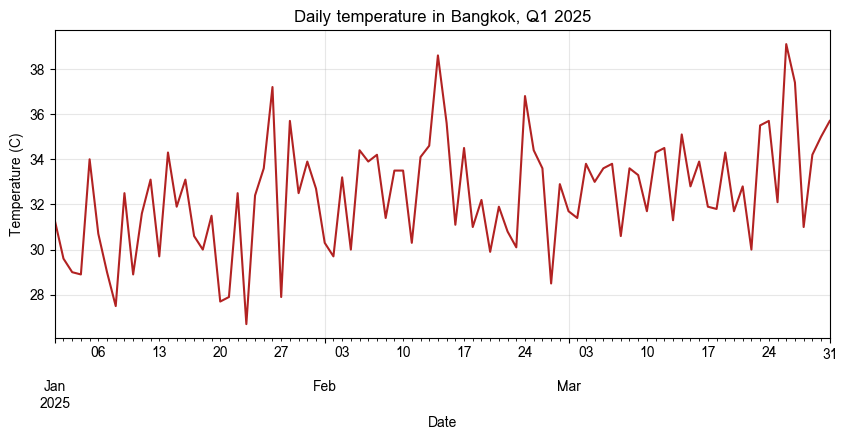

In [139]:
import matplotlib.pyplot as plt
import seaborn as sns

# แนวปฏิบัติที่แนะนำคือสร้าง figure และ axes ขึ้นก่อน แล้วส่ง ax เข้าไปในคำสั่ง plot
bangkok = df[df["city"] == "Bangkok"].sort_values("date")

fig, ax = plt.subplots(figsize=(10, 4))
bangkok.plot(x="date", y="temperature_c", ax=ax, color="firebrick", legend=False)
ax.set_title("Daily temperature in Bangkok, Q1 2025")
ax.set_xlabel("Date")
ax.set_ylabel("Temperature (C)")
ax.grid(alpha=0.3)
plt.show()

### ตัวอย่างที่ 2 กราฟแท่งแนวตั้งและแนวนอน

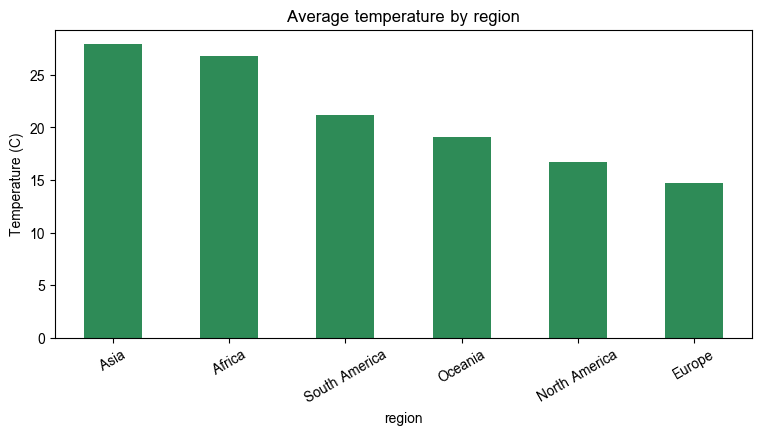

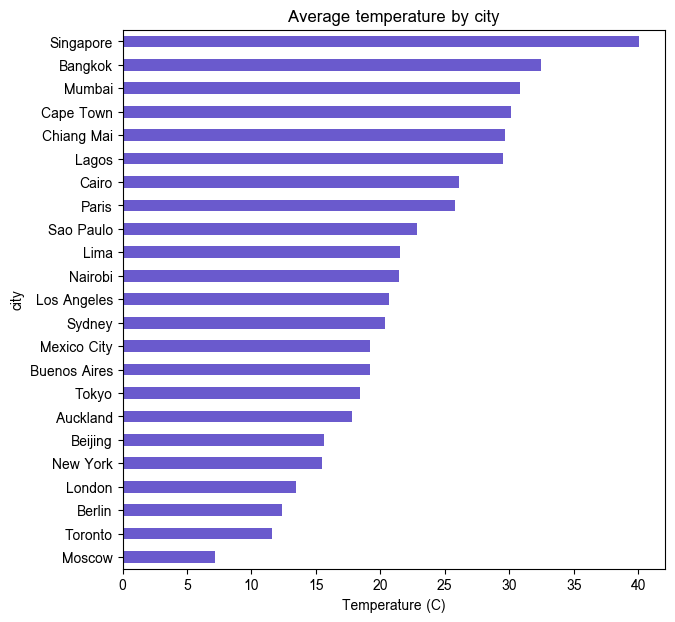

In [140]:
avg_by_region = df.groupby("region")["temperature_c"].mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 4))
avg_by_region.plot(kind="bar", ax=ax, color="seagreen")
ax.set_title("Average temperature by region")
ax.set_ylabel("Temperature (C)")
ax.tick_params(axis="x", rotation=30)
plt.show()

avg_by_city = df.groupby("city")["temperature_c"].mean().sort_values()
fig, ax = plt.subplots(figsize=(7, 7))
avg_by_city.plot(kind="barh", ax=ax, color="slateblue")
ax.set_title("Average temperature by city")
ax.set_xlabel("Temperature (C)")
plt.show()

### ตัวอย่างที่ 3 ฮิสโตแกรม กราฟจุด และ boxplot

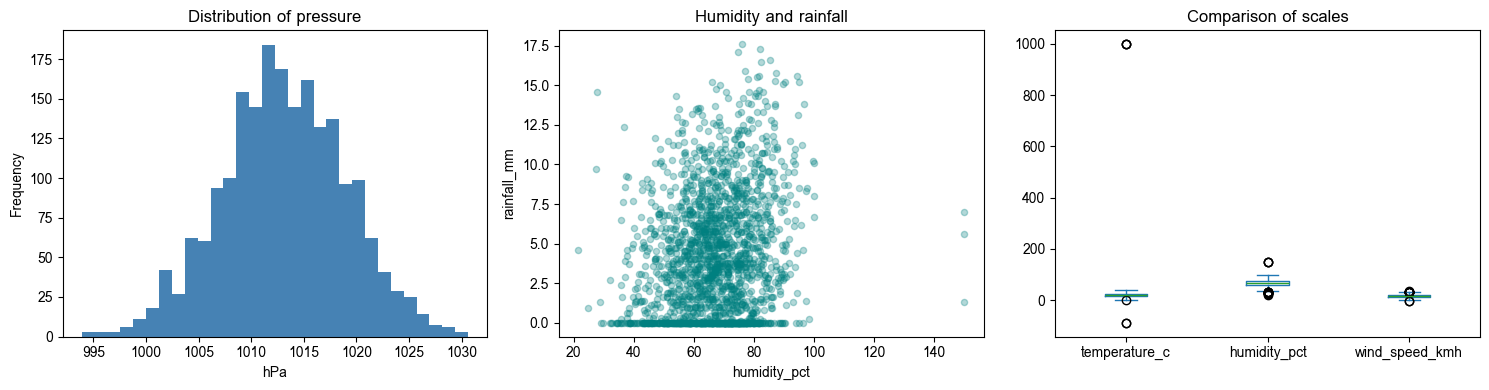

In [141]:
# การวางกราฟหลายรูปในภาพเดียว ให้สร้าง axes เป็นกริดแล้วส่งแต่ละช่องเข้าไปด้วยพารามิเตอร์ ax
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

df["pressure_hpa"].plot(kind="hist", bins=30, ax=axes[0], color="steelblue")
axes[0].set_title("Distribution of pressure")
axes[0].set_xlabel("hPa")

df.plot(kind="scatter", x="humidity_pct", y="rainfall_mm", alpha=0.3, ax=axes[1], color="teal")
axes[1].set_title("Humidity and rainfall")

df[["temperature_c", "humidity_pct", "wind_speed_kmh"]].plot(kind="box", ax=axes[2])
axes[2].set_title("Comparison of scales")

plt.tight_layout()
plt.show()

### ตัวอย่างที่ 4 กราฟวงกลมและการนับสัดส่วน

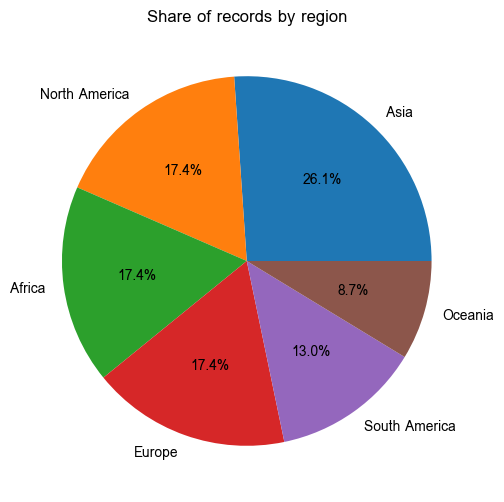

In [142]:
fig, ax = plt.subplots(figsize=(6, 6))
df["region"].value_counts().plot(kind="pie", ax=ax, autopct="%1.1f%%", ylabel="")
ax.set_title("Share of records by region")
plt.show()

### ตัวอย่างที่ 5 การวาดหลายคอลัมน์พร้อมกัน ด้วย `subplots` และ `secondary_y`

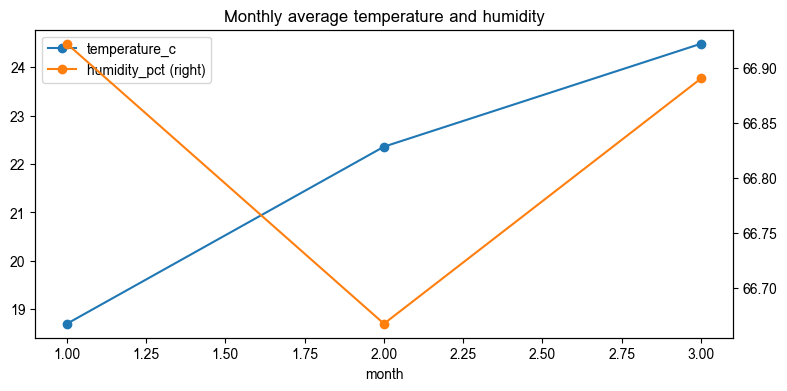

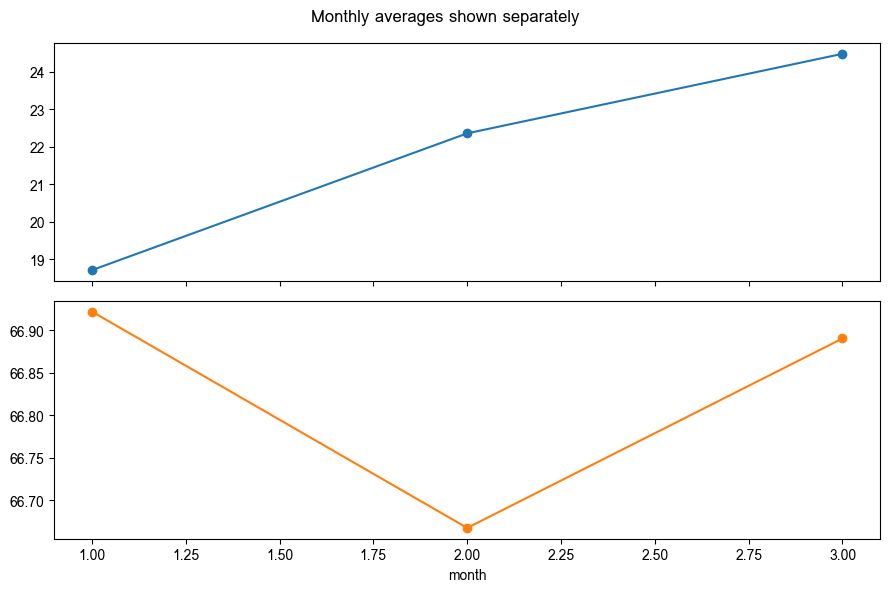

In [143]:
monthly = df.groupby("month")[["temperature_c", "humidity_pct"]].mean()

# secondary_y ใช้แกน y ด้านขวาสำหรับคอลัมน์ที่มีสเกลต่างกันมาก
fig, ax = plt.subplots(figsize=(9, 4))
monthly.plot(ax=ax, marker="o", secondary_y="humidity_pct")
ax.set_title("Monthly average temperature and humidity")
plt.show()

# subplots=True แยกแต่ละคอลัมน์ออกเป็นกราฟย่อย
axes = monthly.plot(subplots=True, layout=(2, 1), figsize=(9, 6), marker="o", legend=False)
plt.suptitle("Monthly averages shown separately")
plt.tight_layout()
plt.show()

### ตัวอย่างที่ 6 กราฟแท่งซ้อนจากตารางไขว้

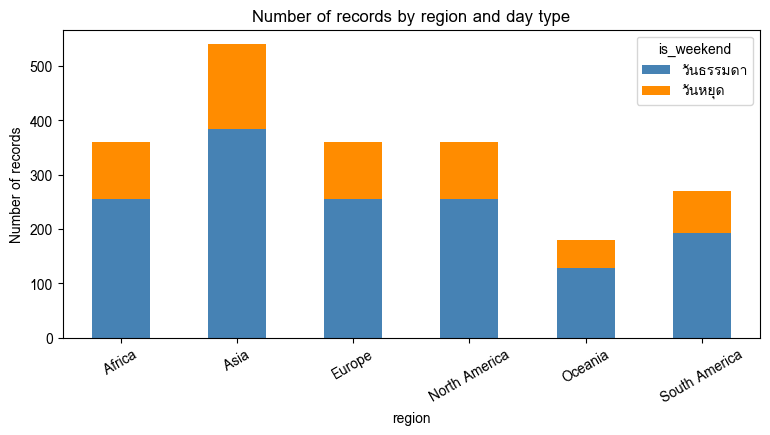

In [144]:
df["is_weekend"] = df["date"].dt.dayofweek >= 5
weekend_by_region = (df.groupby(["region", "is_weekend"]).size()
                       .unstack(fill_value=0)
                       .rename(columns={False: "วันธรรมดา", True: "วันหยุด"}))

fig, ax = plt.subplots(figsize=(9, 4))
weekend_by_region.plot(kind="bar", stacked=True, ax=ax, color=["steelblue", "darkorange"])
ax.set_title("Number of records by region and day type")
ax.set_ylabel("Number of records")
ax.tick_params(axis="x", rotation=30)
plt.show()

### ตัวอย่างที่ 7 กราฟเชิงสถิติด้วย seaborn

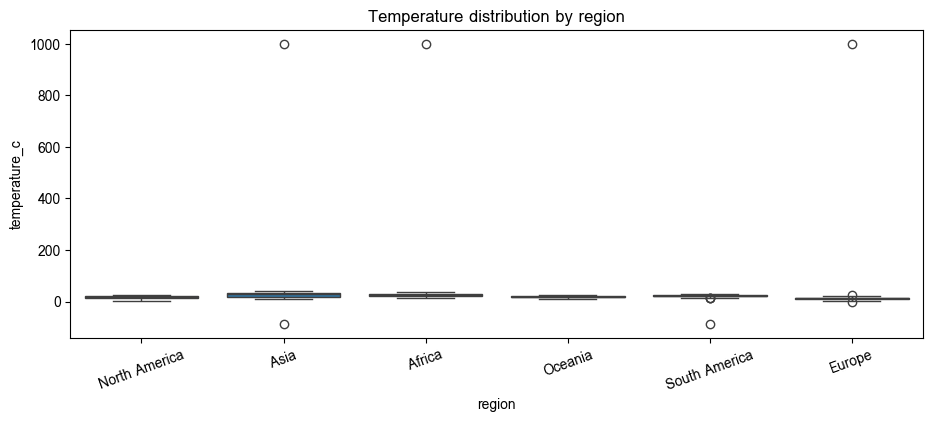

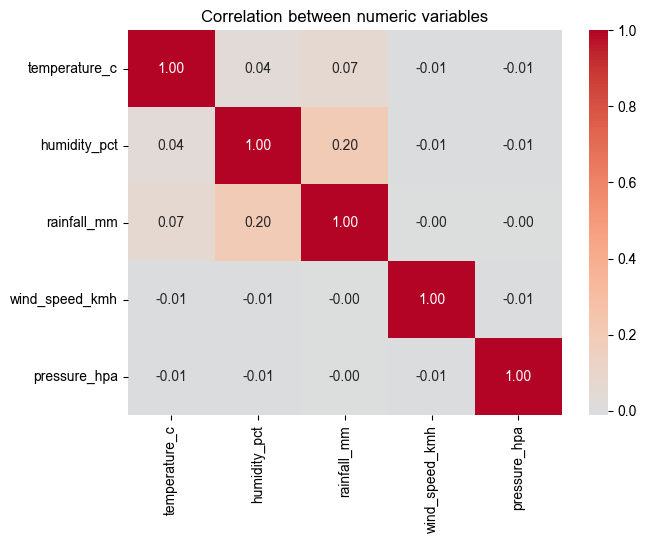

In [145]:
fig, ax = plt.subplots(figsize=(11, 4))
sns.boxplot(data=df, x="region", y="temperature_c", ax=ax)
ax.set_title("Temperature distribution by region")
ax.tick_params(axis="x", rotation=20)
plt.show()

numeric_cols = ["temperature_c", "humidity_pct", "rainfall_mm", "wind_speed_kmh", "pressure_hpa"]
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation between numeric variables")
plt.show()

### โจทย์ 17.1
สร้างกราฟสี่รูปจาก DataFrame โดยใช้ `.plot()` พร้อมกำหนดชื่อกราฟและชื่อแกนให้ครบทุกรูป

1. กราฟเส้นแสดงแนวโน้มอุณหภูมิรายวันของสามเมืองในรูปเดียวกัน พร้อมคำอธิบายสัญลักษณ์
2. กราฟแท่งแนวนอนแสดงปริมาณฝนรวมรายเมือง เรียงจากมากไปน้อย
3. ฮิสโตแกรมของ `wind_speed_kmh` โดยทดลองกำหนด `bins` สามค่าที่ต่างกันและอธิบายผลของการเลือก `bins`
4. กราฟจุดระหว่าง `population_millions` กับอุณหภูมิเฉลี่ยรายเมือง

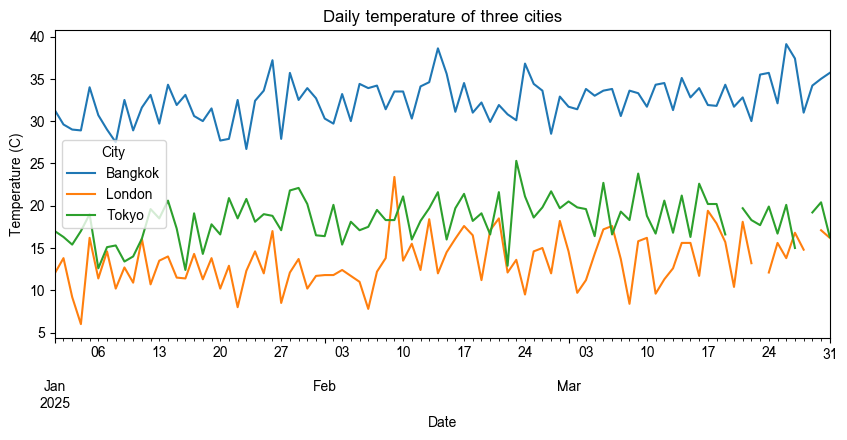

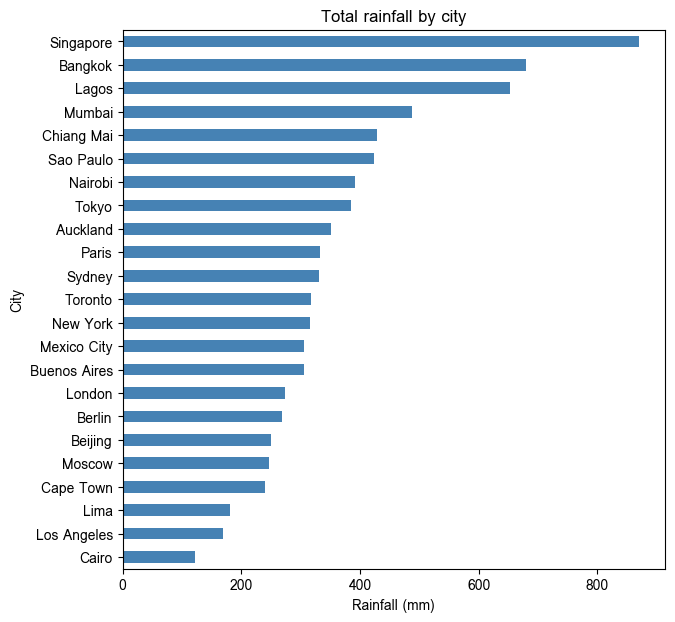

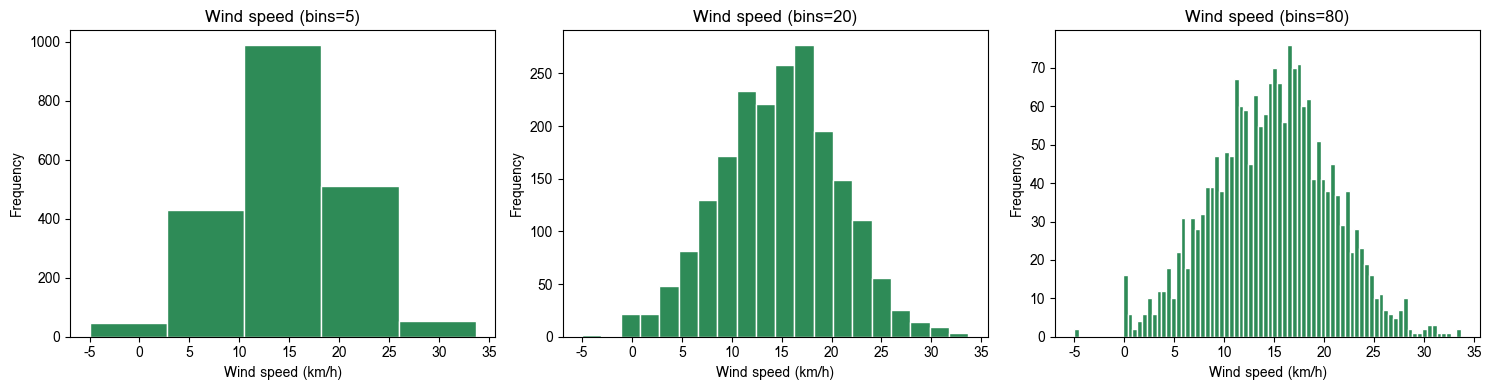

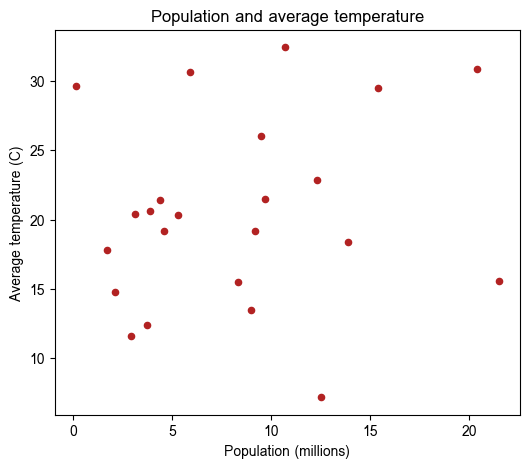


ผลของ bins: ค่า bins น้อย (5) ทำให้แท่งกว้าง รูปร่างเรียบแต่สูญเสียรายละเอียด อาจซ่อนหลายยอดไว้ในแท่งเดียว (underfit)
ค่า bins มาก (80) เห็นรายละเอียดมาก แต่แท่งแต่ละแท่งมีข้อมูลน้อย กราฟขรุขระและสะท้อนความผันผวนจากการสุ่มมากกว่าโครงสร้างจริง (overfit)
ค่าที่ปานกลาง (20) มักให้ภาพรวมของการกระจายที่อ่านง่ายที่สุด ควรลองหลายค่าก่อนสรุปรูปร่างของการกระจาย



In [146]:
# คำตอบข้อ 17.1
three = ["Bangkok", "Tokyo", "London"]
temp_wide = df[df["city"].isin(three)].pivot(index="date", columns="city", values="temp_ok")
rain_city = df.groupby("city")["rainfall_mm"].sum().sort_values()        # barh วาดจากล่างขึ้นบน จึงเรียงน้อย->มาก เพื่อให้มากที่สุดอยู่บนสุด
city_stats = weather_full.groupby("city").agg(population_millions=("population_millions", "first"),
                                              avg_temp=("temp_ok", "mean"))

def plot_line(ax):
    temp_wide.plot(ax=ax)
    ax.set_title("Daily temperature of three cities")
    ax.set_xlabel("Date"); ax.set_ylabel("Temperature (C)"); ax.legend(title="City")

def plot_barh(ax):
    rain_city.plot(kind="barh", ax=ax, color="steelblue")
    ax.set_title("Total rainfall by city")
    ax.set_xlabel("Rainfall (mm)"); ax.set_ylabel("City")

def plot_hist(ax, bins=30):
    df["wind_speed_kmh"].plot(kind="hist", bins=bins, ax=ax, color="seagreen", edgecolor="white")
    ax.set_title(f"Wind speed (bins={bins})")
    ax.set_xlabel("Wind speed (km/h)"); ax.set_ylabel("Frequency")

def plot_scatter(ax):
    city_stats.plot(kind="scatter", x="population_millions", y="avg_temp", ax=ax, color="firebrick")
    ax.set_title("Population and average temperature")
    ax.set_xlabel("Population (millions)"); ax.set_ylabel("Average temperature (C)")

fig, ax = plt.subplots(figsize=(10, 4)); plot_line(ax); plt.show()
fig, ax = plt.subplots(figsize=(7, 7)); plot_barh(ax); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, b in zip(axes, [5, 20, 80]):
    plot_hist(ax, bins=b)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(6, 5)); plot_scatter(ax); plt.show()

print("""
ผลของ bins: ค่า bins น้อย (5) ทำให้แท่งกว้าง รูปร่างเรียบแต่สูญเสียรายละเอียด อาจซ่อนหลายยอดไว้ในแท่งเดียว (underfit)
ค่า bins มาก (80) เห็นรายละเอียดมาก แต่แท่งแต่ละแท่งมีข้อมูลน้อย กราฟขรุขระและสะท้อนความผันผวนจากการสุ่มมากกว่าโครงสร้างจริง (overfit)
ค่าที่ปานกลาง (20) มักให้ภาพรวมของการกระจายที่อ่านง่ายที่สุด ควรลองหลายค่าก่อนสรุปรูปร่างของการกระจาย
""")

### โจทย์ 17.2
นำผลลัพธ์ของโจทย์ 17.1 มาจัดวางในภาพเดียวกันด้วย `plt.subplots(2, 2)` พร้อมกำหนดชื่อรวมของภาพด้วย `plt.suptitle()`

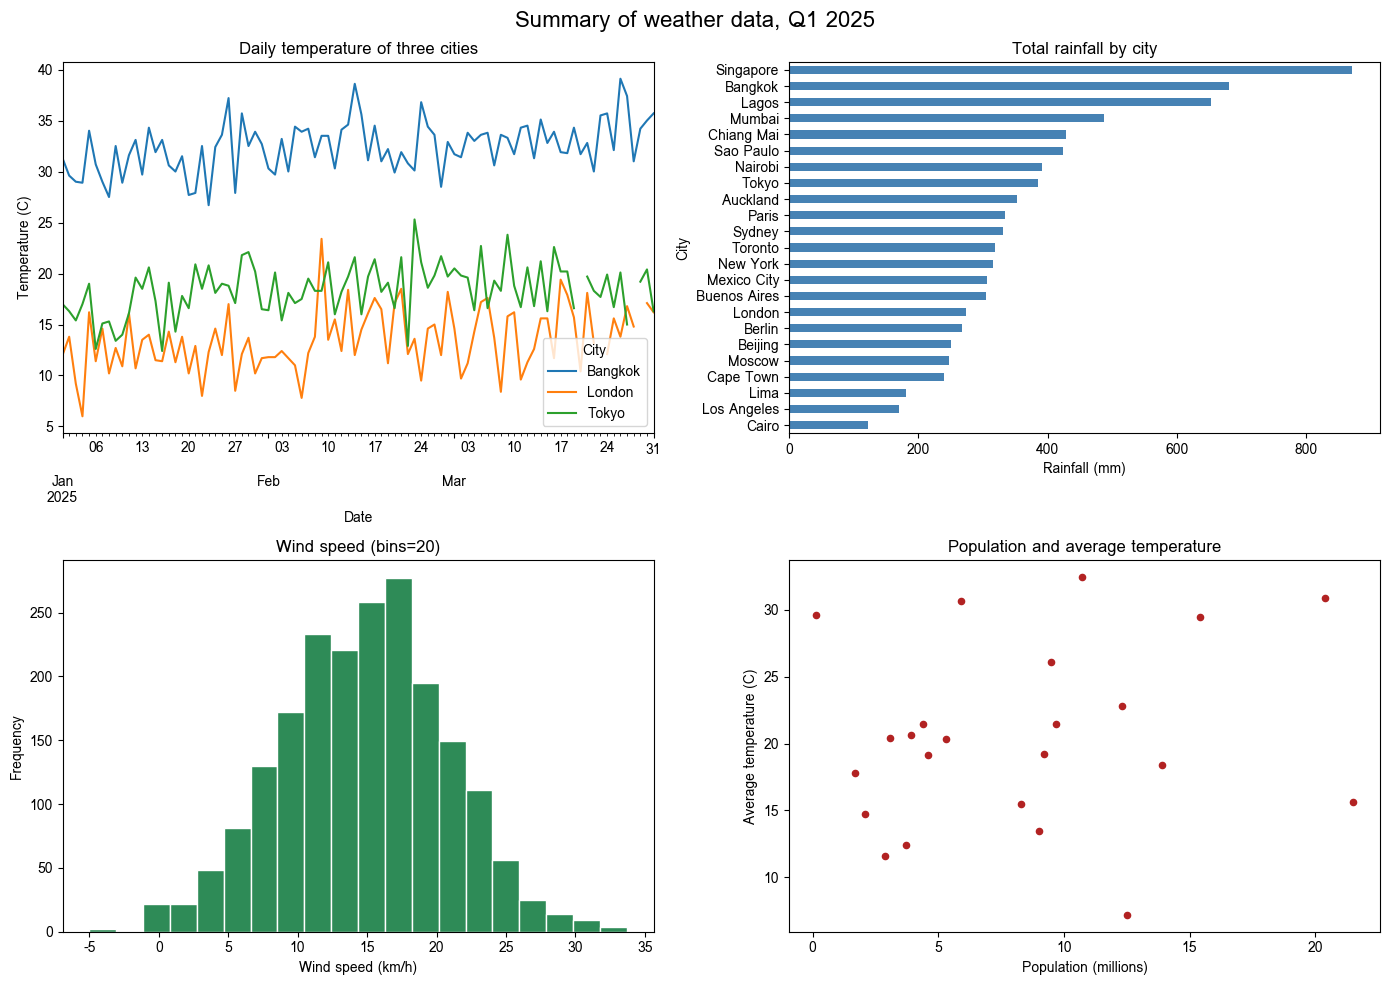

In [147]:
# คำตอบข้อ 17.2
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
plot_line(axes[0, 0])
plot_barh(axes[0, 1])
plot_hist(axes[1, 0], bins=20)
plot_scatter(axes[1, 1])
plt.suptitle("Summary of weather data, Q1 2025", fontsize=16)
plt.tight_layout()
plt.show()

### โจทย์ 17.3
สร้างกราฟแท่งซ้อนแสดงจำนวนวันในแต่ละช่วงปริมาณฝน โดยแบ่งช่วงด้วย `pd.cut()` และจำแนกตามภูมิภาค
จากนั้นสร้างกราฟแบบ `stacked=False` เปรียบเทียบ
**อธิบาย:** กราฟแท่งซ้อนเหมาะสมกว่าในกรณีใด และกราฟแท่งเรียงข้างกันเหมาะสมกว่าในกรณีใด

region       Africa  Asia  Europe  North America  Oceania  South America
rainfall_mm                                                             
0-1             119    85     134            124       47             95
1-5             111   148     128            129       56             95
5-10             88   203      73             84       60             52
>10              31    90      15             11        9             21


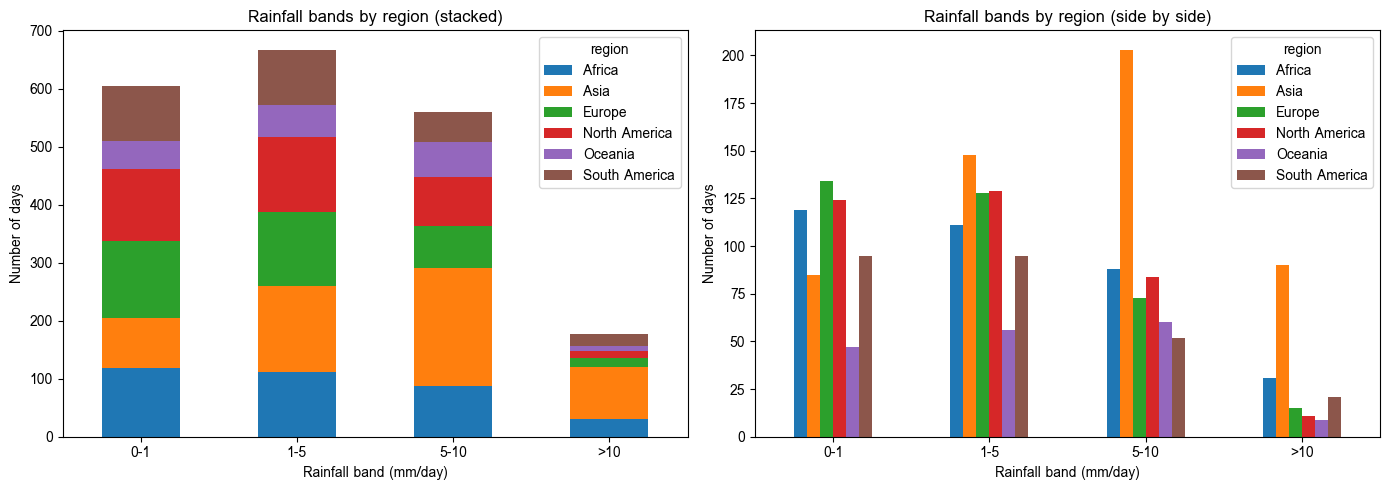


อธิบาย: กราฟแท่งซ้อน (stacked) เหมาะเมื่อสนใจ "ผลรวมทั้งหมดของแต่ละแท่ง" และสัดส่วนของส่วนประกอบภายในแท่งนั้น เช่น จำนวนวันทั้งหมดในแต่ละช่วงฝน
และแต่ละภูมิภาคมีส่วนเท่าใด (แต่เทียบค่าของภูมิภาคที่ไม่ได้อยู่ล่างสุดข้ามแท่งได้ยาก เพราะฐานไม่เท่ากัน)
กราฟแท่งเรียงข้างกัน (stacked=False) เหมาะเมื่อต้องการ "เปรียบเทียบค่าของแต่ละภูมิภาคโดยตรง" ในแต่ละช่วง เพราะทุกแท่งเริ่มจากศูนย์เหมือนกัน



In [148]:
# คำตอบข้อ 17.3
rain_band = pd.cut(df["rainfall_mm"], bins=[0, 1, 5, 10, np.inf],
                   labels=["0-1", "1-5", "5-10", ">10"], include_lowest=True)
band_ct = pd.crosstab(rain_band, df["region"])        # แถว = ช่วงฝน, คอลัมน์ = ภูมิภาค
print(band_ct)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
band_ct.plot(kind="bar", stacked=True, ax=axes[0])
axes[0].set_title("Rainfall bands by region (stacked)")
band_ct.plot(kind="bar", stacked=False, ax=axes[1])
axes[1].set_title("Rainfall bands by region (side by side)")
for ax in axes:
    ax.set_xlabel("Rainfall band (mm/day)"); ax.set_ylabel("Number of days"); ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

print("""
อธิบาย: กราฟแท่งซ้อน (stacked) เหมาะเมื่อสนใจ "ผลรวมทั้งหมดของแต่ละแท่ง" และสัดส่วนของส่วนประกอบภายในแท่งนั้น เช่น จำนวนวันทั้งหมดในแต่ละช่วงฝน
และแต่ละภูมิภาคมีส่วนเท่าใด (แต่เทียบค่าของภูมิภาคที่ไม่ได้อยู่ล่างสุดข้ามแท่งได้ยาก เพราะฐานไม่เท่ากัน)
กราฟแท่งเรียงข้างกัน (stacked=False) เหมาะเมื่อต้องการ "เปรียบเทียบค่าของแต่ละภูมิภาคโดยตรง" ในแต่ละช่วง เพราะทุกแท่งเริ่มจากศูนย์เหมือนกัน
""")

### โจทย์ 17.4
สร้างกราฟด้วย seaborn สองรูป ได้แก่ boxplot ของ `rainfall_mm` จำแนกตามภูมิภาคและแยกสีตาม `is_weekend`
และ heatmap ของสหสัมพันธ์ระหว่าง `temperature_c`, `humidity_pct`, `rainfall_mm` และ `population_millions`
พร้อมตีความผลที่ได้เป็นข้อความ

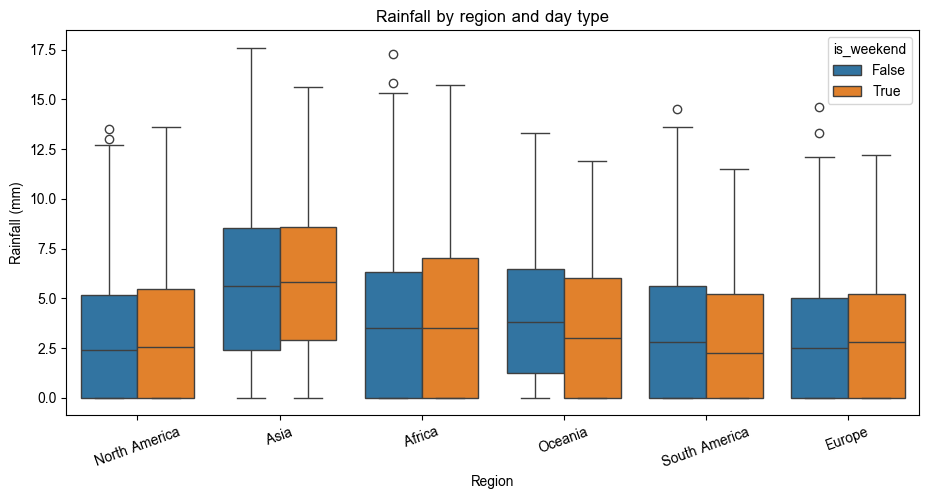

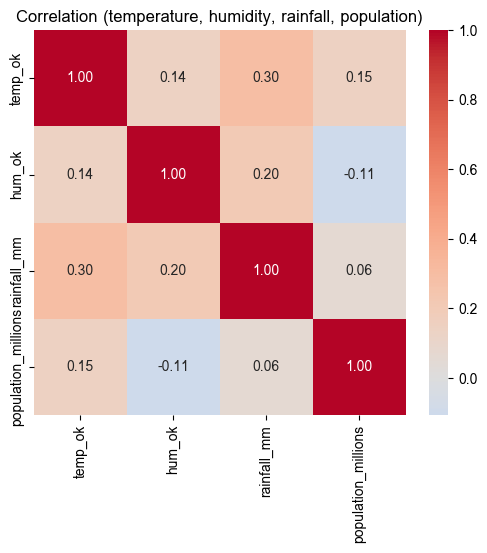

คู่ที่สหสัมพันธ์แรงที่สุด: temp_ok กับ rainfall_mm (r = 0.30)
population_millions กับ temp_ok: r = 0.15
population_millions กับ rainfall_mm: r = 0.06

มัธยฐานของฝน: วันธรรมดา = 3.50, วันหยุด = 3.60

การตีความ: boxplot ดูว่าการกระจายของฝนต่างกันระหว่างภูมิภาคอย่างไร และวันหยุดสุดสัปดาห์กับวันธรรมดาให้การกระจายใกล้เคียงกันหรือไม่
ฝนไม่ควรขึ้นกับวันของสัปดาห์ ถ้ากล่องสองสีของแต่ละภูมิภาคใกล้กัน แสดงว่าไม่มีผลของวันหยุด ความต่างเล็กน้อยเป็นความผันผวนจากการสุ่ม
heatmap: ตัวเลขที่ใกล้ 0 หมายถึงแทบไม่มีความสัมพันธ์เชิงเส้น ส่วน population_millions ค่าซ้ำตลอดทั้งวันของแต่ละเมือง
จึงมีข้อมูลอิสระจริงเพียงจำนวนเมืองเท่านั้น (ไม่ใช่จำนวนแถว) ควรระวังการตีความ และสหสัมพันธ์ไม่ได้แสดงเหตุและผล



In [149]:
# คำตอบข้อ 17.4
df["is_weekend"] = df["date"].dt.dayofweek >= 5

fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=df, x="region", y="rainfall_mm", hue="is_weekend", ax=ax)
ax.set_title("Rainfall by region and day type")
ax.set_xlabel("Region"); ax.set_ylabel("Rainfall (mm)")
ax.tick_params(axis="x", rotation=20)
plt.show()

corr_cols = ["temp_ok", "hum_ok", "rainfall_mm", "population_millions"]
corr = weather_full[corr_cols].corr()
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation (temperature, humidity, rainfall, population)")
plt.show()

# ตีความจากค่าที่คำนวณได้
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
strongest = pairs.abs().idxmax()
print(f"คู่ที่สหสัมพันธ์แรงที่สุด: {strongest[0]} กับ {strongest[1]} (r = {pairs[strongest]:.2f})")
print(f"population_millions กับ temp_ok: r = {corr.loc['population_millions', 'temp_ok']:.2f}")
print(f"population_millions กับ rainfall_mm: r = {corr.loc['population_millions', 'rainfall_mm']:.2f}")

wk = df.groupby("is_weekend")["rainfall_mm"].median()
print(f"\nมัธยฐานของฝน: วันธรรมดา = {wk.get(False, np.nan):.2f}, วันหยุด = {wk.get(True, np.nan):.2f}")

print("""
การตีความ: boxplot ดูว่าการกระจายของฝนต่างกันระหว่างภูมิภาคอย่างไร และวันหยุดสุดสัปดาห์กับวันธรรมดาให้การกระจายใกล้เคียงกันหรือไม่
ฝนไม่ควรขึ้นกับวันของสัปดาห์ ถ้ากล่องสองสีของแต่ละภูมิภาคใกล้กัน แสดงว่าไม่มีผลของวันหยุด ความต่างเล็กน้อยเป็นความผันผวนจากการสุ่ม
heatmap: ตัวเลขที่ใกล้ 0 หมายถึงแทบไม่มีความสัมพันธ์เชิงเส้น ส่วน population_millions ค่าซ้ำตลอดทั้งวันของแต่ละเมือง
จึงมีข้อมูลอิสระจริงเพียงจำนวนเมืองเท่านั้น (ไม่ใช่จำนวนแถว) ควรระวังการตีความ และสหสัมพันธ์ไม่ได้แสดงเหตุและผล
""")

---
## ข้อ 18 โจทย์ประยุกต์รวม

ให้ใช้ตารางที่รวมข้อมูลจากทั้ง 3 แหล่งและผ่านการทำความสะอาดแล้ว ตอบคำถามต่อไปนี้
แต่ละข้อต้องประกอบด้วย **ตารางหรือกราฟหนึ่งชิ้น** และ **ข้อสรุปเป็นข้อความสั้น ๆ**

**ข้อกำหนดเพิ่มเติม**

- ให้เขียนโปรแกรมในรูปแบบลำดับต่อเนื่องที่อ่านเข้าใจได้ ไม่ใช้ตัวแปรชั่วคราวจำนวนมากโดยไม่จำเป็น
- ห้ามใช้การวนซ้ำทีละแถว
- หากข้อสรุปขึ้นอยู่กับวิธีจัดการค่าว่างหรือค่าผิดปกติ ให้ระบุวิธีที่เลือกใช้ไว้ด้วย

1. ภูมิภาคใดมีสภาพอากาศแปรปรวนมากที่สุดในไตรมาสแรก เมื่อวัดจากส่วนเบี่ยงเบนมาตรฐานของอุณหภูมิรายวัน
   และความแปรปรวนดังกล่าวเกิดจากทุกเมืองในภูมิภาคนั้นเท่ากันหรือเกิดจากเมืองใดเมืองหนึ่งเป็นหลัก

In [150]:
# คำตอบข้อ 18.1
# วิธีจัดการ: ใช้ temp_ok (ค่า 999/-999 เป็นค่าว่าง) และข้ามค่าว่างเมื่อคำนวณ std
w = weather_full[["region", "city", "temp_ok"]].dropna()

region_std = (w.groupby("region")["temp_ok"].std().rename("std_temp")
                .sort_values(ascending=False).to_frame())
region_std["n_cities"] = w.groupby("region")["city"].nunique()
region_std["mean_within_city_std"] = w.groupby(["region", "city"])["temp_ok"].std().groupby("region").mean()
print(region_std.round(2))

top_region = region_std.index[0]
# ส่วนร่วมของแต่ละเมืองต่อผลรวมกำลังสองของความเบี่ยงเบนจากค่าเฉลี่ยของภูมิภาค
w = w.assign(dev2=(w["temp_ok"] - w.groupby("region")["temp_ok"].transform("mean")) ** 2)
ss_city = w.groupby(["region", "city"])["dev2"].sum()
share = ss_city.div(ss_city.groupby("region").sum(), level="region").rename("share_of_variation")
top_share = share.loc[top_region].sort_values(ascending=False)
equal_share = 1 / len(top_share)

print(f"\nส่วนร่วมของแต่ละเมืองในภูมิภาค {top_region} (ถ้าเท่ากันทุกเมืองจะเท่ากับ {equal_share:.1%})")
print(top_share.round(3).to_frame())

lead_city, lead_share = top_share.index[0], top_share.iloc[0]
print(f"\nข้อสรุป: ภูมิภาค {top_region} มี std ของอุณหภูมิรายวันสูงสุด ({region_std['std_temp'].iloc[0]:.2f})")
print(f"เมือง {lead_city} มีส่วนร่วม {lead_share:.1%} ซึ่งเป็น {lead_share / equal_share:.1f} เท่าของส่วนเฉลี่ย", end=" ")
print("-> เกิดจากเมืองนี้เป็นหลัก" if lead_share > 1.5 * equal_share else "-> กระจายใกล้เคียงกันหลายเมือง")
print("(std ภายในเมืองเฉลี่ย", round(region_std.loc[top_region, 'mean_within_city_std'], 2),
      "ต่างจาก std ของภูมิภาคทั้งภูมิภาค เพราะ std ของภูมิภาครวมความต่างระหว่างเมืองไว้ด้วย)")

               std_temp  n_cities  mean_within_city_std
region                                                 
Asia               7.16         6                  2.67
Africa             4.88         4                  2.79
North America      4.52         4                  2.87
Europe             4.07         4                  2.88
Oceania            3.08         2                  2.81
South America      3.06         3                  2.89

ส่วนร่วมของแต่ละเมืองในภูมิภาค Asia (ถ้าเท่ากันทุกเมืองจะเท่ากับ 16.7%)
            share_of_variation
city                          
Beijing                  0.399
Tokyo                    0.220
Bangkok                  0.144
Mumbai                   0.090
Singapore                0.084
Chiang Mai               0.063

ข้อสรุป: ภูมิภาค Asia มี std ของอุณหภูมิรายวันสูงสุด (7.16)
เมือง Beijing มีส่วนร่วม 39.9% ซึ่งเป็น 2.4 เท่าของส่วนเฉลี่ย -> เกิดจากเมืองนี้เป็นหลัก
(std ภายในเมืองเฉลี่ย 2.67 ต่างจาก std ของภูมิภาคทั้งภูมิภาค เพราะ std ของภูมิภาค

2. เมืองที่มีฝนตกหนักบ่อยที่สุด 5 อันดับแรกเมื่อวัดด้วยสัดส่วน ให้เปรียบเทียบกับผลที่ได้เมื่อวัดด้วยจำนวนวัน
   และอธิบายว่าเหตุใดจึงให้ผลต่างกัน

In [151]:
# คำตอบข้อ 18.2
heavy18 = (weather_full.assign(is_heavy=weather_full["rainfall_mm"] > 10)
                       .groupby("city")
                       .agg(heavy_days=("is_heavy", "sum"), n_obs=("rainfall_mm", "count")))
heavy18["heavy_ratio"] = heavy18["heavy_days"] / heavy18["n_obs"]

by_ratio = heavy18.nlargest(5, "heavy_ratio")
by_count = heavy18.nlargest(5, "heavy_days")
compare = pd.DataFrame({"by_ratio": by_ratio.index, "ratio": by_ratio["heavy_ratio"].round(3).to_numpy(),
                        "by_count": by_count.index, "days": by_count["heavy_days"].to_numpy()})
print(compare)

same = list(by_ratio.index) == list(by_count.index)
print("\nอันดับเหมือนกันทุกตำแหน่ง:", same)
print("เมืองที่ต่างกัน:", sorted(set(by_ratio.index) ^ set(by_count.index)) or "ไม่มี")
print(f"จำนวนวันที่มีข้อมูลฝนต่อเมือง: ต่ำสุด {heavy18['n_obs'].min()} สูงสุด {heavy18['n_obs'].max()}")
print("""
สรุป: จำนวนวันฝนหนักและสัดส่วนอาจให้อันดับต่างกัน เพราะจำนวนวันที่มีข้อมูลฝนของแต่ละเมืองไม่เท่ากัน (มีค่าว่าง)
เมืองที่ข้อมูลหายมากอาจนับวันได้น้อยลงทั้งที่ฝนหนักบ่อยจริง สัดส่วนจึงยุติธรรมกว่าเพราะหารด้วยจำนวนวันที่สังเกตได้จริง
(ถ้าทุกเมืองมีข้อมูลครบเท่ากันพอดี สองวิธีจะให้อันดับเหมือนกัน ยกเว้นกรณีค่าเสมอ)
""")

     by_ratio  ratio      by_count  days
0   Singapore  0.489     Singapore    44
1     Bangkok  0.264       Bangkok    23
2       Lagos  0.250         Lagos    22
3   Sao Paulo  0.125     Sao Paulo    11
4  Chiang Mai  0.106  Buenos Aires     9

อันดับเหมือนกันทุกตำแหน่ง: False
เมืองที่ต่างกัน: ['Buenos Aires', 'Chiang Mai']
จำนวนวันที่มีข้อมูลฝนต่อเมือง: ต่ำสุด 85 สูงสุด 90

สรุป: จำนวนวันฝนหนักและสัดส่วนอาจให้อันดับต่างกัน เพราะจำนวนวันที่มีข้อมูลฝนของแต่ละเมืองไม่เท่ากัน (มีค่าว่าง)
เมืองที่ข้อมูลหายมากอาจนับวันได้น้อยลงทั้งที่ฝนหนักบ่อยจริง สัดส่วนจึงยุติธรรมกว่าเพราะหารด้วยจำนวนวันที่สังเกตได้จริง
(ถ้าทุกเมืองมีข้อมูลครบเท่ากันพอดี สองวิธีจะให้อันดับเหมือนกัน ยกเว้นกรณีค่าเสมอ)



3. จำนวนประชากรของเมืองมีความสัมพันธ์กับอุณหภูมิหรือปริมาณฝนหรือไม่
   ให้คำนวณค่าสหสัมพันธ์ประกอบ พร้อมระบุข้อควรระวังในการตีความอย่างน้อยหนึ่งประการ

In [152]:
# คำตอบข้อ 18.3
city18 = weather_full.groupby("city").agg(population_millions=("population_millions", "first"),
                                          avg_temp=("temp_ok", "mean"),
                                          total_rain=("rainfall_mm", "sum"))

corr_pearson = city18.corr(method="pearson")
corr_spearman = city18.corr(method="spearman")
res = pd.DataFrame({
    "pearson": corr_pearson["population_millions"],
    "spearman": corr_spearman["population_millions"],
}).drop(index="population_millions").round(3)
print(res)

n = len(city18)
try:
    from scipy import stats
    t_crit = stats.t.ppf(0.975, n - 2)
    r_crit = t_crit / np.sqrt(n - 2 + t_crit ** 2)
    print(f"\nจำนวนเมือง n = {n} ต้องมี |r| > {r_crit:.2f} จึงจะมีนัยสำคัญที่ระดับ 5%")
except ImportError:
    print(f"\nจำนวนเมือง n = {n}")

print("""
ข้อสรุปและข้อควรระวัง:
 - ค่า r ที่คำนวณได้ระหว่างประชากรกับอุณหภูมิ/ฝนรวมแสดงความสัมพันธ์เชิงเส้นระดับเมือง ให้เทียบกับค่าวิกฤตด้านบนก่อนสรุปว่ามีความสัมพันธ์
 - มีข้อมูลอิสระเพียง n เมือง (ไม่ใช่ 2,070 แถว เพราะประชากรเป็นค่าคงที่ของเมือง) ตัวอย่างน้อย ค่า r จึงผันผวนมาก
 - เมืองใหญ่เพียงไม่กี่เมืองอาจดึงค่า Pearson ได้มาก (ค่าผิดปกติ) จึงเทียบกับ Spearman ซึ่งทนต่อค่าสุดโต่งกว่า
 - เมืองในชุดนี้ไม่ได้สุ่มมา และมีตัวแปรกวนอื่น เช่น ละติจูดและทวีป ที่ทำให้ทั้งอุณหภูมิและขนาดเมืองต่างกัน สหสัมพันธ์ไม่ใช่เหตุและผล
 - ข้อมูลครอบคลุมเพียงไตรมาสแรก ไม่ใช่ภูมิอากาศทั้งปี
""")

            pearson  spearman
avg_temp      0.159     0.230
total_rain    0.128     0.053

จำนวนเมือง n = 23 ต้องมี |r| > 0.41 จึงจะมีนัยสำคัญที่ระดับ 5%

ข้อสรุปและข้อควรระวัง:
 - ค่า r ที่คำนวณได้ระหว่างประชากรกับอุณหภูมิ/ฝนรวมแสดงความสัมพันธ์เชิงเส้นระดับเมือง ให้เทียบกับค่าวิกฤตด้านบนก่อนสรุปว่ามีความสัมพันธ์
 - มีข้อมูลอิสระเพียง n เมือง (ไม่ใช่ 2,070 แถว เพราะประชากรเป็นค่าคงที่ของเมือง) ตัวอย่างน้อย ค่า r จึงผันผวนมาก
 - เมืองใหญ่เพียงไม่กี่เมืองอาจดึงค่า Pearson ได้มาก (ค่าผิดปกติ) จึงเทียบกับ Spearman ซึ่งทนต่อค่าสุดโต่งกว่า
 - เมืองในชุดนี้ไม่ได้สุ่มมา และมีตัวแปรกวนอื่น เช่น ละติจูดและทวีป ที่ทำให้ทั้งอุณหภูมิและขนาดเมืองต่างกัน สหสัมพันธ์ไม่ใช่เหตุและผล
 - ข้อมูลครอบคลุมเพียงไตรมาสแรก ไม่ใช่ภูมิอากาศทั้งปี



4. เดือนใดของแต่ละภูมิภาคที่ควรหลีกเลี่ยงการเดินทางมากที่สุด
   ให้กำหนดเกณฑ์การตัดสินใจจากข้อมูลที่มีอยู่ และอธิบายเหตุผลของการเลือกเกณฑ์ดังกล่าว

In [153]:
# คำตอบข้อ 18.4
# เกณฑ์: "ความเสี่ยงต่อการเดินทาง" = ค่าเฉลี่ยของสัดส่วนวันที่มีสภาพอากาศไม่เอื้อ 3 แบบ
#   1) ฝนตกหนัก (ฝน > 10 มม.)  2) ร้อนชื้น (อุณหภูมิ > 30 และความชื้น > 70)  3) ลมแรง (> 25 กม./ชม.)
# ใช้สัดส่วนวัน (ไม่ใช่ค่าเฉลี่ยตัวแปร) เพราะตีความตรงกับประสบการณ์ผู้เดินทาง และทั้ง 3 ตัวชี้วัดอยู่ในสเกลเดียวกัน (0 ถึง 1)
# ให้น้ำหนักเท่ากัน เพราะไม่มีข้อมูลที่บอกว่าปัจจัยใดสำคัญกว่า (ตรวจความไวของผลด้านล่าง)
flags = weather_full.assign(
    heavy_rain=weather_full["rainfall_mm"] > 10,
    hot_humid=(weather_full["temp_ok"] > 30) & (weather_full["hum_ok"] > 70),
    windy=weather_full["wind_speed_kmh"] > 25,
)
monthly_risk = flags.groupby(["region", "month"])[["heavy_rain", "hot_humid", "windy"]].mean()
monthly_risk["risk"] = monthly_risk[["heavy_rain", "hot_humid", "windy"]].mean(axis=1)

worst = monthly_risk.loc[monthly_risk.groupby("region")["risk"].idxmax()].reset_index()
print("เดือนที่ควรหลีกเลี่ยงมากที่สุดของแต่ละภูมิภาค")
print(worst.round(3).to_string(index=False))

# ตรวจความไวของผลต่อน้ำหนัก: ให้ฝนสำคัญที่สุด (0.5, 0.25, 0.25)
w_alt = monthly_risk["heavy_rain"] * 0.5 + monthly_risk["hot_humid"] * 0.25 + monthly_risk["windy"] * 0.25
alt_worst = w_alt.groupby("region").idxmax().map(lambda t: t[1])
same = (alt_worst.sort_index() == worst.set_index("region")["month"].sort_index())
print("\nเปลี่ยนน้ำหนักแล้วเดือนที่เลือกยังเหมือนเดิมกี่ภูมิภาค:", int(same.sum()), "จาก", len(same))
print("ข้อจำกัด: ข้อมูลมีเพียง 3 เดือน (ไตรมาสแรก) เดือนที่เลือกจึงเป็นเดือนที่แย่ที่สุด 'ในช่วงนี้' เท่านั้น")

เดือนที่ควรหลีกเลี่ยงมากที่สุดของแต่ละภูมิภาค
       region  month  heavy_rain  hot_humid  windy  risk
       Africa      3       0.081      0.153  0.024 0.086
         Asia      2       0.226      0.268  0.018 0.171
       Europe      3       0.056      0.000  0.032 0.030
North America      3       0.024      0.000  0.056 0.027
      Oceania      3       0.097      0.000  0.000 0.032
South America      2       0.083      0.000  0.036 0.040

เปลี่ยนน้ำหนักแล้วเดือนที่เลือกยังเหมือนเดิมกี่ภูมิภาค: 5 จาก 6
ข้อจำกัด: ข้อมูลมีเพียง 3 เดือน (ไตรมาสแรก) เดือนที่เลือกจึงเป็นเดือนที่แย่ที่สุด 'ในช่วงนี้' เท่านั้น


---

<center>จบแล้ว ขอแสดงความยินดีกับทุกคน

<center>> เขียนเองหนึ่งบรรทัด ได้ความเข้าใจมากกว่าอ่านผ่านตาสิบบรรทัด
> One line you write yourself teaches more than ten you only read.

> คนที่จัดการข้อมูลสองพันแถวได้อย่างสะอาดหมดจด คือคนเดียวกับที่จะจัดการข้อมูลสองล้านแถวได้อย่างมั่นใจ
> Whoever handles two thousand rows with care will handle two million with confidence.

<center>❤️❤️❤️❤️❤️ Keep Learning ❤️❤️❤️❤️❤️